# Demo: the digital Twin on one public session, and Fig. 3

This notebook is the paper's runnable demo. It needs only this repository and one public recording
session, **Dataset_1_32622_231009** (bat 32622, indoor flight room; 95 units, 78 flights). It runs
the code of [`figures.ipynb`](figures.ipynb) on that session: Fig. 1B–F for this session, then Fig. 3
and Extended Data Fig. 8. The models behind Fig. 1 are the Twin, two Poisson GLMs (encoding), a
naïve-Bayes decoder and CEBRA (decoding).

**`MODELS` (cell `demo_mode`) picks where the models come from:**

| `MODELS` | Models | Default |
|---|---|---|
| `'paper'` | The paper's models, trained on all 17 sessions and committed under `notebooks/out/`. No training. **Fig. 3A–L reproduce the paper exactly.** | without a GPU |
| `'retrain'` | Every model retrained from scratch on this session, with the same train-if-missing code as `figures.ipynb`. | with a CUDA GPU |
| `'cached'` | The single-session models that `'retrain'` produced on our GPU (`notebooks/out/demo_weights/`). | — |

**What matches the paper.**

- **Fig. 3A–I and Extended Data Fig. 8:** exact in every mode. They use only the recorded spikes and
  flight paths, and splits are seeded per session, so they give the same cells, statistics and
  *P* values as the legend.
- **Fig. 3J–L:** exact with `'paper'`.
  - J–K use the paper's Twin and the PCA basis it was plotted in.
  - L–M pool 15 sessions. This session's values are recomputed and checked against the paper's
    committed results, and the other sessions come from those results.
  - With the single-session models, J–M are this session's own version and differ from the paper
    (see section 3).
- **Fig. 1B–F:** this session's values. The paper's Fig. 1 pools 17 sessions.
- The last section lists every figure that cannot be reproduced from this session.

`figures.ipynb` needs all 17 recordings. Everything this notebook trains, caches or draws goes to
`notebooks/out/demo/`, which is emptied at the start of every run.

**Run time:** 4–5 min CPU-only with `'paper'` or `'cached'` (Intel Core i9-13900K, using 8–24
cores), and 7 min with `'retrain'` on an NVIDIA RTX 3090. The outputs saved in this notebook are from
a CPU-only `'paper'` run.

**To run:** download the session (see the README), set `DATA_DIR` in the next cell, and run all cells
from `notebooks/`.

In [1]:
# === Where the data live (the only settings to change) ===
# DATA_DIR is the folder holding `Dataset_1_32622_231009/` and `To_transfer/` from the figshare
# download. Set it here or with the DIGITALBAT_DEMO_DATA environment variable. The default,
# `<repo>/data`, is ignored by git. Paths are OS-independent (pathlib); forward slashes work on Windows.
# To run on your own recordings, list them in SESSIONS (same layout; see the README).
import os
from pathlib import Path

DATA_DIR = Path(os.environ.get('DIGITALBAT_DEMO_DATA', '../data')).expanduser().resolve()
SESSIONS = ['Dataset_1_32622_231009']


def session_files(sn):
    """The files the code reads for one session (glob patterns under DATA_DIR). For the demo
    session these are ~81 MB; the rest of the download (LFP, ripples, Kilosort output) is unused."""
    return [f'{sn}/Extracted_Behavior_*.mat', f'{sn}/IMU_data.mat', f'{sn}/merges_{sn}.mat',
            f'To_transfer/out_Gunits_probe*_{sn}_with_metrics.mat']


_missing = [p for sn in SESSIONS for p in session_files(sn) if not list(DATA_DIR.glob(p))]
if _missing:
    raise FileNotFoundError(f'DATA_DIR = {DATA_DIR} has no match for:\n  ' + '\n  '.join(_missing))
print(f'data: {DATA_DIR} | sessions: {SESSIONS}')

data: <DATA_DIR> | sessions: ['Dataset_1_32622_231009']


In [2]:
# === Imports and shared settings (figures.ipynb cell `placeholder`) ===
# Two differences from figures.ipynb: the repo root goes on sys.path directly rather than through
# machine_paths, and in every cell copied below, paths under ./out/ point to ./out/demo/. The
# paper's committed models and results are read only where a `# DEMO:` line says so, in 'paper' mode.
import sys
import pickle
import hashlib

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import optuna
from sklearn.neighbors import KNeighborsRegressor

REPO = Path.cwd().parent                     # the notebook runs from notebooks/
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import cebra, cebra.data, cebra.models, cebra.solver

from digitalbat.utility.utils import (
    set_random_state, bat_palette, parse_bat, corr,
    poisson_fde_population, poisson_fde_population_filtered,
)
import notebook_helpers as nh
import plotting_helpers as ph

ph.set_pub_style()
ph.FIG_DIR = Path('out/demo/figures')

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# Canonical display name for the joint encode/decode transformer (used in all labels).
OUR_MODEL = 'Twin'

device: cpu


In [3]:
# === Load the session(s) (figures.ipynb cell `215a54ff`, with SESSIONS instead of the paper's 17) ===
from digitalbat.datasets.defaults import make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders

session_names = list(SESSIONS)
# The loader joins parent_folder to file names by string concatenation: keep the trailing slash.
data_config = make_data_config(session_names=session_names,
                               parent_folder=DATA_DIR.as_posix() + '/')
bin_width = data_config['bin_width']

# Splits are drawn per session with a fixed seed, so these are the paper's train / valid / test
# flights for this session.
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

bats = ph.bat_order()
BAT_PALETTE = ph.bat_pal()
n_neurons_total = sum(unit_num_dict.values())
print(pd.DataFrame({sp: {sn: len(ld.dataset) for sn, ld in d.items()} for sp, d in dataloaders.items()})
      .assign(neurons=pd.Series(unit_num_dict)).rename_axis('flights').to_string())

  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
                        train  valid  test  neurons
flights                                            
Dataset_1_32622_231009     54     11    13       95


---
## 1. The models: the paper's, or retrained on this session

The cell below sets `MODELS`, and its printed banner states which models this run uses:

- **`'paper'`** (default without a GPU): the paper's 17-session models.
  - **Twin:** loaded whole.
  - **GLMs:** every parameter is per session, so this session's part of each GLM checkpoint is
    exactly the paper's model for this session.
  - **Naïve-Bayes decoder:** fit to this session with the paper's hyperparameters.
  - **CEBRA:** the paper's unified CEBRA spans all 17 sessions' neurons, so it cannot run on one
    session; this session's rows of its committed decode are used instead.
- **`'retrain'`** (default with a CUDA GPU): every model fit from scratch to this session's 54
  training flights.
- **`'cached'`:** the models that `'retrain'` produced on an NVIDIA RTX 3090, committed in
  `out/demo_weights/`.

Everything after loading or training (evaluation, Fig. 1, Fig. 3) is computed in every mode. Models
are selected on the 11 validation flights and scored on the 13 test flights.

When retraining, models are fit as follows.

- **Twin and CEBRA:** use the hyperparameters selected by the paper's searches over 17 sessions.
  Rerunning those searches would take hours.
- **GLMs and naïve-Bayes decoder:** their small searches (GLM weight decay, naïve-Bayes binning)
  rerun on this session through the same code `figures.ipynb` uses.

In [4]:
# === Which models: the paper's, retrained here, or cached? ===
#   'paper'   : the paper's 17-session models, committed under out/ (no training). Fig. 3A-L then
#               reproduce the paper exactly. Default without a GPU.
#   'retrain' : every model trained from scratch on this session. Default with a CUDA GPU
#               (also runs on CPU, more slowly).
#   'cached'  : the single-session models 'retrain' produced on our GPU (out/demo_weights/).
# Set MODELS here, or with the DIGITALBAT_DEMO_MODELS environment variable for headless runs.
# Every run starts from an empty out/demo/. The train-if-missing cells below train whatever they
# do not find there, so this cell puts in place the models they should load instead.
import shutil

MODELS = os.environ.get('DIGITALBAT_DEMO_MODELS', 'retrain' if torch.cuda.is_available() else 'paper')
assert MODELS in ('paper', 'retrain', 'cached'), MODELS
DEMO_OUT, DEMO_WEIGHTS = Path('out/demo'), Path('out/demo_weights')
shutil.rmtree(DEMO_OUT, ignore_errors=True)
DEMO_OUT.mkdir(parents=True)
if MODELS == 'cached':
    shutil.copytree(DEMO_WEIGHTS, DEMO_OUT, dirs_exist_ok=True)
elif MODELS == 'paper':
    # Naïve Bayes: the paper's hyperparameter search (the decoder itself is fit to this session).
    (DEMO_OUT / 'nb_decoder').mkdir()
    for _n in (2, 3):
        shutil.copy2(f'out/nb_decoder/nb_decoder_{_n}d_seed_1_optuna.pkl', DEMO_OUT / 'nb_decoder')
    # GLMs: every parameter is per session, so this session's readouts of each paper checkpoint
    # are the paper's model for this session. (The Twin and CEBRA are handled in their cells.)
    (DEMO_OUT / 'bat_glm').mkdir()
    for _f in ('bat_glm_position_seed_1_optuna_acc50_zbasis17.pth',
               'bat_glm_joint_seed_1_optuna_acc50_zbasis17.pth'):
        _sd = torch.load(f'out/bat_glm/{_f}', map_location='cpu')
        torch.save({k: v for k, v in _sd.items()
                    if 'Dataset_' not in k or any(f'.{s}.' in f'.{k}.' for s in session_names)},
                   DEMO_OUT / 'bat_glm' / _f)
MODE_NOTE = {
    'paper': "PAPER MODELS: the paper's models, trained on all 17 sessions (out/joint, out/bat_glm,\n"
             "out/nb_decoder, out/cebra). Nothing is trained in this run.",
    'retrain': 'RETRAIN: all five models are trained from scratch on this session in this run.',
    'cached': f'CACHED SINGLE-SESSION MODELS: loaded from {DEMO_WEIGHTS.as_posix()}/ (trained on this '
              'session by this notebook\non an RTX 3090). Nothing is trained in this run.',
}[MODELS]
print('=' * 96 + '\n' + MODE_NOTE + '\n' + '=' * 96)

PAPER MODELS: the paper's models, trained on all 17 sessions (out/joint, out/bat_glm,
out/nb_decoder, out/cebra). Nothing is trained in this run.


In [5]:
# === The Twin: the paper's 17-session model, or retrained on this session (see `demo_mode`) ===
# 'paper' loads the checkpoint figures.ipynb uses (cell `de9a3bd3`), built with all 17 sessions'
# read-in/read-out heads (sizes taken from the checkpoint); only this session's heads are used.
# 'retrain' fits the same architecture and training recipe to this session alone, from scratch:
#   * hyperparameters: the best trial of the paper's Optuna study (joint-encode-decode.ipynb §6.10;
#     the same values the checkpoint name encodes: L4_d64_ff64_lam0.68_pw0.36_we2.8_wd2.2_wa0.31);
#   * masking schemes: encode / decode / cross, sampled with weights w_encode / w_decode / w_aux;
#   * up to TWIN_EPOCHS epochs with early stopping (patience 40), keeping the validation
#     Pareto-front checkpoint that maximises 0.5 * FDE / 0.1 - 0.5 * error / 0.3 m.
from digitalbat.models.joint import JointMaskedTransformer
from digitalbat.training.joint_trainer import train_joint, ERR_REF, FDE_REF

TWIN_HP = dict(num_layers=4, latent_dim=64, ff_dim=64, num_heads=4,
               dropout=0.2852299690890039, lr=0.0026857694532344337,
               weight_decay=0.0013050407996424373, w_encode=2.8342359293209456,
               w_decode=2.197246529313443, w_aux=0.3118820531900439,
               lam=0.6816384595663993, pos_weight=0.36126826213721663)
TWIN_SCHEMES = ['encode', 'decode', 'cross']
TWIN_EPOCHS = 1000
INPUT_TRANSFORM = 'identity'
PAPER_JOINT_CKPT = ('./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity'
                    '_we2.8_wd2.2_wa0.31_n17.pth')
JOINT_CKPT = PAPER_JOINT_CKPT if MODELS == 'paper' else './out/demo/joint/twin_demo.pth'
_TWIN_HIST = './out/demo/joint/twin_demo_hist.pkl'


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


_twin_units = dict(unit_num_dict)
if MODELS == 'paper':                   # every session's head sizes, from the checkpoint itself
    _paper_sd = torch.load(JOINT_CKPT, map_location=device)
    _twin_units = {k.split('.')[1]: v.shape[0] for k, v in _paper_sd.items()
                   if k.startswith('spike_readout.') and k.endswith('.weight')}
    assert all(_twin_units.get(s) == n for s, n in unit_num_dict.items()), 'unit counts differ'
session_to_room = {s: joint_session_room(s) for s in _twin_units}
set_random_state(seed)
joint_model = JointMaskedTransformer(
    _twin_units, behavior_dim=3, input_transform=INPUT_TRANSFORM, session_to_room=session_to_room,
    **{k: TWIN_HP[k] for k in ('num_layers', 'latent_dim', 'num_heads', 'ff_dim', 'dropout')}
).to(device)
twin_hist = None
if MODELS == 'paper':
    joint_model.load_state_dict(_paper_sd)
    print(f"PAPER MODEL, not retrained: the 17-session Twin {os.path.basename(JOINT_CKPT)}")
elif MODELS == 'cached':
    joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
    twin_hist = pd.read_pickle(_TWIN_HIST)
    print(f'CACHED SINGLE-SESSION MODEL, not retrained: {JOINT_CKPT} (curves are from its GPU training run)')
else:
    joint_model, twin_best, _h = train_joint(
        joint_model, dataloaders, device, meta_info_dict, seed=seed, n_epochs=TWIN_EPOCHS,
        lr=TWIN_HP['lr'], weight_decay=TWIN_HP['weight_decay'], lam=TWIN_HP['lam'],
        pos_weight=TWIN_HP['pos_weight'], schemes=TWIN_SCHEMES,
        scheme_p=[TWIN_HP['w_encode'], TWIN_HP['w_decode'], TWIN_HP['w_aux']],
        select='joint', fde_weight=0.5, err_ref=ERR_REF, fde_ref=FDE_REF,
        early_stopping_patience=40)
    os.makedirs(os.path.dirname(JOINT_CKPT), exist_ok=True)
    torch.save(joint_model.state_dict(), JOINT_CKPT)
    twin_hist = pd.DataFrame(_h).rename_axis('epoch').reset_index()
    twin_hist.to_pickle(_TWIN_HIST)
    print(f"trained {len(twin_hist)} epochs; selected checkpoint: validation decoding error "
          f"{twin_best['err']:.3f} m, median Poisson FDE {twin_best['fde']:.3f}")
joint_model = joint_model.eval()
joint_loaders, joint_meta = dataloaders, meta_info_dict

# Validation curves of a single-session training run: median 3-D decoding error and median
# per-neuron Poisson FDE per epoch.
if twin_hist is not None:
    fig_tw, ax_tw = plt.subplots(1, 2, figsize=(9, 3))
    sns.lineplot(twin_hist, x='epoch', y='val_err_m', ax=ax_tw[0], color='k')
    sns.lineplot(twin_hist, x='epoch', y='val_fde', ax=ax_tw[1], color='k')
    ax_tw[0].set_ylabel('Decoding error (m)'); ax_tw[1].set_ylabel('Poisson FDE')
    fig_tw.suptitle('Twin training on the demo session (validation flights)')
    sns.despine(fig_tw); fig_tw.tight_layout(); plt.show()

PAPER MODEL, not retrained: the 17-session Twin joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth


In [6]:
# [figures.ipynb cell `63e8be8c`]
# Encode-arm adapter + per-neuron encode-metric helper, from the package
# (digitalbat.models.joint), keeping this notebook focused on the figures.
from digitalbat.models.joint import JointEncoderAdapter, encode_eval_records

bat_former = JointEncoderAdapter(joint_model, unit_num_dict).to(device).eval()

In [7]:
# [figures.ipynb cell `4c999546`]
# === Training utilities: load-or-train for every model ===
import optuna
from copy import deepcopy
from digitalbat.models.former_defaults import make_trainer_config
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.models.glm import coupling_group_penalty

optuna.logging.set_verbosity(optuna.logging.WARNING)
from tqdm import tqdm as _tqdm


def _optuna_progress(study, trial):
    """Print one line after every Optuna trial so searches are never silent."""
    v = f'{trial.value:.4f}' if trial.value is not None else str(trial.value)
    try:
        best = f'{study.best_value:.4f}'
    except ValueError:
        best = 'n/a'
    print(f'    [optuna] trial {trial.number + 1} value={v} best={best} params={trial.params}', flush=True)
FORCE_RETRAIN = False
GLM_N_TRIALS, GLM_WD_RANGE, GLM_ALPHA_RANGE = 10, (1e-4, 50.0), (1e-4, 1e2)
NB_N_TRIALS = 20


def _exists(path):
    return (not FORCE_RETRAIN) and os.path.exists(path)


# --- GLM trainer (Poisson NLL; coupling params get lower LR + group-lasso) ---
def _val_fde_glm(model, flight_cluster=None):
    model.eval(); scores = []
    is_joint = getattr(model, 'joint', False)
    with torch.no_grad():
        for s, sd in dataloaders['valid'].items():
            yt, yp = [], []
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                m = b.mask.to(device)
                out = model(s, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
                v = m == 1.0
                yt.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
            scores.append(poisson_fde_population(np.vstack(yt), np.vstack(yp)))
    return float(np.nanmedian(np.hstack(scores)))


def train_glm(model, alpha=0.0, weight_decay=1.0, flight_cluster=None, n_epochs=1000,
              lr=1e-2, coup_lr=1e-3, grad_clip=5.0, patience=20, label=''):
    model = model.to(device)
    loss_fn = nn.PoissonNLLLoss(log_input=False).to(device)
    is_joint = getattr(model, 'joint', False); use_coup = getattr(model, 'use_coup', False)
    coup_ids = set(id(p) for p in model.coup_weights.parameters()) if use_coup else set()
    opt = torch.optim.AdamW(
        [{'params': [p for p in model.parameters() if id(p) not in coup_ids], 'weight_decay': weight_decay, 'lr': lr},
         {'params': [p for p in model.parameters() if id(p) in coup_ids], 'weight_decay': 0.0, 'lr': coup_lr}], lr=lr)
    best, best_w, no_imp = -np.inf, None, 0
    bar = _tqdm(range(n_epochs), desc=f'  train_glm{label}', leave=False)
    for _ in bar:
        model.train()
        for s, sd in dataloaders['train'].items():
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                X, Y, M = b.behavior.to(device), b.spike.to(device), b.mask.to(device)
                out = model(s, X, M, spike=Y, cluster_idx=ci); v = M == 1.0
                loss = loss_fn(out[v], Y[v])
                if use_coup:
                    loss = loss + alpha * coupling_group_penalty(model.coup_weights[s])
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip); opt.step()
        val = _val_fde_glm(model, flight_cluster)
        if val > best:
            best, best_w, no_imp = val, deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
        bar.set_postfix(val=f'{val:.4f}', best=f'{best:.4f}', no_imp=no_imp)
        if no_imp >= patience:
            break
    bar.close()
    if best_w is not None:
        model.load_state_dict(best_w)
    return best


def ensure_glm(path, make_model, cond='position', search_alpha=False):
    """GLM train-if-missing: Optuna over weight_decay (+ coupling alpha), then save."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    fc = flight_cluster if cond == 'joint' else None
    print(f'  [train GLM] {os.path.basename(path)}')

    def objective(trial):
        wd = trial.suggest_float('weight_decay', *GLM_WD_RANGE, log=True)
        a = trial.suggest_float('alpha', *GLM_ALPHA_RANGE, log=True) if search_alpha else 0.0
        set_random_state(seed)
        return train_glm(make_model().to(device), alpha=a, weight_decay=wd, flight_cluster=fc,
                         label=f' t{trial.number + 1}/{GLM_N_TRIALS}')

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=GLM_N_TRIALS, callbacks=[_optuna_progress])
    bp = study.best_params
    print(f'    [GLM] best params: {bp}', flush=True)
    set_random_state(seed); m = make_model().to(device)
    train_glm(m, alpha=bp.get('alpha', 0.0), weight_decay=bp['weight_decay'], flight_cluster=fc,
              label=' [final]')
    os.makedirs(os.path.dirname(path), exist_ok=True); torch.save(m.state_dict(), path)
    return m.eval()


def ensure_former(path, make_model, loaders=None):
    """Encoder (Bat_Transformer) train-if-missing via bat_former_trainer."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train encoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tc = make_trainer_config(model=m, dataloaders=loaders or dataloaders, device=device, model_name=path)
    tc['verbose'] = True  # show per-epoch tqdm progress instead of training silently
    _, best_w, _ = bat_former_trainer(**tc)
    torch.save(best_w, path); m.load_state_dict(best_w)
    return m.eval()


def ensure_nb_params(path, ndim, build_arrays):
    """NB Optuna hyperparameter search, train-if-missing. `build_arrays()` returns
    {session: (train, valid, r_lim)} of gathered arrays; caches the study to `path`."""
    import pickle as _pk
    if _exists(path):
        return _pk.load(open(path, 'rb')).best_params
    print(f'  [search NB-{ndim}d] {os.path.basename(path)}')
    sess_arr = build_arrays()

    def objective(trial):
        p = dict(sigma=trial.suggest_float('sigma', 0.5, 4.0),
                 n_bins_x=trial.suggest_categorical('n_bins_x', [15, 20, 25, 30, 40, 50]),
                 n_bins_y=trial.suggest_categorical('n_bins_y', [15, 20, 25, 30, 40, 50]),
                 min_occupancy=trial.suggest_int('min_occupancy', 1, 10),
                 use_uniform_prior=trial.suggest_categorical('use_uniform_prior', [True, False]))
        if ndim == 3:
            p['n_bins_z'] = trial.suggest_categorical('n_bins_z', [8, 10, 15, 20])
        cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
        errs = []
        for s, (tr, va, r_lim) in sess_arr.items():
            try:
                nb = make_nb(ndim, r_lim, p).fit(tr['spikes'], np.column_stack([tr[c] for c in cols]))
                pdec, _ = nb.predict(va['spikes'])
                errs.append(np.median(np.sqrt(((np.column_stack([va[c] for c in cols]) - pdec) ** 2).sum(1))))
            except Exception:
                return -np.inf
        return -float(np.mean(errs))

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=NB_N_TRIALS, callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(path), exist_ok=True); _pk.dump(study, open(path, 'wb'))
    return study.best_params


def ensure_nb_cont_params(path, ndim, nb_hp, build_arrays):
    """NB + continuity-prior Optuna search over `c_speed`, train-if-missing.

    The NB hyperparameters `nb_hp` (from `ensure_nb_params`) are held fixed and only the
    continuity speed factor is searched -- log-uniform on [0.05, 5.0], sigma_t clipped to
    [0.02, 5.0] m -- with the same objective as decode-position-comparison.ipynb
    (`ed03d971`): mean over sessions of the per-session median 3-D validation error.
    `build_arrays()` returns {session: (train, valid, r_lim)}; the study is pickled to `path`."""
    import pickle as _pk
    from digitalbat.models.decoder import NaiveBayes_Continuity_Decoder as _NBC
    if _exists(path):
        return _pk.load(open(path, 'rb')).best_params
    print(f'  [search NB+continuity-{ndim}d] {os.path.basename(path)}')
    sess_arr = build_arrays()
    n_bins = ((nb_hp['n_bins_x'], nb_hp['n_bins_y'], nb_hp['n_bins_z']) if ndim == 3
              else (nb_hp['n_bins_x'], nb_hp['n_bins_y']))
    cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])

    def objective(trial):
        c_speed = trial.suggest_float('c_speed', 0.05, 5.0, log=True)
        errs = []
        for s, (tr, va, r_lim) in sess_arr.items():
            try:
                nbc = _NBC(c_speed=c_speed, sigma_min=0.02, sigma_max=5.0, n_bins=n_bins,
                           lims=[tuple(r_lim[d]) for d in range(ndim)], sigma=nb_hp['sigma'],
                           dt=bin_width, min_occupancy=nb_hp['min_occupancy'],
                           use_uniform_prior=nb_hp['use_uniform_prior'])
                nbc.fit(tr['spikes'], np.column_stack([tr[c] for c in cols]),
                        flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
                pdec, _ = nbc.predict(va['spikes'], flight_id=va['flight_id'], t_idx=va['t_idx'])
                errs.append(np.median(np.sqrt(((np.column_stack([va[c] for c in cols]) - pdec) ** 2).sum(1))))
            except Exception:
                return -np.inf
        return -float(np.mean(errs))

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=NB_N_TRIALS, callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(path), exist_ok=True); _pk.dump(study, open(path, 'wb'))
    return study.best_params


def ensure_decoder(path, make_model, loaders=None, n_epochs=1000, lr=1e-3, weight_decay=1e-2):
    """Transformer decoder (Bat_Transformer_Decoder) train-if-missing."""
    from digitalbat.models.decoder import bat_decoder_trainer
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train decoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    bat_decoder_trainer(model=m, dataloaders=loaders or dataloaders, device=device, pos_dims=3,
                        n_epochs=n_epochs, lr=lr, weight_decay=weight_decay,
                        loss_fn=nn.SmoothL1Loss(), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
                        valid_stat='median', early_stopping_patience=30, save_model=True, model_name=path)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.eval()

### Decoding: Twin, naïve Bayes, CEBRA

In [8]:
# [figures.ipynb cell `21dbef05`]
# --- Joint DECODE arm: predict 3D position from spikes (all behaviour masked).
# Per-timestep records feed the trajectory panel (1B) and per-flight Fréchet
# distance (1C). Uses the joint decode loaders + meta.
from digitalbat.decoding import discrete_frechet

TRUTH_3D = ['x_true', 'y_true', 'z_true']
PRED_3D = ['x_pred', 'y_pred', 'z_pred']


@torch.no_grad()
def joint_decode_records(split='test'):
    recs = []
    for sn, sd in joint_loaders[split].items():
        bm = np.asarray(joint_meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(joint_meta['behavior_std'][sn]).reshape(-1)[:3]
        bat = parse_bat(sn)
        for batch in sd:
            m = batch.mask.to(device)
            bt = batch.mask.clone().to(device)      # decode: all behaviour masked
            nt = torch.zeros_like(bt)
            _, beh_pred, _ = joint_model(sn, batch.spike.to(device),
                                         batch.behavior.to(device), m, nt, bt)
            yp = beh_pred[:, :, :3].cpu().numpy() * bs + bm
            yt = batch.behavior[:, :, :3].numpy() * bs + bm
            mn = batch.mask.numpy().astype(bool)
            B, T = mn.shape
            fpi = np.broadcast_to(batch.flight_path_index.numpy()[:, None], (B, T))
            tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
            ytf, ypf = yt[mn], yp[mn]
            for i in range(len(ytf)):
                recs.append(dict(bat=bat, session=sn, flight_id=int(fpi[mn][i]),
                                 t_idx=int(tix[mn][i]),
                                 x_true=ytf[i, 0], y_true=ytf[i, 1], z_true=ytf[i, 2],
                                 x_pred=ypf[i, 0], y_pred=ypf[i, 1], z_pred=ypf[i, 2],
                                 err_2d=float(np.linalg.norm(ytf[i, :2] - ypf[i, :2])),
                                 err_3d=float(np.linalg.norm(ytf[i] - ypf[i]))))
    return pd.DataFrame(recs).assign(decoder='joint')


def frechet_per_flight(df, truth=TRUTH_3D, pred=PRED_3D):
    """Per-(decoder, session, flight) discrete 3D Fréchet distance."""
    rows = []
    gcols = ['bat', 'session', 'flight_id']
    gcols = (['decoder'] + gcols) if 'decoder' in df else gcols
    for keys, grp in df.groupby(gcols, sort=False, observed=True):
        grp = grp.sort_values('t_idx')
        row = dict(zip(gcols, keys if isinstance(keys, tuple) else (keys,)))
        row['frechet_3d'] = discrete_frechet(grp[truth].to_numpy(float),
                                             grp[pred].to_numpy(float))
        rows.append(row)
    return pd.DataFrame(rows)


joint_decode_test = joint_decode_records('test')
joint_frechet = frechet_per_flight(joint_decode_test)
print('joint decode: %d timepoints, %d flights' % (len(joint_decode_test), len(joint_frechet)))

joint decode: 412 timepoints, 13 flights


In [9]:
# [figures.ipynb cell `e9128f87`]
# === Fig 1c baseline: naïve-Bayes (place) decoder ===
# Same recipe as decode-position-comparison.ipynb: per-session NB-2D/3D on the base
# dataloaders, hyperparameters from the cached Optuna studies.
from digitalbat.models.decoder import NaiveBayes_Decoder

# nb_best (NB hyperparameters) is computed below, after make_nb / gather_session_arrays.


def gather_session_arrays(loader, bm, bs):
    spk, beh, msk, fpi = [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool)); fpi.append(batch.flight_path_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T, _ = beh.shape
    fpit = np.broadcast_to(fpi[:, None], (B, T)); tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpit[msk].astype(int), t_idx=tix[msk].astype(int))


def make_nb(ndim, r_lim, p):
    n_bins = (p['n_bins_x'], p['n_bins_y'], p['n_bins_z']) if ndim == 3 else (p['n_bins_x'], p['n_bins_y'])
    return NaiveBayes_Decoder(n_bins=n_bins, lims=[tuple(r_lim[d]) for d in range(ndim)],
                              sigma=p['sigma'], dt=bin_width, min_occupancy=p['min_occupancy'],
                              use_uniform_prior=p['use_uniform_prior'])


def _nb_session_arrays():
    sa = {}
    for s in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][s], meta_info_dict['behavior_std'][s]
        r_lim = meta_info_dict['r_lim'][s]
        tr = gather_session_arrays(dataloaders['train'][s], bm, bs)
        va = gather_session_arrays(dataloaders['valid'][s], bm, bs)
        if tr['spikes'].shape[0] >= 100 and va['spikes'].shape[0] >= 10:
            sa[s] = (tr, va, r_lim)
    return sa


nb_best = {n: ensure_nb_params(f'./out/demo/nb_decoder/nb_decoder_{n}d_seed_{seed}_optuna.pkl',
                               n, _nb_session_arrays) for n in (2, 3)}


def eval_nb_records():
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        te3 = np.column_stack([te['pos_x'], te['pos_y'], te['pos_z']])
        nb3 = make_nb(3, r_lim, nb_best[3]).fit(tr['spikes'], tr3)
        pd3, _ = nb3.predict(te['spikes'])
        err3 = np.sqrt(((te3 - pd3) ** 2).sum(1))
        for i in range(len(err3)):
            recs.append(dict(bat=parse_bat(sn), session=sn, flight_id=int(te['flight_id'][i]),
                             t_idx=int(te['t_idx'][i]), x_true=te3[i, 0], y_true=te3[i, 1],
                             z_true=te3[i, 2], x_pred=pd3[i, 0], y_pred=pd3[i, 1], z_pred=pd3[i, 2],
                             err_3d=float(err3[i])))
    return pd.DataFrame(recs)


nb_decode_test = eval_nb_records()
nb_frechet = frechet_per_flight(nb_decode_test)
print('NB (place) decode: %d points, %d flights' % (len(nb_decode_test), len(nb_frechet)))

NB (place) decode: 412 points, 13 flights


In [10]:
# [figures.ipynb cell `cebra_grid_search`, lines 10-88: the CEBRA helpers; its 20-trial search is not rerun]
OUT_DIR, CEBRA_MAX_ITER, KNN_N, UNI_VARIANT = './out/demo/cebra', 6000, 36, 'cebra_pos'
UNIFIED_MASKS = {'RandomNeuronMask': (0.3, 0.9, 0.05), 'RandomTimestepMask': (0.3, 0.9, 0.05)}
N_TRIALS = 20                                            # Optuna trials (encoded in the study/model paths)
_sess_tag = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
# Hyperparameters are the Optuna sweep's best trial (no hardcoded default); the
# study pickle is produced by the CEBRA hyperparameter-search cell below.
CEBRA_STUDY_PATH = (f'{OUT_DIR}/cebra_hparam_optuna__it{CEBRA_MAX_ITER}_t{N_TRIALS}'
                    f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pkl')
CEBRA_HP = {}                                            # locked to the study's best trial below


def _hp_tag():
    a = CEBRA_HP['model_architecture'].replace('-model', '')
    return (f"{a}_lr{CEBRA_HP['learning_rate']:.0e}_t{CEBRA_HP['temperature']:.2g}"
            f"_to{CEBRA_HP['time_offsets']}_d{CEBRA_HP['output_dimension']}_h{CEBRA_HP['num_hidden_units']}")

def session_flights(session, split):
    bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
    bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
    out = []
    for batch in dataloaders[split][session]:
        m = batch.mask.numpy().astype(bool)
        spike = batch.spike.numpy(); pos_z = batch.behavior[:, :, :3].numpy()
        fpi = batch.flight_path_index.numpy()
        for b in range(m.shape[0]):
            sel = m[b]
            if sel.sum() == 0:
                continue
            out.append(dict(spike=spike[b, sel].astype(np.float32),
                            pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                            flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
    return out

def build_unified_solver(neuron_counts):
    model = cebra.models.init(CEBRA_HP['model_architecture'], num_neurons=int(sum(neuron_counts)),
                                num_units=CEBRA_HP['num_hidden_units'],
                                num_output=CEBRA_HP['output_dimension']).to(device)
    crit = cebra.models.FixedCosineInfoNCE(temperature=CEBRA_HP['temperature']).to(device)
    opt = torch.optim.Adam(list(model.parameters()), lr=CEBRA_HP['learning_rate'])
    return cebra.solver.UnifiedSolver(model=model, criterion=crit, optimizer=opt, tqdm_on=False)

def fit_unified(Xs, Ys, path):
    solver = build_unified_solver([X.shape[1] for X in Xs])
    if os.path.exists(path):
        solver.load_state_dict(torch.load(path, map_location=device, weights_only=False), strict=True)
        return solver
    dsets = [cebra.data.TensorDataset(neural=Xs[i].astype(np.float32),
                                        continuous=Ys[i].astype(np.float32), device=device)
                for i in range(len(Xs))]
    dataset = cebra.data.UnifiedDataset(dd for dd in dsets)
    dataset.set_masks(UNIFIED_MASKS); dataset.to(device)
    loader = cebra.data.UnifiedLoader(dataset, conditional='time_delta', num_steps=CEBRA_MAX_ITER,
                                        batch_size=512, time_offset=CEBRA_HP['time_offsets'])
    dataset.configure_for(solver.model)
    set_random_state(seed); solver.fit(loader)
    solver.save(logdir=os.path.dirname(path), filename=os.path.basename(path))
    return solver

def unified_embed_split(solver, split):
    fb = {s: session_flights(s, split) for s in session_names}
    Xs_all = [np.vstack([f['spike'] for f in fb[s]]).astype(np.float32) for s in session_names]
    Ys_all = [np.vstack([f['pos'] for f in fb[s]]).astype(np.float32) for s in session_names]
    Xt, Yt = [torch.from_numpy(X) for X in Xs_all], [torch.from_numpy(Y) for Y in Ys_all]
    solver = solver.to('cpu'); out = {}
    for i, s in enumerate(session_names):
        bs_ = min(512, max(2, len(Xs_all[i]) // 3))
        emb = solver.transform(Xt, Yt, session_id=i, batch_size=bs_).cpu().numpy()
        pieces, c = [], 0
        for f in fb[s]:
            L = len(f['spike']); pieces.append((emb[c:c + L], f)); c += L
        out[s] = pieces
    solver.to(device)
    return out

# Unified-model training data: every session's train-split flights (shared by the Optuna
# search below and the Fig 1c decoder cell).
_train_by = {s: session_flights(s, 'train') for s in session_names}
Xs = [np.vstack([f['spike'] for f in _train_by[s]]).astype(np.float32) for s in session_names]
Ys = [np.vstack([f['pos'] for f in _train_by[s]]).astype(np.float32) for s in session_names]

# DEMO: rather than rerun the 20-trial search (20 CEBRA fits), lock CEBRA_HP to the best trial
# of the paper's study, which is committed in the repo. In the next cell, 'retrain' trains the
# model on this session and 'cached' loads it; 'paper' reads the paper's committed decode
# (PAPER_CEBRA_DECODE), because the paper's unified CEBRA spans all 17 sessions' neurons.
PAPER_CEBRA_DECODE = ('./out/cebra/unified_cebra_pos__offset5_lr2e-04_t0.21_to1_d64_h32__it6000'
                      '__seed1__s17_1f02daca__embed1_k36_a381ed__decode.pkl')
_paper_cebra_study = pickle.load(open(
    './out/cebra/cebra_hparam_optuna__it6000_t20__seed1__s17_1f02daca.pkl', 'rb'))
CEBRA_HP.clear(); CEBRA_HP.update(_paper_cebra_study.best_params)
print('CEBRA hyperparameters (paper search):', CEBRA_HP)
# DEMO: cebra's Solver.save creates its log directory only if that directory's parent is missing.
os.makedirs(OUT_DIR, exist_ok=True)

CEBRA hyperparameters (paper search): {'num_hidden_units': 32, 'output_dimension': 64, 'time_offsets': 1, 'model_architecture': 'offset5-model', 'temperature': 0.20788473853123762, 'learning_rate': 0.00018198079860310575}


In [11]:
# [figures.ipynb cell `6d778b26`]
# === Fig 1c baseline: unified CEBRA decoder ===
# Load the frozen unified-CEBRA model at the Optuna-best HP -- the checkpoint selected by the
# search cell above (trained once there). A single forward pass yields BOTH the per-flight
# embeddings (uni_te, cached for the Fig 2 RSA) and the kNN 3-D position decode
# (cebra_decode_test, Fig 1c accuracy), so decode and RSA use the identical CEBRA model.
_CEBRA_CACHE = (f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}'
                f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')
if MODELS != 'paper':   # DEMO: 'paper' has no single-session CEBRA model (see below)
    unified_model = fit_unified(Xs, Ys, _CEBRA_CACHE)        # loads the selected checkpoint (trains once if absent)
    print(f'[CEBRA] unified model: {os.path.basename(_CEBRA_CACHE)}')

# `session_flights(s, 'train')` reads a SubsetRandomSampler loader, so the train flights come
# back in a fresh order every call, and CEBRA's unified transform is order-sensitive -- the kNN
# reference embeddings (and so the Fig 1c decode) jitter run to run. CEBRA_EMBED_SEED pins them;
# the test embed is already deterministic (SubsetSequentialSampler).
CEBRA_EMBED_SEED = 1
# The checkpoint above loads instantly, but embedding every flight through it costs ~2 min, and
# the result is fully determined by (checkpoint, CEBRA_EMBED_SEED, KNN_N) -- so cache the
# embeddings and the decode as well. The key is derived from _CEBRA_CACHE, so a new HP set /
# seed / session list gets its own file automatically; _split_tag additionally busts the cache
# when the loaders hand back a different number of flights (e.g. after a data-config change),
# which the session-name hash alone would not catch.
_split_tag = hashlib.md5(str([(s, len(dataloaders['train'][s].sampler),
                               len(dataloaders['test'][s].sampler))
                              for s in session_names]).encode()).hexdigest()[:6]
_CEBRA_EMBED_CACHE = _CEBRA_CACHE.replace(
    '.pt', f'__embed{CEBRA_EMBED_SEED}_k{KNN_N}_{_split_tag}__decode.pkl')


def _cebra_slim(split_emb):
    """Drop the per-flight spike matrices; Fig 1c and the Fig 2 cells only ever read the
    embedding plus flight_id / pos / t_idx, and the spikes would triple the cache size."""
    return {s: [(np.asarray(e, np.float32), {k: f[k] for k in ('flight_id', 'pos', 't_idx')})
                for e, f in v] for s, v in split_emb.items()}


if MODELS == 'paper':   # DEMO: this session's rows of the paper's committed 17-session decode
    _cb = pd.read_pickle(PAPER_CEBRA_DECODE)
    uni_tr, uni_te = ({s: _cb[_k][s] for s in session_names} for _k in ('uni_tr', 'uni_te'))
    cebra_decode_test = _cb['decode'][_cb['decode']['session'].isin(session_names)].reset_index(drop=True)
    print(f'[CEBRA] PAPER MODEL, not retrained: this session\'s decode from {os.path.basename(PAPER_CEBRA_DECODE)}')
elif os.path.exists(_CEBRA_EMBED_CACHE):
    _cb = pd.read_pickle(_CEBRA_EMBED_CACHE)
    uni_tr, uni_te, cebra_decode_test = _cb['uni_tr'], _cb['uni_te'], _cb['decode']
    print(f'[CEBRA] embeddings + decode from cache: {os.path.basename(_CEBRA_EMBED_CACHE)}')
else:
    set_random_state(CEBRA_EMBED_SEED)
    uni_tr, uni_te = unified_embed_split(unified_model, 'train'), unified_embed_split(unified_model, 'test')
    crecs = []
    for s in session_names:
        Etr = np.vstack([e for e, _ in uni_tr[s]]); Ytr = np.vstack([f['pos'] for _, f in uni_tr[s]])
        knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
        for _emb, f in uni_te[s]:   # `_emb`: a bare `emb` here would clobber the shared latent dict
            pred, true = np.asarray(knn.predict(_emb)), f['pos']
            e3 = np.sqrt(((true - pred) ** 2).sum(1))
            for i in range(len(true)):
                crecs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                                  t_idx=int(f['t_idx'][i]), x_true=true[i, 0], y_true=true[i, 1],
                                  z_true=true[i, 2], x_pred=pred[i, 0], y_pred=pred[i, 1],
                                  z_pred=pred[i, 2], err_3d=float(e3[i])))
    cebra_decode_test = pd.DataFrame(crecs)
    # slim BEFORE saving so a cold run and a cache hit expose the identical structure
    uni_tr, uni_te = _cebra_slim(uni_tr), _cebra_slim(uni_te)
    pd.to_pickle(dict(uni_tr=uni_tr, uni_te=uni_te, decode=cebra_decode_test), _CEBRA_EMBED_CACHE)
    print(f'[CEBRA] embeddings + decode cached -> {os.path.basename(_CEBRA_EMBED_CACHE)}')
cebra_frechet = frechet_per_flight(cebra_decode_test)
print('unified CEBRA decode: %d points, %d flights' % (len(cebra_decode_test), len(cebra_frechet)))

[CEBRA] PAPER MODEL, not retrained: this session's decode from unified_cebra_pos__offset5_lr2e-04_t0.21_to1_d64_h32__it6000__seed1__s17_1f02daca__embed1_k36_a381ed__decode.pkl
unified CEBRA decode: 412 points, 13 flights


In [12]:
# [figures.ipynb cell `9fb97b5c`]
# === Fig 1c: decoding accuracy for NB (place), unified CEBRA, joint ===
DECODE_LABELS = {'naive_bayes': 'Naive Bayes', 'cebra': 'Unified CEBRA', 'joint': OUR_MODEL}
DECODE_ORDER = ['naive_bayes', 'cebra', 'joint']

# Assemble per-flight Fréchet (1C) across decoders.
_fr = [joint_frechet.assign(decoder='joint'), nb_frechet.assign(decoder='naive_bayes')]
if cebra_frechet is not None:
    _fr.append(cebra_frechet.assign(decoder='cebra'))

decode_frechet_df = pd.concat(_fr, ignore_index=True)
present = [d for d in DECODE_ORDER if d in set(decode_frechet_df['decoder'])]
decode_frechet_df['decoder'] = pd.Categorical(decode_frechet_df['decoder'], present, ordered=True)

# decode_frechet_df drawn in the merged Fig 1 cell below (panel c).

### Encoding: Twin, GLM (place), GLM (trajectory)

In [13]:
# [figures.ipynb cell `a91b7f03`]
# === Fig 1e/f (+ ED Fig 1e–h): per-neuron encoding fit for GLM place, GLM
# trajectory-specific place, and the joint transformer ===
# Train-only Fréchet single-linkage flight clustering (alpha=0.8) supplies the
# trajectory-cluster place fields for the "joint"-conditioned GLM (matches
# model_comparison.ipynb / decode-position-comparison.ipynb).
from collections import Counter
from scipy.interpolate import interp1d
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from digitalbat.utility.utils import frechet_distance
from digitalbat.models.glm import (GLM_3DCosineBasis, GLM_Coupled,
                                   make_log_raised_cosine_basis)

CLUSTER_ALPHA, CLUSTER_DS, MIN_CLUSTER_FLIGHTS = 0.8, 7, 3
CLUSTER_MAX_ALPHA, UNCLUSTERED, N_LAGS = 1.5, -1, 10


def _downsample_traj(pos_xyz, mask, ds=CLUSTER_DS):
    out = np.full((pos_xyz.shape[0], ds, 3), np.nan)
    for i in range(pos_xyz.shape[0]):
        L = int(mask[i].sum())
        if L < 2:
            continue
        traj = pos_xyz[i, mask[i]]
        new_idx = np.linspace(0, L - 1, ds)
        for d in range(3):
            out[i, :, d] = interp1d(np.arange(L), traj[:, d])(new_idx)
    return out


def compute_flight_clusters(loaders, meta, alpha=CLUSTER_ALPHA):
    flight_cluster, cluster_keys = {}, {}
    for sn in loaders['train']:
        # meta is 13-dim (kinematic) under make_joint_dataloaders; take position (first 3).
        bm = np.asarray(meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(meta['behavior_std'][sn]).reshape(-1)[:3]
        trajs, fpis = {}, {}
        for split in ('train', 'valid', 'test'):
            ds = loaders[split][sn].dataset
            pos = (ds.behavior.numpy() * bs + bm)[..., :3]
            trajs[split] = _downsample_traj(pos, ds.mask.numpy().astype(bool))
            fpis[split] = ds.flight_path_index.numpy().astype(int)
        Xtr = trajs['train']
        keep = np.where(~np.isnan(Xtr[:, 0, 0]))[0]
        X, n = Xtr[keep], len(keep)
        mapping = {}
        if n < 2:
            for split in ('train', 'valid', 'test'):
                for f in fpis[split]:
                    mapping[int(f)] = UNCLUSTERED
            flight_cluster[sn], cluster_keys[sn] = mapping, []
            continue
        D = np.zeros((n, n))
        for i in range(n):
            for j in range(i + 1, n):
                D[i, j] = D[j, i] = frechet_distance(X[i], X[j])
        used_alpha = alpha
        while True:
            Z = linkage(squareform(D, checks=False), method='single')
            labels = fcluster(Z, t=used_alpha, criterion='distance').astype(int)
            if len(np.unique(labels)) > 1 or used_alpha >= CLUSTER_MAX_ALPHA:
                break
            used_alpha += 0.1
        counts = Counter(labels)
        major = sorted(int(c) for c, k in counts.items() if k >= MIN_CLUSTER_FLIGHTS)
        majset = set(major)
        for p, gi in enumerate(keep):
            lab = int(labels[p])
            mapping[int(fpis['train'][gi])] = lab if lab in majset else UNCLUSTERED
        for gi in range(Xtr.shape[0]):
            mapping.setdefault(int(fpis['train'][gi]), UNCLUSTERED)
        for split in ('valid', 'test'):
            t = trajs[split]
            for i in range(t.shape[0]):
                f = int(fpis[split][i])
                if np.isnan(t[i, 0, 0]):
                    mapping[f] = UNCLUSTERED
                    continue
                dists = np.array([frechet_distance(t[i], X[j]) for j in range(n)])
                jm = int(np.argmin(dists))
                lab = int(labels[jm])
                mapping[f] = lab if (dists[jm] <= used_alpha and lab in majset) else UNCLUSTERED
        flight_cluster[sn], cluster_keys[sn] = mapping, major
    return flight_cluster, cluster_keys


def cluster_idx_from_fpi(fpi_array, session, flight_cluster):
    fmap = flight_cluster.get(session, {})
    return torch.tensor([fmap.get(int(f), UNCLUSTERED) for f in fpi_array], dtype=torch.long)


flight_cluster, cluster_keys_by_session = compute_flight_clusters(dataloaders, meta_info_dict)

# --- Build + load the two GLMs and evaluate per-neuron FDE/corr on test.
# Searched anisotropic per-axis place-basis resolutions (fewer z; selected by the
# sparse->dense grid search in tmp/train_glm_flight_ladder.py, val-FDE-maximising).
# Coarse bases generalise markedly better than dense ones (a 16^3 basis gives ~0 val FDE).
PLACE_RES, TRAJ_RES = (6, 6, 3), (4, 4, 2)
_glm_base = dict(pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
                 activation='exp', bin_width=bin_width)


@torch.no_grad()
def eval_glm_metrics(model, joint_cond=False):
    model = model.to(device).eval()
    rows = []
    is_coupled = isinstance(model, GLM_Coupled)
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), sn, flight_cluster).to(device)
                  if (is_coupled and joint_cond) else None)
            if is_coupled:
                out = model(sn, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
            else:
                out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u,
                             corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


glm_place = ensure_glm('./out/demo/bat_glm/bat_glm_position_seed_1_optuna_acc50_zbasis17.pth',
                       lambda: GLM_3DCosineBasis(**_glm_base, n_bases_per_axis=PLACE_RES,
                                                 output_dim_dict=unit_num_dict),
                       cond='position')
glm_traj = ensure_glm('./out/demo/bat_glm/bat_glm_joint_seed_1_optuna_acc50_zbasis17.pth',
                      lambda: GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_base,
                                          n_bases_per_axis=TRAJ_RES, hist_basis=None,
                                          coup_basis=None, acausal_basis=None, n_lags=N_LAGS,
                                          cluster_keys=cluster_keys_by_session),
                      cond='joint', search_alpha=False)

ENC_LABELS = {'glm_place': 'GLM (place)', 'glm_traj': 'GLM (traj.)', 'joint': OUR_MODEL}
ENC_ORDER = ['glm_place', 'glm_traj', 'joint']
encode_metrics_df = pd.concat([
    eval_glm_metrics(glm_place, joint_cond=False).assign(model='glm_place'),
    eval_glm_metrics(glm_traj, joint_cond=True).assign(model='glm_traj'),
    encode_eval_records(bat_former, dataloaders, device).assign(model='joint'),
], ignore_index=True)
encode_metrics_df['model'] = pd.Categorical(encode_metrics_df['model'], ENC_ORDER, ordered=True)
print('encode metrics rows:', len(encode_metrics_df))

encode metrics rows: 285


In [14]:
# === Test-set performance of the models on this session ===
# Encoding: per-neuron Poisson FDE and Pearson r, median over the 95 units.
# Decoding: per-flight 3-D Fréchet distance (Fig. 1C) and per-timepoint 3-D error, median over
# the 13 test flights.
_enc = (encode_metrics_df.assign(model=encode_metrics_df['model'].map(ENC_LABELS))
        .groupby('model', sort=False, observed=True)[['fde', 'corr']].median()
        .rename(columns={'fde': 'median Poisson FDE', 'corr': 'median Pearson r'}))
_dec = pd.concat([d.assign(decoder=n) for n, d in
                  [('joint', joint_decode_test), ('naive_bayes', nb_decode_test),
                   ('cebra', cebra_decode_test)]])
_dec = (_dec.groupby('decoder', sort=False)['err_3d'].median().to_frame('median 3-D error (m)')
        .join(decode_frechet_df.groupby('decoder', observed=True)['frechet_3d'].median()
              .rename('median Fréchet (m)'))
        .rename(index=DECODE_LABELS))
print('Models: ' + {'paper': "the paper's 17-session models, not retrained.",
                    'retrain': 'retrained on this session in this run.',
                    'cached': f'single-session models from {DEMO_WEIGHTS.as_posix()}/, not retrained.'}[MODELS])
display(_enc.round(3)); display(_dec.round(3))

Models: the paper's 17-session models, not retrained.


,median Poisson FDE,median Pearson r
model,,
GLM (place),0.062,0.213
GLM (traj.),0.083,0.238
Twin,0.128,0.285


,median 3-D error (m),median Fréchet (m)
decoder,,
Twin,0.263,0.629
Naive Bayes,0.684,2.481
Unified CEBRA,0.196,0.432


---
## 2. Fig. 1B–F for the demo session

These are the paper's Fig. 1 cells, run on the models selected above:

- **With `'paper'`:** they show this session's values from the paper's models.
- **Otherwise:** they show the single-session models' values.

The paper's Fig. 1 pools 17 sessions, and its example flight (B) and example unit (D) come from
other sessions. Here the same selection rules pick them from this session. The statistics across
sessions (C, E, F) have only this one session to work with. Panel H needs the 17-session transfer
runs and is skipped.

In [15]:
# [figures.ipynb cell `b64769bb`]
# === Fig 1b: pick one example decoded flight — a cleanly decoded rew→rew loop ===
from digitalbat.decoding import polylines_from_per_timestep_df, plot_trajectory_zoom_3d
from digitalbat.utility.utils import frechet_distance
from notebook_helpers import DIST_THRESH, get_target_locs

# Per-flight route from the TRUE endpoints (1 rew→rew, 2 rew→perch, 3 perch→rew;
# ph.route_id). Keep indoor rew→rew loops (route 1) and show the best-decoded one.
# Ranking on Fréchet ALONE is a trap: the rew→rew flight that is easiest to decode is the
# one whose return leg retraces the outbound leg, and that is also the flight that
# collapses into a single sliver at the panel's 3-D viewing angle. Candidates are
# therefore gated on loop geometry first — the flight has to close (start ≈ end) and its
# two legs have to stay apart — and only the survivors are ranked by per-flight 3-D
# Fréchet. The gate costs little accuracy (0.242 vs 0.232 m for the ungated winner).
LOOP_ROUTES = {1}
CLOSURE_MAX = 0.5    # m; |start - end|, so route 1 means a loop, not a feeder→feeder traverse
LEG_SEP_MIN = 0.7    # m; mean distance from each outbound sample to the nearest return sample
FIG1B_PIN = None     # (session, flight_id) to override the automatic pick
_rows = []
for (sn, fid), g in joint_decode_test.groupby(['session', 'flight_id'], sort=False):
    if not ph.is_indoor(sn):
        continue
    pos = g.sort_values('t_idx')[['x_true', 'y_true', 'z_true']].to_numpy()
    rew, perch = get_target_locs(sn)
    route = ph.route_id(ph.endpoint_class(pos[0], rew, perch, DIST_THRESH),
                        ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH))
    if route not in LOOP_ROUTES:
        continue
    _half = len(pos) // 2
    _rows.append(dict(session=sn, flight_id=int(fid), route=route, n=len(g),
                      path_len=float(np.linalg.norm(np.diff(pos, axis=0), axis=1).sum()),
                      closure=float(np.linalg.norm(pos[0] - pos[-1])),
                      leg_sep=float(np.linalg.norm(pos[:_half, None] - pos[None, _half:],
                                                   axis=-1).min(axis=1).mean())))
_ex = pd.DataFrame(_rows).merge(
    joint_frechet[['session', 'flight_id', 'frechet_3d']], on=['session', 'flight_id'])
if _ex.empty:
    raise RuntimeError('No indoor rew→rew loop flight found in the decoded test set.')
_open = _ex[(_ex['closure'] < CLOSURE_MAX) & (_ex['leg_sep'] >= LEG_SEP_MIN)]
if _open.empty:
    print(f'WARNING: no loop passes the geometry gate; falling back to all {len(_ex)} rew→rew flights.')
    _open = _ex
print(f'indoor rew→rew flights: {len(_ex)}; open loops after the geometry gate: {len(_open)}')
print(_open.nsmallest(6, 'frechet_3d')[['session', 'flight_id', 'n', 'path_len', 'closure',
                                        'leg_sep', 'frechet_3d']].round(3).to_string(index=False))
if FIG1B_PIN is not None:
    _pin = _ex[(_ex['session'] == FIG1B_PIN[0]) & (_ex['flight_id'] == int(FIG1B_PIN[1]))]
    if _pin.empty:
        raise RuntimeError(f'FIG1B_PIN {FIG1B_PIN} is not an indoor rew→rew flight in the test set.')
    _best = _pin.iloc[0]
else:
    _best = _open.loc[_open['frechet_3d'].idxmin()]
zoom_session = _best['session']
example_flight = int(_best['flight_id'])
print('\nchosen zoom_session:', zoom_session)
print(f"  loop flight {example_flight}: route={ph.ROUTE_LABELS[int(_best['route'])]}, "
      f"Fréchet={_best['frechet_3d']:.3f} m, {int(_best['n'])} timesteps, "
      f"path {_best['path_len']:.1f} m, closure {_best['closure']:.2f} m, "
      f"leg gap {_best['leg_sep']:.2f} m")

# example_flight drawn in the merged Fig 1 cell below (panel b).

indoor rew→rew flights: 9; open loops after the geometry gate: 3
               session  flight_id  n  path_len  closure  leg_sep  frechet_3d
Dataset_1_32622_231009         57 41    12.056    0.145    0.776       0.259
Dataset_1_32622_231009         36 40    12.352    0.183    0.849       0.476
Dataset_1_32622_231009         42 41    12.237    0.056    0.817       0.681

chosen zoom_session: Dataset_1_32622_231009
  loop flight 57: route=rew→rew, Fréchet=0.259 m, 41 timesteps, path 12.1 m, closure 0.14 m, leg gap 0.78 m


In [16]:
# [figures.ipynb cell `607274c7`]
# === Fig 1d: dual-field example unit (spikes / empirical rate / predicted rate) ===
# Example unit: Dataset_3_29959_240404 unit 148, 3-D maps only.
# Edit FIG1C_PICKS to override.
FIG1C_PICKS = None   # DEMO: the paper's unit (Dataset_3_29959_240404 #148) is another session's
# Flight clusters drawn as the panel-d rows, in order. select_dual_field_cells only
# ever returns the single *most separated* pair, but the panel needs three rows. The
# two point-to-point routes come first and each shows a single field: cluster 1
# (perch -> reward) fires at the perch, cluster 15 (reward -> perch, the return leg)
# fires at the reward. The loop (cluster 12, perch -> reward -> perch) is the payoff
# row and carries BOTH fields at once. Set to None to keep the auto-selected pair.
FIG1D_CLUSTERS = None   # DEMO: the paper's rows are that session's clusters

from scipy.ndimage import gaussian_filter1d
from notebook_helpers import (build_flight_records, select_dual_field_cells,
                              plot_dual_field_cell, loc_bin_width_rm)

dt = bin_width
dual_candidates = []
for sn, sd in dataloaders['test'].items():
    Xl, yl, pl, ml, fl = [], [], [], [], []
    with torch.no_grad():
        for batch in sd:
            X = batch.behavior.to(device); m = batch.mask.to(device)
            rate = bat_former(sn, X, m)
            Xl.append(X.cpu().numpy()); yl.append(batch.spike.numpy())
            pl.append(rate.cpu().numpy()); ml.append(m.cpu().numpy())
            fl.append(batch.flight_type_index.numpy())
    Xa, ya, pa = np.vstack(Xl), np.vstack(yl), np.vstack(pl)
    ma, fa = np.vstack(ml), np.hstack(fl)
    yflat, pflat = ya[ma == 1.0], pa[ma == 1.0]
    ncorr = corr(yflat, pflat, axis=0)
    nfde = poisson_fde_population(yflat, pflat)
    r_lim = meta_info_dict['r_lim'][sn]
    flights = build_flight_records(Xa, ya, pa, ma, fa,
                                   meta_info_dict['behavior_mean'][sn],
                                   meta_info_dict['behavior_std'][sn])
    # n_top large so a specifically-requested unit is captured, not just the top 2.
    for c in select_dual_field_cells(flights, ya.shape[2], dt, r_lim,
                                     loc_bin_width=loc_bin_width_rm, n_top=100,
                                     min_flights=2):   # DEMO: default 4 test flights per
                                     # cluster; this session has only 13 test flights
        dual_candidates.append(dict(session=sn, bat=parse_bat(sn), flights=flights,
                                    r_lim=r_lim, corr=float(ncorr[c['neuron']]),
                                    fde=float(nfde[c['neuron']]), **c))

by_key = {(d['session'], d['neuron']): d for d in dual_candidates}
cand_df = pd.DataFrame([{k: d[k] for k in ('session', 'bat', 'neuron', 'sep', 'corr', 'fde')}
                        for d in dual_candidates]).sort_values('sep', ascending=False)
print('Top dual-field candidates:'); print(cand_df.head(12).to_string(index=False))

dual_candidates.sort(key=lambda d: d['sep'], reverse=True)
picks = []
for p in (FIG1C_PICKS or []):
    if tuple(p) in by_key:
        picks.append(by_key[tuple(p)])
    else:
        print(f'WARNING: {p} not a dual-field candidate (thresholds); skipping pin.')
if not picks:                                   # fall back: best-separated cell
    picks = [dual_candidates[0]]

pk = picks[0]   # dual-field example unit; drawn in the merged Fig 1 cell below
if FIG1D_CLUSTERS:                              # override the auto-selected pair
    _have = {f['cluster'] for f in pk['flights']}
    _missing = [c for c in FIG1D_CLUSTERS if c not in _have]
    if _missing:
        print(f'WARNING: clusters {_missing} absent from the test set; keeping {pk["clusters"]}.')
    else:
        pk = dict(pk, clusters=tuple(FIG1D_CLUSTERS))


def resample_along_path(a, n=120):
    """Resample a per-timestep array onto ``n`` evenly spaced points along the flight."""
    a = np.asarray(a, float)
    t, tn = np.linspace(0, 1, len(a)), np.linspace(0, 1, n)
    if a.ndim == 1:
        return np.interp(tn, t, a)
    return np.stack([np.interp(tn, t, a[:, k]) for k in range(a.shape[1])], 1)


# Per-cluster field location for the chosen unit, so the row-to-row alignment the
# panel claims is checkable rather than eyeballed.
pd_rows = []
for i, c in enumerate(pk['clusters']):
    fls = [f for f in pk['flights'] if f['cluster'] == c]
    path = np.mean([resample_along_path(f['xyz'][:, :3]) for f in fls], axis=0)
    prof = np.mean([gaussian_filter1d(resample_along_path(f['obs'][:, pk['neuron']] / dt),
                                      4.0, mode='nearest') for f in fls], axis=0)
    j = int(np.argmax(prof))
    pd_rows.append(dict(row=i + 1, cluster=c, n_flights=len(fls),
                        spikes=int(sum(f['obs'][:, pk['neuron']].sum() for f in fls)),
                        peak_hz=round(float(prof.max()), 1),
                        pct_along=round(100 * j / (len(prof) - 1)),
                        x=round(float(path[j, 0]), 2), y=round(float(path[j, 1]), 2),
                        z=round(float(path[j, 2]), 2)))
pd_field_df = pd.DataFrame(pd_rows)
print(f'\nFig 1d rows -- {pk["session"]} unit {pk["neuron"]} '
      f'(corr {pk["corr"]:.3f}, Poisson FDE {pk["fde"]:.3f}):')
print(pd_field_df.to_string(index=False))
_pk_xy = pd_field_df[['x', 'y']].to_numpy()
print('row-to-row field distance (m): '
      + ', '.join(f'{a}-{b}: {np.linalg.norm(_pk_xy[a - 1] - _pk_xy[b - 1]):.2f}'
                  for a in range(1, len(_pk_xy) + 1) for b in range(a + 1, len(_pk_xy) + 1)))

Top dual-field candidates:
               session   bat  neuron      sep      corr       fde
Dataset_1_32622_231009 32622      78 6.741662  0.747935  0.617256
Dataset_1_32622_231009 32622      15 6.661081  0.293331  0.099750
Dataset_1_32622_231009 32622      93 6.586350  0.376535  0.119388
Dataset_1_32622_231009 32622      33 6.184658  0.343352  0.127534
Dataset_1_32622_231009 32622      11 5.731492  0.159600  0.081771
Dataset_1_32622_231009 32622      28 5.580323  0.481107  0.192020
Dataset_1_32622_231009 32622      43 5.507268  0.486161  0.198229
Dataset_1_32622_231009 32622      68 5.341348  0.421175  0.379589
Dataset_1_32622_231009 32622      70 5.161395  0.475594  0.181096
Dataset_1_32622_231009 32622      36 5.161395 -0.008788 -0.192768
Dataset_1_32622_231009 32622       2 5.161395  0.267008 -0.004220
Dataset_1_32622_231009 32622      31 5.135173  0.482327  0.240650

Fig 1d rows -- Dataset_1_32622_231009 unit 78 (corr 0.748, Poisson FDE 0.617):
 row  cluster  n_flights  spikes  p

Fig 1 transfer row: no joint-transfer results on disk — run `python training/train_joint_transfer.py` first.


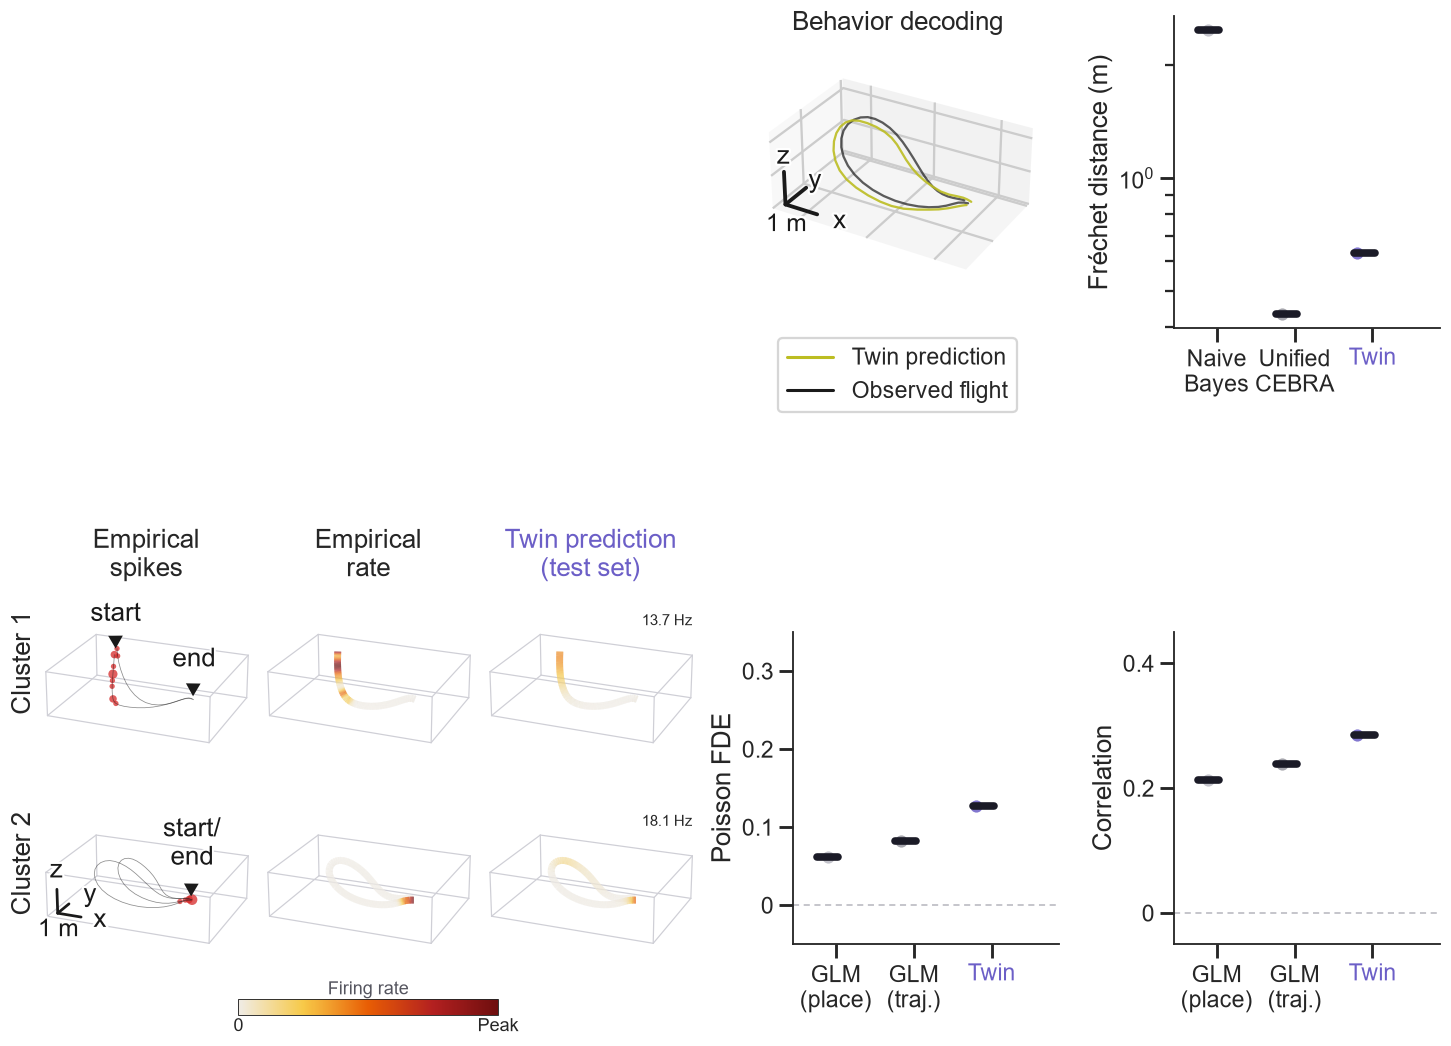


Fig 1e FDE - session-level Wilcoxon vs Twin (session medians):
Empty DataFrame
Columns: []
Index: []

Fig 1f Pearson r - session-level Wilcoxon vs Twin (session medians):
Empty DataFrame
Columns: []
Index: []

Fig 1c Frechet - session-level Wilcoxon vs Twin (session medians):
Empty DataFrame
Columns: []
Index: []

Fig 1c Frechet (per-flight) - pooled unit-level Wilcoxon vs Twin (per-unit stats, no panel):
      model    vs  n  median_diff         p stars         P
naive_bayes joint 13        1.511 0.0004883   *** P < 0.001
      cebra joint 13     -0.06528   0.08032       P = 0.080

Fig 1e FDE (per-neuron) - pooled unit-level Wilcoxon vs Twin (per-unit stats, no panel):
    model    vs  n  median_diff         p stars         P
glm_place joint 95       0.1265 3.142e-10   *** P < 0.001
 glm_traj joint 95      0.09921  3.76e-09   *** P < 0.001

Fig 1f Pearson r (per-neuron) - pooled unit-level Wilcoxon vs Twin (per-unit stats, no panel):
    model    vs  n  median_diff         p stars   

In [17]:
# [figures.ipynb cell `fig1_merged`]
# === Figure 1 (B-H) on a single canvas ===
# A and G are external schematics (provided separately). Layout (wide canvas; the
# 3-D maps packed left, decode + encode metrics on the right):
#   top-left gap (schematic A)      | b (decoded 3D) | c(sess) c(flight)
#   d (left | center | right)  -- one row per flight cluster -- dual-field triptych
#   FDE(sess) FDE(neuron)  r(sess) r(neuron) -- one row, centred on the map rows
# Panels: B = decoding example; C = Fréchet distance; D = dual-field example
#   (left spikes | center empirical rate | right predicted rate); E = Poisson FDE; F = Pearson r.
#   H = leave-one-session-out transfer FDE (appended to the right of F).
# Font sizes are applied per-panel at the end (see _apply_panel_fonts) so every
# individual title / axis label / tick label / legend is the same size, whether
# or not ph.set_pub_style() was re-run this session.
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG = 17, 17, 15, 15
FS_PEAK = 10          # per-row peak-rate annotation in panel d (deliberately small)

# Panel d contributes one map row per flight cluster. The canvas and the gridspec grow
# with it (6 in per row), so the row height -- and therefore every other panel -- is
# unchanged whether panel d shows 2 clusters or 3.
N_MAP_ROWS = len(pk['clusters'])
fig1 = plt.figure(figsize=(26, 6 * (1 + N_MAP_ROWS)))
gs1 = fig1.add_gridspec(1 + N_MAP_ROWS, 8, hspace=0.6, wspace=0.55,
                        width_ratios=[1, 1, 1, 0.3, 1, 1, 1, 1])

# b: example decoded 3-D trajectory (row 1, col 2; cols 0-1 are left as a gap)
ax_b = fig1.add_subplot(gs1[0, 4], projection='3d')
# draw the single example flight chosen above (a cleanly decoded rew→rew loop;
# see the Fig 1b selection cell) so the panel stays legible
_zoom_dec = joint_decode_test[joint_decode_test['session'] == zoom_session]
gfl = _zoom_dec[_zoom_dec['flight_id'] == example_flight].sort_values('t_idx')
ax_b.plot(gfl['x_true'], gfl['y_true'], gfl['z_true'], color='k', lw=1.5, alpha=0.7)
ax_b.plot(gfl['x_pred'], gfl['y_pred'], gfl['z_pred'], color='tab:olive', lw=1.5, alpha=0.9)
# axis limits: the room's full x and z (arena width, floor to ceiling), but only a
# padded y window around the flight -- set_box_aspect keeps 1 m equal on all three
# axes, so the room's 5.2 m depth squeezed this 1.7 m-deep loop into a ribbon.
_B_YPAD = 0.35      # m of room kept either side of the flight in y
_rlim_b = np.asarray(meta_info_dict['r_lim'][zoom_session], float)
_b_y = np.concatenate([gfl['y_true'].to_numpy(), gfl['y_pred'].to_numpy()])
ax_b.set_xlim(*_rlim_b[0]); ax_b.set_zlim(*_rlim_b[2])
ax_b.set_ylim(max(_b_y.min() - _B_YPAD, _rlim_b[1, 0]), min(_b_y.max() + _B_YPAD, _rlim_b[1, 1]))
ax_b.set_box_aspect([max(np.ptp(_l), 1e-3) for _l in (ax_b.get_xlim(), ax_b.get_ylim(), ax_b.get_zlim())])  # 1 m equal on x/y/z
nh.add_3d_scalebar(ax_b, corner=(0, 0, 0), fontsize=FS_LABEL, z_nudge=(0.0, 0.0, 0.075), hide_frame=False, label_weight='normal')  # scale bar; keep gridlines, drop tick/axis labels
ax_b.set_title('Behavior decoding')
# legend below the axes
ax_b.legend(handles=[plt.Line2D([], [], color='tab:olive', label=f'{OUR_MODEL} prediction'),
                     plt.Line2D([], [], color='k', label='observed flight')],
            loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=1, fontsize=FS_LEG)

# c: decoding accuracy as per-flight 3-D Fréchet distance (row 1, cols 3-4)
ax_c = fig1.add_subplot(gs1[0, 5])   # decoding accuracy: session medians only
_, ptab_c = ph.compare_models_fig(
    decode_frechet_df, 'frechet_3d', present, ref='joint', labels=DECODE_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight', higher_is_better=False,
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False,
    log_y=True, axes=(ax_c, None))
# log y-axis for the Frechet (decoding-accuracy) panel; ticks at the decades only
# (10^-1 / 10^0 / 10^1), minor labels suppressed, so the axis stays sparse
from matplotlib.ticker import (FixedLocator as _FixLoc, NullFormatter as _NullFmt,
                               LogFormatterSciNotation as _LogSciFmt)
_flo, _fhi = ax_c.get_ylim()
ax_c.set_yscale('log')
ax_c.set_ylim(max(_flo, 0.1), _fhi)
ax_c.yaxis.set_major_locator(_FixLoc([0.1, 1.0, 10.0]))
ax_c.yaxis.set_major_formatter(_LogSciFmt())
ax_c.yaxis.set_minor_formatter(_NullFmt())

# d: dual-field example unit, 3-D maps (map rows, cols 1-3); the three columns are the
# left (spikes), center (empirical rate), right (predicted rate) sub-panels, and there
# is one row per flight cluster in pk['clusters'].
ax_ex = np.array([[fig1.add_subplot(gs1[r + 1, cc], projection='3d') for cc in range(3)]
                 for r in range(len(pk['clusters']))], dtype=object)
# zoom the maps to the plotted flights (bigger trajectories than the full-arena r_lim)
_fl_plot = [f for f in pk['flights'] if f['cluster'] in pk['clusters']]
_fl_xyz = np.vstack([f['xyz'][:, :3] for f in _fl_plot])
_fl_lo, _fl_hi = _fl_xyz.min(0), _fl_xyz.max(0)
_fl_pad = 0.16 * (_fl_hi - _fl_lo) + 0.05       # small margin so start/end labels fit in-frame
_tight_rlim = [(float(_fl_lo[i] - _fl_pad[i]), float(_fl_hi[i] + _fl_pad[i])) for i in range(3)]
# restyle kit (make_mockups8): light-to-hot heat ramp — the classic place-field
# reading, with a light low end that stays legible on the white wireframe background
from matplotlib.colors import LinearSegmentedColormap as _LSC1d
_RATE_CMAP = _LSC1d.from_list(
    'heat', ['#F0ECE5', '#F7C948', '#E85D04', '#B32020', '#6E0E0E'])
sm_ex = plot_dual_field_cell(pk['flights'], pk['neuron'], pk['clusters'], dt, _tight_rlim,
                            peaks=pk['peaks'], axes3d=ax_ex, col_title_fs=FS_TITLE, row_label_fs=FS_LABEL,
                            row_labels=[f'Cluster {i + 1}' for i in range(len(pk['clusters']))],
                            rate_cmap=_RATE_CMAP, spike_color='#D62828',
                            startend='none')  # start/end drawn below
# 3-D map style: a thin wireframe room instead of panes + gridlines,
# drawn from the shared tight limits (every subpanel axis-off). clip_on=False because
# the projected room is wider than the axes rectangle at this box_aspect, so its
# far-right vertical edge would otherwise be clipped away and the box read as open.
def _fig1d_room(_axm):
    _axm.set_axis_off()
    for _s3, _e3 in [((0, 0, 0), (1, 0, 0)), ((0, 0, 0), (0, 1, 0)), ((0, 0, 0), (0, 0, 1)),
                     ((1, 0, 0), (1, 1, 0)), ((1, 0, 0), (1, 0, 1)), ((0, 1, 0), (1, 1, 0)),
                     ((0, 1, 0), (0, 1, 1)), ((0, 0, 1), (1, 0, 1)), ((0, 0, 1), (0, 1, 1)),
                     ((1, 1, 0), (1, 1, 1)), ((1, 0, 1), (1, 1, 1)), ((0, 1, 1), (1, 1, 1))]:
        _axm.plot(*[[_tight_rlim[_d][0] + (_tight_rlim[_d][1] - _tight_rlim[_d][0]) * _s3[_d],
                     _tight_rlim[_d][0] + (_tight_rlim[_d][1] - _tight_rlim[_d][0]) * _e3[_d]]
                    for _d in range(3)], lw=0.8, color='#CFCFD6', zorder=0, clip_on=False)


for _r, _cc in np.ndindex(ax_ex.shape):
    _axm = ax_ex[_r, _cc]
    _fig1d_room(_axm)
    _axm.patch.set_alpha(0.0)     # transparent canvas so neighbours do not cover overflow
    # the map slots overlap, so draw the columns back-to-front: the spike column's
    # start/end labels overflow rightward over its neighbour
    _axm.set_zorder(0.1 * (2 - _cc))
nh.add_3d_scalebar(ax_ex[-1, 0], corner=(0, 0, 0), fontsize=FS_LABEL, lw=1.8, y_nudge=(0.1, 0.0, 0.15), z_nudge=(0.0, 0.0, 0.3), origin_shift=(0.0, 0.0, 0.0), alpha=1.0, label_weight='normal', hide_frame=False)  # single triad for all panel-d maps (frame kept by the loop above)
ax_ex[0, 0].set_title('Empirical\nspikes', fontsize=FS_TITLE)
ax_ex[0, 1].set_title('Empirical\nrate', fontsize=FS_TITLE)
ax_ex[0, 2].set_title('Twin prediction\n(test set)', fontsize=FS_TITLE,
                      color=ph.ACCENT_E)  # Twin column carries the accent hue
# thicken the rate-coloured trajectory lines so the colour scale reads (empirical +
# predicted columns only; the spike-panel path/arrows are left untouched)
from mpl_toolkits.mplot3d.art3d import Line3DCollection as _L3DC
for _rr in range(ax_ex.shape[0]):
    for _cc in (1, 2):
        for _col in ax_ex[_rr, _cc].collections:
            if isinstance(_col, _L3DC):
                _col.set_linewidth(3.5); _col.set_alpha(0.9)
# enlarge the 3-D content inside each map panel (zoom>1 counteracts the default 3-D margin)
for _axm in ax_ex.flat:
    _axm.set_box_aspect([_h - _l for _l, _h in _tight_rlim], zoom=1.0)
# --- E/F: replace the many overlapping flights with ONE average trajectory coloured
# by the mean empirical / predicted rate (alpha declutter failed) ---
from mpl_toolkits.mplot3d.art3d import Line3DCollection as _L3DCavg
def _resamp(_a, _n):
    _a = np.asarray(_a, float); _t = np.linspace(0, 1, len(_a)); _tn = np.linspace(0, 1, _n)
    if _a.ndim == 1:
        return np.interp(_tn, _t, _a)
    return np.stack([np.interp(_tn, _t, _a[:, _d]) for _d in range(_a.shape[1])], 1)
_NAVG, _neu, _SM_SEC = 480, pk['neuron'], 0.05    # resample points; smoothing SD in seconds
# _NAVG=480 puts the resampled grid at ~5-9 ms/sample: the peaks are converged (they move by
# <0.02 Hz from 480 to 1920) and the drawn tube stops showing interpolation facets. Sigma is
# specified in real time, so it is invariant to _NAVG. NB _SM_SEC below dt (100 ms bins) only
# rounds the interpolation between bins; it cannot suppress Poisson noise, which lives at the
# bin scale.
from scipy.ndimage import gaussian_filter1d as _gf1d
def _smooth(_r, _n_bins):
    """Gaussian with sigma fixed at _SM_SEC seconds of REAL time (0 disables it). Every flight
    is resampled to _NAVG points from its own length, so a sigma constant in resampled samples
    would smooth the long loop flights (~42 bins) nearly twice as hard as the short
    point-to-point ones (~23)."""
    if not _SM_SEC:
        return _r
    return _gf1d(_r, _SM_SEC / dt * _NAVG / _n_bins, mode='nearest')
# Each cluster is peak-normalised on its own, so a quiet row is not washed out by a loud
# one, and the empirical/predicted pair of a row shares one scale so the amplitude
# difference between them stays readable. The divisor is the PAIR's peak rather than the
# empirical peak because this unit is over-predicted (6-49% here) -- normalising on the
# empirical peak would push the predicted map past the top of the colour scale and clip it.
# The absolute scale is not lost: each row is annotated with its empirical peak in Hz.
_avg, _row_peak = {}, {}
for _ci, _c in enumerate(pk['clusters']):
    _fls = [f for f in pk['flights'] if f['cluster'] == _c]
    _axyz = np.mean([_resamp(f['xyz'][:, :3], _NAVG) for f in _fls], axis=0)
    # both maps get the identical kernel (SD = _SM_SEC of real time). Filtering only the
    # empirical side maximises the peak asymmetry, since the prediction carries no Poisson
    # noise for a filter to remove; treating them the same keeps the comparison like-for-like.
    _emp = np.mean([_smooth(_resamp(f['obs'][:, _neu] / dt, _NAVG), len(f['obs']))
                    for f in _fls], axis=0)
    _prd = np.mean([_smooth(_resamp(f['pred'][:, _neu] / dt, _NAVG), len(f['obs']))
                    for f in _fls], axis=0)
    # the row's normalising constant = the larger of the two peaks, so the 'X.X Hz' label
    # below is exactly what full colour saturation means (usually the empirical peak; the
    # predicted one where the model over-predicts)
    _row_peak[_ci] = max(float(_emp.max()), float(_prd.max()), 1e-9)
    _avg[_ci] = (_axyz, _emp / _row_peak[_ci], _prd / _row_peak[_ci])
_norm = plt.Normalize(0.0, 1.0)
sm_ex.set_norm(_norm)          # trajectory colours are in peak-normalised units now
for _ci, (_axyz, _emp, _prd) in _avg.items():
    for _colc, _rate in ((1, _emp), (2, _prd)):
        _axm2 = ax_ex[_ci, _colc]
        for _oldc in list(_axm2.collections):
            _oldc.remove()
        # draw late->early so the early part of the flight is painted last within
        # the collection (on top), not occluded by the returning trajectory
        _axyz_r, _rate_r = _axyz[::-1], _rate[::-1]
        _pp = _axyz_r.reshape(-1, 1, 3); _sg = np.concatenate([_pp[:-1], _pp[1:]], axis=1)
        _lc = _L3DCavg(_sg, cmap=sm_ex.cmap, norm=_norm)
        _lc.set_array(0.5 * (_rate_r[:-1] + _rate_r[1:])); _lc.set_linewidth(4.5)
        _axm2.add_collection(_lc)
    # the colours are peak-normalised and no bar is drawn, so state the row's absolute
    # scale in its top-right corner.
    # y=0.79, not 1.0: a 3-D box only fills ~54% of its axes height, so the axes corner
    # floats halfway to the row above and the label loses its row
    ax_ex[_ci, 2].text2D(1.0, 0.79, f'{_row_peak[_ci]:.1f} Hz',
                         transform=ax_ex[_ci, 2].transAxes, ha='right', va='bottom',
                         fontsize=FS_PEAK, clip_on=False)
# --- start/end labels: raised, arrow straight down; 'start/end' wrapped for the loop ---
import matplotlib.patheffects as _peSE
from matplotlib.patches import FancyArrowPatch as _FAP
from mpl_toolkits.mplot3d import proj3d as _proj3d
class _Arrow3D(_FAP):
    def __init__(self, _xs, _ys, _zs, *a, **k):
        super().__init__((0, 0), (0, 0), *a, **k); self._v3d = (_xs, _ys, _zs)
    def do_3d_projection(self, renderer=None):
        _x, _y, _z = self._v3d
        _xp, _yp, _zp = _proj3d.proj_transform(_x, _y, _z, self.axes.M)
        self.set_positions((_xp[0], _yp[0]), (_xp[1], _yp[1]))
        return float(np.min(_zp))
def _draw_se(_ax, _starts, _ends):
    _stk = [_peSE.withStroke(linewidth=2.5, foreground='white')]
    _dz = 0.6 * (_tight_rlim[2][1] - _tight_rlim[2][0])
    _cs = np.asarray(_starts, float).mean(0); _ce = np.asarray(_ends, float).mean(0)
    _items = [((_cs + _ce) / 2, 'start/\nend')] if np.linalg.norm(_cs - _ce) < 0.6 \
        else [(_cs, 'start'), (_ce, 'end')]
    for _pt, _lab in _items:
        _top = _pt + np.array([0.0, 0.0, _dz])
        _ar = _Arrow3D([_top[0], _pt[0]], [_top[1], _pt[1]], [_top[2], _pt[2]], color='k',
                       arrowstyle='-|>,head_width=0.4,head_length=0.7', mutation_scale=12,
                       lw=0, zorder=6, clip_on=False)   # stem hidden, just the head
        _ax.add_artist(_ar)
        _ax.text(_top[0], _top[1], _top[2], _lab, color='k', fontsize=FS_LABEL,
                 ha='center', va='bottom', zorder=7,
                 path_effects=_stk, clip_on=False)
for _ci, _c in enumerate(pk['clusters']):
    _fls = [f for f in pk['flights'] if f['cluster'] == _c]
    _draw_se(ax_ex[_ci, 0], [f['xyz'][0, :3] for f in _fls], [f['xyz'][-1, :3] for f in _fls])
# let the start/end labels + arrows overflow their panels instead of clipping
for _rr in range(ax_ex.shape[0]):
    for _ch in ax_ex[_rr, 0].get_children():
        if hasattr(_ch, 'get_text') and _ch.get_text() in ('start', 'end', 'start/end'):
            _ch.set_clip_on(False)
    for _col in ax_ex[_rr, 0].collections:
        _col.set_clip_on(False)
# nudge the "Cluster N" row labels up a bit
for _r in range(ax_ex.shape[0]):
    for _ch in ax_ex[_r, 0].get_children():
        if hasattr(_ch, 'get_text') and _ch.get_text().startswith('Cluster'):
            _lx, _ly = _ch.get_position()
            _ch.set_position((_lx, _ly + 0.12))
# shrink horizontal gaps between the 3 map columns to match the comparison-pair pull:
# pull the outer columns (c spikes, e predicted) toward the fixed centre (d empirical)
_MAP_PULL = 0.030
for _r in range(ax_ex.shape[0]):
    for _cc, _sh in ((0, _MAP_PULL), (2, -_MAP_PULL)):
        _pm = ax_ex[_r, _cc].get_position()
        ax_ex[_r, _cc].set_position([_pm.x0 + _sh, _pm.y0, _pm.width, _pm.height])
# raise every map row below the first to tighten the inter-cluster gaps. The shift
# is fixed in inches rather than figure fractions, so the gap reads the same at any
# row count.
_ROW_UP = 0.18 * 18 / fig1.get_figheight()
for _r2 in range(1, ax_ex.shape[0]):
    for _axm2 in ax_ex[_r2, :]:
        _pm2 = _axm2.get_position()
        _axm2.set_position([_pm2.x0, _pm2.y0 + _ROW_UP * _r2, _pm2.width, _pm2.height])

# e, f: encoding fit (rows 2-3, cols 4-5) -- e = Poisson FDE, f = Pearson r
ax_e = fig1.add_subplot(gs1[1, 4])
_, ptab_e = ph.compare_models_fig(
    encode_metrics_df, 'fde', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Poisson FDE', unit_name='neuron', clip=(-0.6, 1.0), zero_line=True, sess_ylim=(-0.05, 0.35),
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False, axes=(ax_e, None))
ax_f = fig1.add_subplot(gs1[1, 6])
_, ptab_f = ph.compare_models_fig(
    encode_metrics_df, 'corr', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Correlation', unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.05, 0.45),
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False, axes=(ax_f, None))

# shrink the 2-D comparison panels so they match the (margin-padded) 3-D panels and
# their tick labels don't collide with neighbours
def _shrink(ax, fx=1.3, fy=0.86):
    p = ax.get_position()
    ax.set_position([p.x0 + p.width * (1 - fx) / 2, p.y0 + p.height * (1 - fy) / 2,
                     p.width * fx, p.height * fy])
for _ax in (ax_e, ax_f, ax_c):
    _shrink(_ax)

# fine layout nudges: panel b (decode example) a touch right; the first map row
# (flight cluster 1 maps) a touch down
_A_DX, _ROW2_DY = 0.015, 0.012
_pf = ax_b.get_position()
ax_b.set_position([_pf.x0 + _A_DX, _pf.y0, _pf.width, _pf.height])
for _ax in list(ax_ex[0, :]):
    _p = _ax.get_position()
    _ax.set_position([_p.x0, _p.y0 - _ROW2_DY, _p.width, _p.height])
# centre the FDE + Correlation strip vertically across the map rows
_map_y1 = ax_ex[0, 0].get_position().y1    # top of the first map row (after its down-nudge)
_map_y0 = ax_ex[-1, 0].get_position().y0   # bottom of the last map row (after its raise)
_strip_cy = (_map_y0 + _map_y1) / 2
for _mx in (ax_e, ax_f):
    _pm = _mx.get_position()
    _mx.set_position([_pm.x0, _strip_cy - _pm.height / 2, _pm.width, _pm.height])
# session-median columns: FDE leftmost, Correlation next to it, Frechet in its row-1 slot;
# the maps, decode example and schematic-A space keep their positions.
_R, _MGAP = 0.965, 0.04
_MW = ax_e.get_position().width
_PITCH = _MW + _MGAP
_X0 = _R - _MW - 3 * _PITCH                    # FDE-session column (maps abut here)
for _ax, _xx in ((ax_e, _X0), (ax_f, _X0 + _PITCH), (ax_c, _X0 + _PITCH)):
    _p = _ax.get_position()
    _ax.set_position([_xx, _p.y0, _MW, _p.height])
# pack each example against its quant panels (close the mid-canvas gap), leaving
# only enough room for the quant y-axis labels / panel-b z-axis; empty space is
# pushed to the top-left for the external schematic a
_MAP_GAP, _B_GAP = 0.035, 0.05
_fde_left = _X0                            # maps abut the FDE column
_fr_left = _X0 + _PITCH                    # panel b abuts the (left-shifted) Frechet column (aligned under Correlation)
# encoding: slide the whole 3-D map block right so it abuts the FDE columns
_map_right = max(ax_ex[_r, 2].get_position().x1 for _r in range(ax_ex.shape[0]))
_dmap = _fde_left - _MAP_GAP - _map_right
for _axm in ax_ex.flat:
    _p = _axm.get_position()
    _axm.set_position([_p.x0 + _dmap, _p.y0, _p.width, _p.height])
# decoding: slide panel b right so it abuts the Frechet columns
_pb = ax_b.get_position()
_bw, _bh = _pb.width * 1.3, _pb.height * 1.3       # enlarge the decode example
ax_b.set_position([_fr_left - _B_GAP - _bw, _pb.y0 + _pb.height / 2 - _bh / 2, _bw, _bh])

# tighten the vertical gap between the top row (decode example + Frechet) and the
# maps/metrics row below by lowering the whole top row a touch
_TOPROW_DOWN = 0.045
for _tr_ax in (ax_b, ax_c):
    _tp = _tr_ax.get_position()
    _tr_ax.set_position([_tp.x0, _tp.y0 - _TOPROW_DOWN, _tp.width, _tp.height])

# E-F (FDE + Correlation) y-ticks: <=1 decimal place, drop trailing '.0' (1.0->1,
# 0.0->0), and avoid quarter steps (0.25 / 0.75)
from matplotlib.ticker import MaxNLocator as _MaxNLoc, FuncFormatter as _FuncFmt
def _ytick_fmt(_v, _p):
    _s = f'{_v:.1f}'.rstrip('0').rstrip('.')
    return '0' if _s in ('-0', '') else _s
for _mx in (ax_e, ax_f):
    _mx.yaxis.set_major_locator(_MaxNLoc(nbins=4, steps=[1, 2, 5, 10]))
    _mx.yaxis.set_major_formatter(_FuncFmt(_ytick_fmt))

# --- Panel H: joint-model transfer, Poisson FDE session medians. Leave-one-session-out only, placed to the RIGHT of the Correlation panel
# with the row above left empty. Modes scratch / frozen / full (the main joint model
# already drawn above = the skyline); fine-tune is omitted here. Brackets + 3-tier stars
# = session-level Wilcoxon vs scratch. Regenerate the pkls with
# `python training/train_joint_transfer.py`.
_TJ_ROOT, _TJ_MODES = './out/demo/transfer_joint', ['scratch', 'frozen', 'full']
# 'full' = the main joint model (Fig 1B,E,F) appended as a 3rd box
_full_enc_tj = encode_metrics_df.loc[encode_metrics_df['model'] == 'joint',
                                     ['session', 'bat', 'unit', 'fde']].assign(mode='full')
def _load_tj_f1(_g):
    _p = f'{_TJ_ROOT}/{_g}/results_{_g}_encode.pkl'
    return pd.read_pickle(_p) if os.path.exists(_p) else pd.DataFrame()
_TJ_CV = [('session', 'Leave-one-session-out')]
ptab_tj = []
if all(_load_tj_f1(_g).empty for _g, _ in _TJ_CV):
    print('Fig 1 transfer row: no joint-transfer results on disk — '
          'run `python training/train_joint_transfer.py` first.')
else:
    # Panel H sits to the RIGHT of the Correlation panel (ax_f), aligned to it; the
    # row above is left intentionally empty. No canvas compression / bottom row.
    _tj_axes = {}
    for _gi, (_grp, _gtitle) in enumerate(_TJ_CV):
        _df = pd.concat([_load_tj_f1(_grp), _full_enc_tj], ignore_index=True)
        _pf = ax_f.get_position()                        # Correlation panel
        _axs = fig1.add_axes([_pf.x1 + _MGAP, _pf.y0, _pf.width, _pf.height])
        _, _pt = ph.compare_models_fig(
            _df, 'fde', _TJ_MODES, ref='scratch', model_col='mode', ylabel='Poisson FDE',
            unit_name='neuron', clip=(-1, 1), sess_ylim=(-0.05, 0.35), zero_line=True,
            higher_is_better=True, star_style='bracket', star_kw={'star_gap': -0.025},
            accent='full',
            show_titles=False, show_xticklabels=True, show_sess_ylabel=True, axes=(_axs, None))
        _tj_axes[_gi] = _axs
        ptab_tj += [dict(cv=_gtitle, level='session median', **_r) for _r in _pt.to_dict('records')]
        _upt = ph.pooled_ptable(_df, 'fde', _TJ_MODES, 'scratch', ['session', 'unit'],
                                model_col='mode', higher_is_better=True)
        ptab_tj += [dict(cv=_gtitle, level='per neuron', **_r) for _r in _upt.to_dict('records')]
    # CV-scheme header (single line) just above the panel
    fig1.canvas.draw()
    _HDR_OFF = 0.03
    for _gi, (_, _gtitle) in enumerate(_TJ_CV):
        _pa = _tj_axes[_gi].get_position()
        fig1.text((_pa.x0 + _pa.x1) / 2, _pa.y1 + _HDR_OFF, _gtitle,
                  ha='center', va='bottom', fontsize=FS_TITLE)

# Enforce a single consistent font size on every panel individually (titles, x/y/z
# axis labels, tick labels, and legend text), so nothing depends on the global
# rcParams having been refreshed by ph.set_pub_style() this session.
def _apply_panel_fonts(ax):
    ax.title.set_fontsize(FS_TITLE)
    ax.xaxis.label.set_fontsize(FS_LABEL)
    ax.yaxis.label.set_fontsize(FS_LABEL)
    if hasattr(ax, 'zaxis'):
        ax.zaxis.label.set_fontsize(FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    _lg = ax.get_legend()
    if _lg is not None:
        for _t in _lg.get_texts():
            _t.set_fontsize(FS_LEG)
        if _lg.get_title() is not None:
            _lg.get_title().set_fontsize(FS_LEG)
for _ax in fig1.get_axes():
    _apply_panel_fonts(_ax)

# restyle kit: one shared horizontal rate key under the map block (rows are peak-
# normalised, so the scale reads 0 -> peak; each row's absolute peak stays as its
# 'X.X Hz' inset)
fig1.canvas.draw()
_mb_x0 = min(ax_ex[-1, _cc2].get_position().x0 for _cc2 in range(3))
_mb_x1 = max(ax_ex[-1, _cc2].get_position().x1 for _cc2 in range(3))
_mb_y0 = min(ax_ex[-1, _cc2].get_position().y0 for _cc2 in range(3))
_cax_d1 = fig1.add_axes([_mb_x0 + 0.30 * (_mb_x1 - _mb_x0),
                         max(_mb_y0 - 0.012, 0.005),
                         0.40 * (_mb_x1 - _mb_x0), 0.008])
_cb_d1 = fig1.colorbar(sm_ex, cax=_cax_d1, orientation='horizontal')
_cb_d1.set_ticks([0, 1]); _cb_d1.set_ticklabels(['0', 'peak'])
_cb_d1.ax.tick_params(labelsize=FS_TICK - 3, length=0, pad=2)
_cb_d1.outline.set_linewidth(0.6)
_cax_d1.set_title('Firing rate', fontsize=FS_TICK - 3, color=ph.INK_SOFT, pad=3)

# let edge swarm dots overflow their axes instead of being cropped (2-D panels only), and
# nudge the y-axis a hair left so the leftmost swarm doesn't touch it
from matplotlib.collections import PathCollection as _PathColl
for _ua in fig1.get_axes():
    if hasattr(_ua, 'zaxis'):          # skip 3-D map / decode panels
        continue
    _has_swarm = False
    for _uc in _ua.collections:
        if isinstance(_uc, _PathColl):
            _uc.set_clip_on(False)
            _has_swarm = True
    if _has_swarm:
        _xl = _ua.get_xlim()
        _ua.set_xlim(_xl[0] - 0.15, _xl[1])
ph.save_fig(fig1, 'fig1_full'); plt.show()
for _n, _pt in [('1e FDE', ptab_e), ('1f Pearson r', ptab_f), ('1c Frechet', ptab_c)]:
    print(f'\nFig {_n} - session-level Wilcoxon vs {OUR_MODEL} (session medians):'); ph.p_table(_pt.to_dict('records'))
for _n, _df, _v, _o, _mc, _id, _hib in [
        ('1c Frechet (per-flight)', decode_frechet_df, 'frechet_3d', present, 'decoder', ['session', 'flight_id'], False),
        ('1e FDE (per-neuron)', encode_metrics_df, 'fde', ENC_ORDER, 'model', ['session', 'unit'], True),
        ('1f Pearson r (per-neuron)', encode_metrics_df, 'corr', ENC_ORDER, 'model', ['session', 'unit'], True)]:
    print(f'\nFig {_n} - pooled unit-level Wilcoxon vs {OUR_MODEL} (per-unit stats, no panel):')
    ph.p_table(ph.pooled_ptable(_df, _v, _o, 'joint', _id, model_col=_mc, higher_is_better=_hib).to_dict('records'))
if ptab_tj:
    print('\nFig 1 transfer row (Poisson FDE) - Wilcoxon vs scratch:'); ph.p_table(ptab_tj)

---
## 3. Fig. 3 and Extended Data Fig. 8 on the demo session

The cells below are the paper's Fig. 3 cells. Fig. 3 draws this session, so panels A–I (raw spikes
and flight paths only) reproduce the paper exactly in every mode.

**With `MODELS = 'paper'`, J–L reproduce the paper exactly too.**

- **J–K:** use the paper's Twin. Its latent is projected onto the paper's PCA basis, which was fit
  to all 17 sessions' test-flight latents per environment, exactly as in `figures.ipynb`, and is
  committed as `out/fig3_cache/latent_pca3.npz`.
- **L–M:** pool 15 sessions. This session's values are recomputed and checked against the paper's
  committed results (both checks are printed), and the other 14 sessions come from those results.
  M's 15-D latent is the paper's PCA-15 basis (`out/fig3_cache/latent_pca15.npz`), fit like J–K's.

**With the single-session models, J–M are this session's own version.**

- The PCA is fit on this session alone, and L–M contain only this session.
- Expect them to differ from the paper. With a Twin trained on this session alone, its latent rate
  maps are not more stable across paths than its physical ones: panel K's Wilcoxon *P* ranged from
  0.3 to 0.6 across our GPU retraining runs, against *P* = 4.4 × 10⁻⁹ in the paper.

The first cell extracts the Twin latent for the test flights, and the second takes the motif
segmentation helpers that Fig. 3 borrows from the Extended Data Fig. 4 cell.

In [18]:
# [figures.ipynb cell `daa02161`]
# --- Shared latent extraction: per-timepoint encode-space latents (neural tokens
# x[:, :T]) from BOTH the encode and decode passes, position, route/cluster/spikes.
from notebook_helpers import DIST_THRESH, get_target_locs


@torch.no_grad()
def extract_latents(split='test'):
    """Concatenate encode-pass latents + metadata across all sessions.

    Returns a dict with arrays aligned per valid timepoint: `latent` (N, d),
    `pred` (N, K_session — ragged, so returned per-session too), `xyz` (N, 3),
    `session`, `bat`, `flight_id`, `rel_t`, `cluster`, per-point `route`/`origin`/`dest`,
    and `spike_by_flight` (ragged {(session, flight_id): spikes}).
    """
    lat, lat_dec, xyz, sess, batv, fid, relt, clu = [], [], [], [], [], [], [], []
    spike_by_flight = {}
    per_session_latent = {}
    for sn in session_names:
        bm = meta_info_dict['behavior_mean'][sn][0, 0, :3]
        bs = meta_info_dict['behavior_std'][sn][0, 0, :3]
        sl = []
        for batch in dataloaders[split][sn]:
            X = batch.behavior.to(device)
            m = batch.mask.to(device)
            B, T, _ = X.shape
            spike0 = X.new_zeros(B, T, unit_num_dict[sn])
            _, _, xf = joint_model(sn, spike0, X, m, m, torch.zeros_like(m))
            h_n = xf[:, :T].cpu().numpy()  # encode space: neural tokens x[:, :T]
            # decode pass: real spikes visible, behaviour masked -> decode latent
            _, _, xf_d = joint_model(sn, batch.spike.to(device), X, m, torch.zeros_like(m), m)
            h_d = xf_d[:, :T].cpu().numpy()  # encode space too: neural tokens x[:, :T] (decode pass)
            Xn = batch.behavior.numpy()
            mn = batch.mask.numpy() == 1.0
            fpi = batch.flight_path_index.numpy(); fti = batch.flight_type_index.numpy()
            spn = batch.spike.numpy()
            for b in range(B):
                v = mn[b]
                nv = int(v.sum())
                if nv == 0:
                    continue
                lat.append(h_n[b, v]); sl.append(h_n[b, v])
                lat_dec.append(h_d[b, v])
                pos = Xn[b, :, :3] * bs + bm
                xyz.append(pos[v])
                sess.append(np.full(nv, sn)); batv.append(np.full(nv, parse_bat(sn)))
                fid.append(np.full(nv, int(fpi[b]))); clu.append(np.full(nv, int(fti[b])))
                spike_by_flight[(sn, int(fpi[b]))] = spn[b, v]
                relt.append(np.arange(nv) / max(nv - 1, 1))
        per_session_latent[sn] = np.concatenate(sl) if sl else np.empty((0, joint_model.latent_dim))
    out = dict(latent=np.concatenate(lat), latent_decode=np.concatenate(lat_dec), xyz=np.vstack(xyz),
               session=np.concatenate(sess), bat=np.concatenate(batv),
               flight_id=np.concatenate(fid), rel_t=np.concatenate(relt),
               cluster=np.concatenate(clu), spike_by_flight=spike_by_flight,
               per_session_latent=per_session_latent)

    # Per-(session, flight) origin/destination endpoint classes -> route id.
    origin = np.zeros(len(out['session']), int)
    dest = np.zeros_like(origin)
    key = np.char.add(np.char.add(out['session'], '|'), out['flight_id'].astype(str))
    for k in np.unique(key):
        m = key == k
        sn = out['session'][m][0]
        rew, perch = get_target_locs(sn)
        order = np.argsort(out['rel_t'][m])
        pos = out['xyz'][m][order]
        o = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
        d = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
        origin[m] = o; dest[m] = d
    out['origin'] = origin
    out['dest'] = dest
    out['route'] = np.array([ph.route_id(o, d) for o, d in zip(origin, dest)])
    return out


emb = extract_latents('test')
print('latent points:', len(emb['session']), '| latent dim:', emb['latent'].shape[1])

latent points: 412 | latent dim: 64


In [19]:
# [figures.ipynb cell `edfig4_motif_axis`, lines 221-309: the motif segmentation helpers used by Fig. 3]
# 0 = traveling along +u1 (which points along +x by construction), 1 = along -u1. Indoor
# feeders sit at +x, so 'positive' is the reward-approaching direction indoors.
MOTIF_LABELS = ['positive', 'negative']
# PuOr endpoints (#5e3c99 / #e66101) taken to ~78% saturation -- half way to a fully
# muted pair. Muted enough not to glare under a few hundred overlapping semi-transparent
# lines, while the warm one keeps enough chroma to read orange rather than brown. Still
# clear of every route and bat hue.
MOTIF_COLORS = ['#61468f', '#cc651b']
MOTIF_MIN_EXC_M = 0.50       # turning point must overshoot the nearer endpoint by >= 0.5 m
MOTIF_MIN_EXC_FRAC = 0.25    #   ... and by >= 25% of the flight's axial range
MOTIF_MIN_FRAC = 0.15        # each motif >= 15% of the flight ...
MOTIF_MIN_BINS = 3           #   ... and >= 3 bins (Hausdorff needs a real point cloud)
MOTIF_SMOOTH = 3             # centered moving average on s(t) before locating the turn
# The split count is flat over m >= 0.3-1.0 m / frac 0.15-0.40 (34/34 loops split at every
# setting; total two-motif flights 60 -> 54), so these sit inside a plateau, not on an edge.
# (Re-verified on the axial trace after the 2026-08-01 unweighting; the reward-distance
# trace gave 58 -> 55 on the same grid.)


def _motif_smooth(d):
    """Centered moving average, shared by both progress traces."""
    if len(d) >= MOTIF_SMOOTH:
        return pd.Series(d).rolling(MOTIF_SMOOTH, center=True, min_periods=1).mean().to_numpy()
    return d


def motif_reward_distance(xyz, session):
    """d(t) = distance to the nearest reward feeder for one flight, lightly smoothed.

    Not used for the motif definition (see `motif_axis_progress`); the Fig 3 cells
    (`fig3_ratemap_sim`, `fig3tri_data`) segment on it."""
    rew, _ = get_target_locs(session)
    return _motif_smooth(
        np.linalg.norm(xyz[:, None, :] - np.asarray(rew)[None, :, :], axis=2).min(1))


def motif_axis_progress(xyz, session):
    """s(t) = signed progress (m) along the room's mean flight axis, lightly smoothed.

    `axfit_project` centres on the environment's flight centroid, which `segment_motifs`
    never sees -- it uses only differences of s -- so the centering is for interpretability
    only and the labels are translation-invariant."""
    return _motif_smooth(axfit_project(xyz, session))


def motif_segment_axis(xyz, session):
    """(acute angle in deg between THIS SEGMENT's own PC1 and its room's mean axis,
    the segment's anisotropy lam1/sum(lam)); (nan, nan) if it is too short to have an axis.

    Same arc-length-resampled PCA recipe as above, applied per segment rather than per
    flight. `fig2m_rsa` gates the quantified set on this angle."""
    p = np.asarray(xyz, float)
    if len(p) < 3:
        return np.nan, np.nan
    q = axfit_arclen_resample(p)
    if q is None:
        return np.nan, np.nan
    v, lam = axfit_flight_axis(q)
    return (axfit_angle(v, AXFIT_AXIS['indoor' if ph.is_indoor(session) else 'outdoor']),
            float(lam[0] / lam.sum()))


def segment_motifs(d):
    """Optimal <=1-switch two-direction labeling of a monotone-progress trace `d`.

    Works on any scalar progress variable: `motif_axis_progress` (signed axial progress,
    used by Fig 2) or `motif_reward_distance` (radial, used by the Fig 3 cells).

    Returns ``(bounds, labels, excursion, threshold)``: `bounds` a list of one or two
    ``(start, stop)`` index slices, `labels` the matching motif ids (0 where the trace
    INCREASES, 1 where it decreases -- i.e. 0 positive / 1 negative for an axial trace),
    `excursion` the best e(k*) in meters (whether or not the switch was accepted) and
    `threshold` the value it had to clear."""
    T = len(d)
    lo = max(MOTIF_MIN_BINS, int(np.ceil(MOTIF_MIN_FRAC * T)))
    single = ([(0, T)], [int(d[-1] < d[0])])
    thresh = max(MOTIF_MIN_EXC_M, MOTIF_MIN_EXC_FRAC * float(d.max() - d.min()))
    if T < 2 * lo:
        return (*single, 0.0, thresh)
    k = np.arange(lo - 1, T - lo)                     # split after k -> legs [0, k], [k+1, T)
    a, b = d[k] - d[0], d[-1] - d[k]                  # signed progress per leg
    e = np.where(a * b < 0, np.minimum(np.abs(a), np.abs(b)), -np.inf)   # opposite legs only
    if not np.isfinite(e).any():                      # monotone d(t): no valid switch
        return (*single, 0.0, thresh)
    i = int(np.argmax(e))
    if e[i] < thresh:
        return (*single, float(e[i]), thresh)
    ks = int(k[i])
    return ([(0, ks + 1), (ks + 1, T)], [int(a[i] < 0), int(b[i] < 0)], float(e[i]), thresh)

---
## Fig. 3 — Latent representations expose spatial generalization at the single-neuron and population level

Flight clusters that share an origin and destination but take geometrically different 3-D
paths. The common coordinate is each path's normalized flight progress (normalized
cumulative path length). If place cells fire at the same *fraction* of the path on every
variant of the route, the population sequence is preserved; if they fire at fixed 3-D
positions, it is scrambled.

These cells load raw spike times (native `Fs`) with `Data_Prep_for_Raw`, separately from
the binned dataloaders. Their data cells are shared with Extended Data Figs. 8 and 9.

In [20]:
# [figures.ipynb cell `07756d6f`]
# === Figure 3 data: raw-spike cache + same-route different-path pairs ===
from scipy.interpolate import interp1d as _interp1d
from scipy.io import loadmat as _loadmat
from itertools import combinations as _combinations
import glob as _glob
from digitalbat.utility.utils import frechet_distance as _frechet_d
from digitalbat.datasets.data import Data_Prep_for_Raw as _DPR
from notebook_helpers import get_target_locs as _get_target_locs

AP_PARENT = data_config['parent_folder']
N_DS_AP, MIN_DUR_AP, MIN_CLU_AP, MAX_ACC_AP = 100, 1.0, 3, 50.0


def _ap_load_session(sn):
    """Raw behaviour + spike times (native Fs) for one session, via Data_Prep_for_Raw."""
    folder = AP_PARENT + sn
    su = AP_PARENT + 'To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    prep = _DPR(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
                use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
                use_ripple_flag=False, only_flight_flag=True, spike_count_flag=True,
                bin_width=0.10, max_acceleration=MAX_ACC_AP)
    prep.get_all_behavior(); prep.get_all_spike(); prep.get_flight_cluster()
    fc = prep.flight_cluster_results
    bhv = _loadmat(_glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    t_bhv = bhv['t'][:, 0] if 'Dataset_2' in sn else bhv['t'][0, :]
    Fs = float(bhv['Fs'][0, 0])
    # raw spike times + merge (mirrors Data_Prep_for_Raw.get_all_spike)
    su_paths = sorted(_glob.glob(su))
    times, cids, ptypes = [], [], []
    for p in su_paths:
        gu = _loadmat(p)['out_Gunits']
        cids.append(np.array([x[0][0, 0] for x in gu['cluster_id']]))
        times.append([x[0][:, 0] / 1e6 for x in gu['spikeTimes_usec']])
        ptypes.append(list(np.array([np.squeeze(x[0]).item() if np.squeeze(x[0]).ndim == 0
                       else np.squeeze(x[0]) for x in gu['pType']], dtype=object)))
    mg = _loadmat(_glob.glob(folder + '/merges_Dataset_*.mat')[0])['merges']
    refractory = 0.001
    for ii in range(len(su_paths)):
        if len(mg[ii][0]):
            to_merge = mg[ii][0][0][0][0]
            cl, tl = cids[ii], times[ii]
            midx = [np.where(cl == cid)[0][0] for cid in to_merge]
            merged = np.sort(np.concatenate([tl[k] for k in midx]))
            clean = [merged[0]]
            for s_ in merged[1:]:
                if s_ - clean[-1] > refractory:
                    clean.append(s_)
            tl[midx[0]] = np.array(clean)
            for k in midx[1:]:
                tl[k] = np.array([])
            valid = [i for i, st in enumerate(tl) if len(st) > 0]
            times[ii] = [tl[i] for i in valid]; cids[ii] = cl[valid]
            ptypes[ii] = [ptypes[ii][i] for i in valid]
    spike_times = [st for probe in times for st in probe]
    pType = np.array([pt for probe in ptypes for pt in probe], dtype=object)
    return dict(r=bhv['r'], t=t_bhv, Fs=Fs, v=bhv['v'], spike_times=spike_times,
                pType=pType, fc_results=fc)


def _ds_traj(r, fs, fe, n=N_DS_AP):
    fs, fe = int(fs), int(fe); traj = r[fs:fe + 1]
    to = np.linspace(0, 1, traj.shape[0]); td = np.linspace(0, 1, n)
    return np.column_stack([_interp1d(to, traj[:, d])(td) for d in range(3)])


session_data_cache = {}
for sn in session_names:
    try:
        d = _ap_load_session(sn)
    except Exception as exc:
        print(f'  [Fig3 skip {sn}] {type(exc).__name__}: {exc}'); continue
    fc, Fs = d['fc_results'], d['Fs']
    recs = []
    for i in range(fc['N']):
        dur = (fc['stop_frame'][i] - fc['start_frame'][i]) / Fs
        if dur < MIN_DUR_AP:
            continue
        pos = d['r'][fc['start_frame'][i]:fc['stop_frame'][i] + 1]
        acc = np.gradient(np.gradient(pos, 1.0 / Fs, axis=0), 1.0 / Fs, axis=0)
        if np.linalg.norm(acc, axis=1).max() > MAX_ACC_AP:
            continue
        recs.append(dict(cluster_id=int(fc['id'][i]), f_start=int(fc['start_frame'][i]),
                         f_stop=int(fc['stop_frame'][i]), duration=dur))
    dff = pd.DataFrame(recs)
    ci = {}
    for cid, grp in dff.groupby('cluster_id'):
        if len(grp) < MIN_CLU_AP:
            continue
        trajs = np.stack([_ds_traj(d['r'], row.f_start, row.f_stop) for _, row in grp.iterrows()])
        ci[int(cid)] = dict(n_flights=len(grp), mean_traj=np.nanmean(trajs, 0))
    session_data_cache[sn] = dict(data=d, df_flights=dff, cluster_info=ci)
    print(f'  {sn}: {len(dff)} flights, {len(ci)} clusters')

# --- same-route, different-path candidate pairs (shared endpoints, high Fréchet) ---
AP_ENDPOINT_THRESH, AP_MIN_FRECHET, AP_MIN_FLIGHTS, AP_LABEL_THRESH = 0.25, 1.0, 5, 1.0  # shared endpoints within 0.25 m (drops the loose reward->perch pair)


def _endpoint_label(sess, xyz):
    rew, perch = _get_target_locs(sess)
    dr = float(np.min(np.linalg.norm(rew - xyz, axis=1)))
    dp = float(np.min(np.linalg.norm(perch - xyz, axis=1)))
    if min(dr, dp) > AP_LABEL_THRESH:
        return 'other'
    return 'reward' if dr <= dp else 'perch'


_apc = []
for sess, cached in session_data_cache.items():
    big = {c: i for c, i in cached['cluster_info'].items() if i['n_flights'] >= AP_MIN_FLIGHTS}
    for a, b in _combinations(big, 2):
        ta, tb = big[a]['mean_traj'], big[b]['mean_traj']
        sg, eg = float(np.linalg.norm(ta[0] - tb[0])), float(np.linalg.norm(ta[-1] - tb[-1]))
        if max(sg, eg) > AP_ENDPOINT_THRESH:
            continue
        fr = float(_frechet_d(ta, tb))
        if fr < AP_MIN_FRECHET:
            continue
        _apc.append(dict(session=sess, bat=parse_bat(sess), cluster_a=a, cluster_b=b,
                         n_flights_a=big[a]['n_flights'], n_flights_b=big[b]['n_flights'],
                         start_gap=sg, end_gap=eg, frechet=fr,
                         score=min(big[a]['n_flights'], big[b]['n_flights']) * fr))
df_altpath = pd.DataFrame(_apc)
if len(df_altpath):
    df_altpath['route_type'] = [
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][0]) + '→' +
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][-1])
        for s, a in zip(df_altpath.session, df_altpath.cluster_a)]
    df_altpath = df_altpath.sort_values('score', ascending=False).reset_index(drop=True)
print(f'\n{len(df_altpath)} same-route different-path pairs')
df_altpath.head(8)

  Acceleration filter: removed 4/82 flights (peak |acc| > 50.0 m/s²)
  Dataset_1_32622_231009: 78 flights, 7 clusters

1 same-route different-path pairs


,session,bat,cluster_a,cluster_b,n_flights_a,n_flights_b,start_gap,end_gap,frechet,score,route_type
0,Dataset_1_32622_231009,32622,15,16,10,19,0.025309,0.042311,1.740129,17.401289,reward→reward


In [21]:
# [figures.ipynb cell `23e9fd4f`]
# === Figure 3 analysis core: `_route_example` for one route pair (Fig 3, ED Figs 8-9) ===
from scipy.stats import wilcoxon as _wilcoxon, spearmanr as _spearmanr, rankdata as _rankdata
from scipy.ndimage import gaussian_filter1d as _gaussian1d

AP_N_PROG, AP_N_TIME, AP_ACTIVE_HZ = 40, 40, 1.0
AP_N_TIME_HI = 160  # display-only resolution for the smoothed paired heatmaps
AP_N_SHUF_PC, AP_N_SHUF_SEQ = 100, 2000
AP_SMOOTH_SD, AP_SMOOTH_PAD = 0.10, 4.0  # normalized-time rate = spike train * Gaussian: SD (s) + overflow (in SDs)
# Axis of the whole figure: 'time' (normalized flight time) or 'space' (normalized
# route progress = cumulative path distance / total). Set AP_PHASE='time' to revert.
AP_PHASE = 'time'
AP_SMOOTH_SD_PROG = 0.04  # Gaussian SD for the space (progress) rate, in normalized-progress units
_pe = np.linspace(0, 1, AP_N_PROG + 1); _pc = (_pe[:-1] + _pe[1:]) / 2
_te = np.linspace(0, 1, AP_N_TIME + 1); _tc = (_te[:-1] + _te[1:]) / 2


# --- heading axes (shared with ED Fig 8) --------------------------------------------
# Two behavioural readings of "heading" that also evolve along a flight: the ALLOCENTRIC
# azimuth, and the same heading taken relative to the reward the flight lands on (0 deg =
# flying straight at it). The PV correlation matrix can be re-indexed off normalized time
# onto either of them, and summarised as mean PV corr vs CIRCULAR heading lag -- the
# heading counterpart of the mean-PV-corr-vs-time-lag curve in panel G. Both curves are
# drawn on one x axis by mapping +-180 deg of heading lag onto the +-1 of time lag.
AP_N_HEAD = 24                       # heading bins over [-180, 180)
AP_HEAD_EDGES = np.linspace(-np.pi, np.pi, AP_N_HEAD + 1)
AP_HEAD_LAGS_DEG = np.arange(-(AP_N_HEAD // 2), AP_N_HEAD // 2) * (360.0 / AP_N_HEAD)
# Near / far bands of the near-vs-far test, as a fraction of the +-180 deg lag range. Near
# is a BAND rather than the single 0 lag (unlike the time-lag peak test) because the
# re-indexed matrices are NaN-heavy: most heading combinations are never flown.
AP_HEAD_NEAR, AP_HEAD_FAR = 0.1, 0.5
AP_N_BOOT_CMP = 2000                 # cell-bootstrap draws for the place-vs-heading contrast
# Common cell set for that comparison. 'union' = tuned to EITHER axis (even-handed: neither
# axis is advantaged by the selection); 'intersect' = tuned to both (conservative, small);
# 'all' = every recorded unit (no selection at all).
AP_CMP_CELLS = 'union'
AP_REL_MIN_D = 0.10                  # m; bearing to the goal is undefined on top of it
# The heading hues shared by Fig 3H-I and the ED heading figures
AP_HEAD_STYLE = {'azimuth': ('#7263AC', 'azimuth'),
                 'rel': ('#8C6D4F', 'goal heading')}


def _traj_azimuth(traj):
    """Horizontal heading (radians) at each sample of an (n, >=2) path."""
    v = np.gradient(np.asarray(traj)[:, :2], axis=0)
    return np.arctan2(v[:, 1], v[:, 0])


def _future_reward(session, traj):
    """The 'future reward' of a path: the reward feeder nearest where the path ends."""
    rew = np.asarray(nh.get_target_locs(session)[0])
    return rew[int(np.argmin(np.linalg.norm(rew[:, :2] - np.asarray(traj)[-1, :2], axis=1)))]


def _rel_heading(traj, goal):
    """Heading minus bearing-to-`goal` (radians, wrapped) along an (n, >=2) path: 0 = flying
    straight at it, +-pi = straight away, positive = aimed to its left. NaN within
    AP_REL_MIN_D of the goal, where the bearing is set by tracking noise alone."""
    xy = np.asarray(traj)[:, :2]
    v = np.gradient(xy, axis=0)
    bear = np.arctan2(goal[1] - xy[:, 1], goal[0] - xy[:, 0])
    rel = (np.arctan2(v[:, 1], v[:, 0]) - bear + np.pi) % (2 * np.pi) - np.pi
    rel[np.linalg.norm(xy - goal[None, :2], axis=1) < AP_REL_MIN_D] = np.nan
    return rel


def _bin_idx(vals, edges):
    """Bin index of each value within `edges`; -1 where the value itself is NaN."""
    idx = np.clip(np.digitize(vals, edges) - 1, 0, len(edges) - 2)
    return np.where(np.isfinite(vals), idx, -1)


def _pv_head_reindex(PV, p_idx, q_idx, n=None):
    """Re-index a (Path-1 time x Path-2 time) PV matrix onto (Path-1 bin x Path-2 bin):
    each cell is the mean PV correlation over the time-bin pairs landing in it, NaN where
    no pair does. Returns (matrix, per-cell pair count)."""
    n = AP_N_HEAD if n is None else n
    ok = (p_idx[:, None] >= 0) & (q_idx[None, :] >= 0) & np.isfinite(PV)
    flat = (p_idx[:, None] * n + q_idx[None, :])[ok]
    s = np.bincount(flat, weights=np.asarray(PV)[ok], minlength=n * n)
    c = np.bincount(flat, minlength=n * n)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan).reshape(n, n), c.reshape(n, n)


def _head_lag_curve(M):
    """Mean over CELLS (NaNs ignored) at each circular heading lag q - p, ordered like
    AP_HEAD_LAGS_DEG. Cell-level, not pair-level: it summarises the matrix as drawn."""
    n = M.shape[0]
    d = ((np.arange(n)[None, :] - np.arange(n)[:, None]) % n)
    ok = np.isfinite(M)
    s = np.bincount(d[ok], weights=M[ok], minlength=n)
    c = np.bincount(d[ok], minlength=n)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)[np.arange(-(n // 2), n // 2) % n]


def _head_near_far():
    """Boolean (near, far) masks over AP_HEAD_LAGS_DEG."""
    return (np.abs(AP_HEAD_LAGS_DEG) <= AP_HEAD_NEAR * 180,
            np.abs(AP_HEAD_LAGS_DEG) >= AP_HEAD_FAR * 180)


def _prog(pos):
    s = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(pos, axis=0), axis=1))])
    return s / max(s[-1], 1e-9)


def _route_example(idx, seed_=1, merge_alt=None, pairs_df=None, n_candidates=1, browse=False,
                   force_neuron=None, smooth_traj=None):
    """Compute maps, cross-validated place cells, PV correlation + lag, and the three
    sequence-preservation tests for df_altpath row `idx`. Returns a results dict.

    `smooth_traj` (Gaussian SD in ARC-LENGTH samples; None = off, the default everywhere but
    ED Fig 9) lightly smooths the MEAN paths only -- never the per-flight tracking the rate
    maps, place cells, ring maps and every shuffle test are built from. It exists because a
    mean path is compressed near a landing: the bat decelerates onto the perch, so the last
    few of the 100 samples span a couple of centimetres and their finite-difference heading is
    set by residual jitter, which puts a cusp in the drawn path and mis-bins the heading axes
    the PV matrix is re-indexed onto. What it touches is exactly the mean-path geometry:
    `traj_ref`/`traj_alt`/`traj_third` and their resampled forms, hence the 3-D separation
    matrix, the goal-heading matrix, the heading re-indexing and its lag curves. `ref_len`,
    the endpoint tests that choose Path 3, and every spike-derived quantity stay on the raw
    cluster info."""
    rng = np.random.default_rng(seed_)
    row = (df_altpath if pairs_df is None else pairs_df).iloc[idx]
    sess, a, b = row.session, int(row.cluster_a), int(row.cluster_b)
    d = session_data_cache[sess]['data']; dff = session_data_cache[sess]['df_flights']
    ci = session_data_cache[sess]['cluster_info']
    REF, ALT = (a, b) if ci[a]['n_flights'] >= ci[b]['n_flights'] else (b, a)
    ALT_IDS = [ALT] + [int(c) for c in (merge_alt or [])]  # extra alternate clusters merged into Path 2
    _alt_df = dff[dff.cluster_id.isin(ALT_IDS)]
    _alt_mean_traj = np.nanmean(np.stack([_ds_traj(d['r'], r.f_start, r.f_stop)
                                          for _, r in _alt_df.iterrows()]), 0)
    def _smooth_path(t):
        """Light Gaussian smoothing of a mean path, applied in ARC-LENGTH space.

        Filtering the samples where they lie does not work here. A mean path is sampled
        uniformly in normalized TIME and the bat spends the last tenth of a flight landing, so
        a tenth of the samples describe about half a percent of the path. Whatever the average
        of two dozen settling manoeuvres does inside those few centimetres -- for Dataset_2's
        Path 1 it arcs 8 cm up and back down again, 435 deg of cumulative turn over the last 15
        samples -- is then drawn at full weight and reads as a kink, and no kernel in sample
        space can reach across it without also flattening metres of real geometry.

        Re-spacing the curve uniformly by arc length before the filter gives that tail the
        weight its LENGTH deserves (435 deg -> 12 deg at SD 1.5, against 125 deg for the same
        SD applied to the samples), and reading the result back at each sample's OWN arc length
        leaves the sample-to-time correspondence -- and so the alignment with the
        normalized-time rate bins -- exactly as it was.
        """
        t = np.asarray(t, float)
        s = _prog(t); u = np.linspace(0.0, 1.0, len(t))
        _eq = _gaussian1d(
            np.column_stack([np.interp(u, s, t[:, k]) for k in range(t.shape[1])]),
            smooth_traj, axis=0, mode='nearest')          # 'nearest': endpoints stay put
        return np.column_stack([np.interp(s, u, _eq[:, k]) for k in range(t.shape[1])])

    # the mean paths, optionally smoothed (see `smooth_traj`). Everything geometric below reads
    # these, not `ci[...]['mean_traj']`.
    _smooth = (lambda t: np.asarray(t, float)) if not smooth_traj else _smooth_path
    _ref_mean_traj = _smooth(ci[REF]['mean_traj'])
    _alt_mean_traj = _smooth(_alt_mean_traj)
    nu = len(d['spike_times']); dt = 1.0 / d['Fs']
    ref_len = float(np.sum(np.linalg.norm(np.diff(ci[REF]['mean_traj'], axis=0), axis=1)))

    _gnorm = 1.0 / (AP_SMOOTH_SD * np.sqrt(2 * np.pi))

    def maps(fldf, offsets=None, space_only=False):
        # `rate_time` is the phase-tuning matrix (nu x AP_N_TIME): normalized-TIME rate
        # (spike train * Gaussian, AP_SMOOTH_SD s) if AP_PHASE=='time', else the normalized-
        # SPACE rate = occupancy-normalized progress rate (Gaussian KDE on spike progress /
        # Gaussian-smoothed occupancy), both in spikes/s. `rate_prog` (route-progress map for
        # place-cell selection) is unchanged in either mode.
        occ = np.zeros(AP_N_PROG); sp = np.zeros((nu, AP_N_PROG)); rt = np.zeros((nu, AP_N_TIME))
        den_s = np.zeros(AP_N_TIME); nfl = 0
        for i, (_, fr) in enumerate(fldf.iterrows()):
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]
            prog = _prog(d['r'][fs:fe + 1]); rel_t = ft - ft[0]; dur = ft[-1] - ft[0]
            off = 0.0 if offsets is None else offsets[i]
            occ += np.histogram(prog, bins=_pe)[0] * dt; nfl += 1
            t_eval = ft[0] + _tc * dur  # real-time points at the normalized-time bin centers
            if AP_PHASE == 'space' and not space_only:  # smoothed occupancy over progress
                _zc = (_tc[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
                den_s += np.exp(-0.5 * _zc * _zc).sum(1) * dt
            for u in range(nu):
                st = d['spike_times'][u]
                stf = st[(st >= ft[0]) & (st <= ft[-1])]
                if len(stf):
                    rel = (stf - ft[0] + off) % dur
                    sp[u] += np.histogram(np.interp(rel, rel_t, prog), bins=_pe)[0]
                if not space_only:
                    if AP_PHASE == 'time':
                        # rate = raw spike train * Gaussian (SD = AP_SMOOTH_SD s), a rate not a
                        # density (no 1/N), sampled at the normalized-time bin centres; overflow
                        # spikes included so edge bins aren't truncated; averaged over flights.
                        stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD) &
                                 (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                        if len(stw):
                            z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                            rt[u] += _gnorm * np.exp(-0.5 * z * z).sum(1)
                    elif len(stf):  # space: Gaussian KDE of spike progress (occ-normalized below)
                        _sprog = np.interp(stf, ft, prog)
                        _zs = (_tc[:, None] - _sprog[None, :]) / AP_SMOOTH_SD_PROG
                        rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
        rate_time = rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den_s, 1e-9)
        return dict(rate_prog=sp / np.maximum(occ, 1e-9), occ=occ, rate_time=rate_time, n=nfl)

    _fsp_cache = {}

    def _flight_spikes(fs, fe):
        """Per-unit spike times inside one flight, cached: the ring null rebuilds the maps
        100x per heading axis and the slice does not depend on the shuffle offset."""
        if (fs, fe) not in _fsp_cache:
            t0, t1 = d['t'][fs], d['t'][fe]
            _fsp_cache[(fs, fe)] = [st[(st >= t0) & (st <= t1)] for st in d['spike_times']]
        return _fsp_cache[(fs, fe)]

    def head_maps(fldf, kind, offsets=None):
        """Occupancy-normalized rate (spikes/s) over the AP_N_HEAD ring of `kind`, the
        circular counterpart of `maps`' route-progress map: same occupancy normalization,
        same per-flight circular time shift for the null (`offsets`), bins on a ring instead
        of an interval. Spike headings are interpolated from the unwrapped per-sample trace
        and re-wrapped; samples where the heading is undefined are dropped."""
        occ = np.zeros(AP_N_HEAD); sp = np.zeros((nu, AP_N_HEAD))
        for i, (_, fr) in enumerate(fldf.iterrows()):
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]
            xyz = d['r'][fs:fe + 1]
            h = (_traj_azimuth(xyz) if kind == 'azimuth'
                 else _rel_heading(xyz, _future_reward(sess, xyz)))
            ok = np.isfinite(h)
            if ok.sum() < 2:
                continue
            rel_t = ft - ft[0]; dur = ft[-1] - ft[0]
            off = 0.0 if offsets is None else offsets[i]
            occ += np.histogram(h[ok], bins=AP_HEAD_EDGES)[0] * dt
            hk = np.unwrap(h[ok])
            for u, stf in enumerate(_flight_spikes(fs, fe)):
                if len(stf):
                    hs = np.interp((stf - ft[0] + off) % dur, rel_t[ok], hk)
                    sp[u] += np.histogram((hs + np.pi) % (2 * np.pi) - np.pi, bins=AP_HEAD_EDGES)[0]
        return dict(rate=sp / np.maximum(occ, 1e-9), occ=occ)

    def _time_rate(fldf, centers):
        """Phase-tuning rate (all neurons) sampled at `centers`, matching AP_PHASE: normalized-
        time spike-train*Gaussian (with edge overflow) for 'time', or occupancy-normalized
        progress rate for 'space'. Finer grid than the 40-bin analysis maps, for a smooth
        heatmap display."""
        rt = np.zeros((nu, len(centers))); den = np.zeros(len(centers)); nfl = 0
        for _, fr in fldf.iterrows():
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]; dur = ft[-1] - ft[0]
            nfl += 1
            if AP_PHASE == 'space':
                prog = _prog(d['r'][fs:fe + 1])
                _zc = (centers[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
                den += np.exp(-0.5 * _zc * _zc).sum(1) * dt
            else:
                t_eval = ft[0] + centers * dur
            for u in range(nu):
                st = d['spike_times'][u]
                if AP_PHASE == 'time':
                    stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD) &
                             (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                    if len(stw):
                        z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                        rt[u] += _gnorm * np.exp(-0.5 * z * z).sum(1)
                else:
                    stf = st[(st >= ft[0]) & (st <= ft[-1])]
                    if len(stf):
                        _sprog = np.interp(stf, ft, prog)
                        _zs = (centers[:, None] - _sprog[None, :]) / AP_SMOOTH_SD_PROG
                        rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
        return rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den, 1e-9)

    def _si(rate, occ):
        p = occ / occ.sum(); lam = (p * rate).sum()
        if lam <= 0:
            return 0.0
        nz = rate > 0
        return float((p[nz] * rate[nz] * np.log2(rate[nz] / lam)).sum() / lam)

    def _p(obs, null):
        """One-sided shuffle p: how often the null reaches the observed statistic."""
        return float((1 + np.sum(np.asarray(null) >= obs)) / (len(null) + 1))

    def _rowcorr(M1, M2):
        A = M1 - M1.mean(1, keepdims=True); B = M2 - M2.mean(1, keepdims=True)
        den = np.sqrt((A ** 2).sum(1) * (B ** 2).sum(1))
        return np.where(den > 0, (A * B).sum(1) / np.maximum(den, 1e-12), np.nan)

    # cross-validated place cells on the reference route-progress map
    ref_all = dff[dff.cluster_id == REF].sample(frac=1.0, random_state=seed_).reset_index(drop=True)
    nR = len(ref_all); j1, j2 = int(round(0.5 * nR)), int(round(0.75 * nR))
    tr, va, te = ref_all.iloc[:j1], ref_all.iloc[j1:j2], ref_all.iloc[j2:]
    tr_m = maps(tr); held = maps(pd.concat([va, te]), space_only=True)
    si = np.array([_si(tr_m['rate_prog'][u], tr_m['occ']) for u in range(nu)])
    r_obs = _rowcorr(tr_m['rate_prog'], held['rate_prog'])
    hd = [d['t'][int(fr.f_stop)] - d['t'][int(fr.f_start)] for _, fr in pd.concat([va, te]).iterrows()]
    r_null = np.empty((AP_N_SHUF_PC, nu))
    for s_ in range(AP_N_SHUF_PC):
        hm = maps(pd.concat([va, te]), offsets=[rng.uniform(0, x) for x in hd], space_only=True)
        r_null[s_] = _rowcorr(tr_m['rate_prog'], hm['rate_prog'])
    pcv = np.nanmean(r_null >= r_obs[None, :], axis=0)
    peak_tr = tr_m['rate_prog'].max(1)
    place = (pcv < 0.025) & (peak_tr >= AP_ACTIVE_HZ) & (si > 0) & np.isfinite(r_obs)
    pc = np.where(place)[0]

    # Cross-validated CIRCULAR tuning, one cell set per heading axis: identical criterion to
    # the place cells above (held-out map correlation beats a circular-shift null at P < 0.025,
    # peak >= AP_ACTIVE_HZ, positive spatial information) but on the AP_N_HEAD ring of azimuth /
    # heading-relative-to-the-future-reward instead of route progress. Panel G's heading curves
    # and the ED Fig 8 heatmaps use these, NOT the place cells. Its own generator, so the
    # place-cell and shuffle-test streams above and below stay bit-identical.
    rng_h = np.random.default_rng(seed_ + 101)
    _held_df = pd.concat([va, te])

    def _ring_cells(kind):
        trm = head_maps(tr, kind)
        r_obs_h = _rowcorr(trm['rate'], head_maps(_held_df, kind)['rate'])
        r_null_h = np.empty((AP_N_SHUF_PC, nu))
        for s_ in range(AP_N_SHUF_PC):
            r_null_h[s_] = _rowcorr(trm['rate'], head_maps(
                _held_df, kind, offsets=[rng_h.uniform(0, x) for x in hd])['rate'])
        si_h = np.array([_si(trm['rate'][u], trm['occ']) for u in range(nu)])
        keep = ((np.nanmean(r_null_h >= r_obs_h[None, :], axis=0) < 0.025)
                & (trm['rate'].max(1) >= AP_ACTIVE_HZ) & (si_h > 0) & np.isfinite(r_obs_h))
        return np.where(keep)[0]

    pc_head = {k: _ring_cells(k) for k in AP_HEAD_STYLE}

    # --- circular counterpart of the Spearman peak-order test, one per heading axis -------
    # Heading is circular, so a linear Spearman on peak-BIN INDEX is not rotation invariant (a
    # path straddling the +-180 deg seam would be distorted). Fisher-Lee (1982) circular rank
    # correlation instead: replace each cell's peak heading by its circular rank (uniform score
    # C_i = 2*pi*rank_i/n) and correlate the two paths through the pairwise-sine statistic,
    # which is rank-based AND invariant to rotation of either variable. Same label-permutation
    # null and one-sided p as the Spearman test below, on that axis's own ring-tuned cells and
    # its own ring maps -- so it is the heading version of the same question, not a new one.
    # ED Fig 6c/e run the identical statistic on their own maps; this one travels with `res`.
    _hd_ctr = 0.5 * (AP_HEAD_EDGES[:-1] + AP_HEAD_EDGES[1:])
    rng_o = np.random.default_rng(seed_ + 202)

    def _circ_rank_corr(a, b):
        n = len(a)
        Ca = 2 * np.pi * _rankdata(a, method='average') / n
        Cb = 2 * np.pi * _rankdata(b, method='average') / n
        sA = np.sin(Ca[:, None] - Ca[None, :]); sB = np.sin(Cb[:, None] - Cb[None, :])
        den = np.sqrt((sA ** 2).sum() * (sB ** 2).sum())
        return float((sA * sB).sum() / den) if den > 0 else np.nan

    head_order = {}
    if not browse:
        for k in AP_HEAD_STYLE:
            ck = pc_head[k]
            if len(ck) < 4:
                continue
            _mtr, _mvt, _malt = (head_maps(tr, k)['rate'], head_maps(_held_df, k)['rate'],
                                 head_maps(_alt_df, k)['rate'])
            _pk = {_n: _hd_ctr[np.argmax(_m[ck], axis=1)]
                   for _n, _m in (('train', _mtr), ('held', _mvt), ('alt', _malt))}
            _r = _circ_rank_corr(_pk['held'], _pk['alt'])
            _nul = [_circ_rank_corr(_pk['held'], rng_o.permutation(_pk['alt']))
                    for _ in range(AP_N_SHUF_SEQ)]
            _rtt = _circ_rank_corr(_pk['train'], _pk['held'])
            head_order[k] = dict(
                rho=_r, p=_p(_r, _nul), null=_nul, n=int(len(ck)), rho_traintest=_rtt,
                p_traintest=_p(_rtt, [_circ_rank_corr(_pk['train'], rng_o.permutation(_pk['held']))
                                      for _ in range(AP_N_SHUF_SEQ)]))

    ref_vt = maps(pd.concat([va, te])); alt = maps(_alt_df)
    order = pc[np.argsort(tr_m['rate_time'][pc].argmax(1))] if len(pc) else pc

    # high-resolution smoothed rate for the paired heatmaps only (display), so the KDE
    # reads as continuous rather than 40 discrete columns; analysis stays at AP_N_TIME.
    _ceh = np.linspace(0, 1, AP_N_TIME_HI + 1); _tch = (_ceh[:-1] + _ceh[1:]) / 2
    ref_time_hi = _time_rate(pd.concat([va, te]), _tch)
    alt_time_hi = _time_rate(_alt_df, _tch)
    train_time_hi = _time_rate(tr, _tch)  # Path 1 TRAIN display map (the sort source)

    # PV corr (ref x alt, normalized time) + mean PV corr vs lag
    def _norm(M):
        return M / np.maximum(M.max(1, keepdims=True), 1e-9)

    def _pv_mat(Xc, Yc):  # PV corr matrix from two centred tuning matrices
        return (Xc.T @ Yc) / (np.outer(np.linalg.norm(Xc, axis=0), np.linalg.norm(Yc, axis=0)) + 1e-9)
    Rr, Ra = _norm(ref_vt['rate_time']), _norm(alt['rate_time'])

    def _pv_for(cells):  # the same PV corr matrix over an arbitrary cell subset
        if len(cells) < 2:
            return np.full((Rr.shape[1], Rr.shape[1]), np.nan)
        return _pv_mat(Rr[cells] - Rr[cells].mean(0), Ra[cells] - Ra[cells].mean(0))
    A = Rr[pc] - Rr[pc].mean(0); B = Ra[pc] - Ra[pc].mean(0)
    PV = _pv_mat(A, B)
    nlag = PV.shape[0]; lags = np.arange(-nlag + 1, nlag)
    pv_lag = np.array([np.nanmean(np.diagonal(PV, offset=k)) for k in lags])
    peak_lag = lags[np.nanargmax(pv_lag)] / nlag

    # 95% band on mean PV corr vs lag by bootstrapping over PLACE CELLS (the ~independent
    # replicates). A SEM across the diagonal elements would be anti-conservative because
    # adjacent time bins are strongly autocorrelated (not independent).
    def _lag_curve(Xc, Yc):  # mean PV corr at each lag from centred place-cell tunings
        return np.array([np.nanmean(np.diagonal(_pv_mat(Xc, Yc), offset=k)) for k in lags])
    def _lag_boot(Xr, Yr, nboot=500):
        nc = Xr.shape[0]; out = np.empty((nboot, len(lags)))
        for bi in range(nboot):
            sel = rng.integers(0, nc, nc)
            out[bi] = _lag_curve(Xr[sel] - Xr[sel].mean(0), Yr[sel] - Yr[sel].mean(0))
        return np.nanpercentile(out, 2.5, axis=0), np.nanpercentile(out, 97.5, axis=0)
    pv_lag_lo, pv_lag_hi = _lag_boot(Rr[pc], Ra[pc]) if (len(pc) > 1 and not browse) else (None, None)

    # Path 3: a DIFFERENT-route cluster with sufficient repeats -- a contrast whose
    # sequence should NOT be preserved (same place cells / sort). Prefer a cluster whose
    # BOTH endpoints differ from Path 1's (e.g. perch->perch when Path 1 is reward->reward),
    # so origin AND destination are genuinely different; else fall back to one whose
    # endpoints merely differ. Among candidates, take the one with the most flights.
    _rs0, _re0 = ci[REF]['mean_traj'][0], ci[REF]['mean_traj'][-1]
    def _far_from_ref(pt):  # far from BOTH Path-1 endpoints (a genuinely different location)
        return min(np.linalg.norm(pt - _rs0), np.linalg.norm(pt - _re0)) > AP_ENDPOINT_THRESH
    _pool3 = [(ci[c]['n_flights'], c) for c in ci
              if c not in ([REF] + ALT_IDS) and ci[c]['n_flights'] >= AP_MIN_FLIGHTS]
    _both3 = [(n, c) for n, c in _pool3
              if _far_from_ref(ci[c]['mean_traj'][0]) and _far_from_ref(ci[c]['mean_traj'][-1])]
    _one3 = [(n, c) for n, c in _pool3
             if max(np.linalg.norm(ci[c]['mean_traj'][0] - _rs0),
                    np.linalg.norm(ci[c]['mean_traj'][-1] - _re0)) > AP_ENDPOINT_THRESH]
    _cand3 = _both3 if _both3 else _one3
    THIRD = int(max(_cand3)[1]) if (_cand3 and not browse) else None
    third_time_hi, pv_lag3, n_third, PV3, third_route = None, None, 0, None, None
    pv_lag3_lo = pv_lag3_hi = third_time = None
    if THIRD is not None:
        third = maps(dff[dff.cluster_id == THIRD]); n_third = third['n']; third_time = third['rate_time']
        third_time_hi = _time_rate(dff[dff.cluster_id == THIRD], _tch)
        Rt = _norm(third['rate_time']); Bt = Rt[pc] - Rt[pc].mean(0)
        PV3 = (A.T @ Bt) / (np.outer(np.linalg.norm(A, axis=0), np.linalg.norm(Bt, axis=0)) + 1e-9)
        pv_lag3 = np.array([np.nanmean(np.diagonal(PV3, offset=k)) for k in lags])
        pv_lag3_lo, pv_lag3_hi = _lag_boot(Rr[pc], Rt[pc]) if len(pc) > 1 else (None, None)
        third_route = (_endpoint_label(sess, ci[THIRD]['mean_traj'][0]) + '→' +
                       _endpoint_label(sess, ci[THIRD]['mean_traj'][-1]))

    # 3-D Euclidean distance between mean flight paths at matched normalized-time bins
    # (Path 1 bin i vs Path 2/3 bin j); z-axis of the separation heatmaps.
    def _resample_traj(traj, n):
        # resample by index (~time) or by cumulative arc length (progress), matching AP_PHASE,
        # so the n points align with the phase (time / progress) bins used for the rate
        src = _prog(traj) if AP_PHASE == 'space' else np.linspace(0.0, 1.0, len(traj))
        dst = np.linspace(0.0, 1.0, n)
        return np.column_stack([np.interp(dst, src, traj[:, k]) for k in range(traj.shape[1])])
    _p1 = _resample_traj(_ref_mean_traj, nlag)
    _p2 = _resample_traj(_alt_mean_traj, nlag)
    pv_dist = np.linalg.norm(_p1[:, None, :] - _p2[None, :, :], axis=-1)
    dist_diag = np.diagonal(pv_dist).copy()  # path separation at matched normalized time

    # The PV correlation re-indexed off normalized time onto the two heading axes (drawn as
    # matrices in ED Fig 6f), plus their circular heading-lag curves. Each axis is built from
    # ITS OWN ring-tuned cells, so the matrices are not the place-cell PV of panel E. The bin
    # assignment is pure geometry, so it is fixed once here and reused by the shuffle null
    # below -- the null therefore has exactly the same NaN coverage as the observed matrix.
    head_vals = {'azimuth': (_traj_azimuth(_p1), _traj_azimuth(_p2)),
                 'rel': (_rel_heading(_p1, _future_reward(sess, _p1)),
                         _rel_heading(_p2, _future_reward(sess, _p2)))}
    head_idx = {k: (_bin_idx(v1, AP_HEAD_EDGES), _bin_idx(v2, AP_HEAD_EDGES))
                for k, (v1, v2) in head_vals.items()}
    _hre = {k: _pv_head_reindex(_pv_for(pc_head[k]), pi, qi) for k, (pi, qi) in head_idx.items()}
    pv_head = {k: v[0] for k, v in _hre.items()}
    pv_head_n = {k: v[1] for k, v in _hre.items()}
    head_lag = {k: _head_lag_curve(M) for k, M in pv_head.items()}

    # resampled Path-3 mean path for the single-cell overlay (if a Path 3 exists)
    _third_mean_traj = _smooth(ci[THIRD]['mean_traj']) if THIRD is not None else None
    traj_third_rs = _resample_traj(_third_mean_traj, nlag) if THIRD is not None else None

    # --- pick one example unit for the single-neuron row. Among place cells with a
    # PROMINENT, well-matched normalized-time field on BOTH paths, take the one whose
    # field peak is closest to t*, the time of maximal 3-D separation on the 0-lag
    # diagonal. Such a unit codes route-progress/time rather than absolute 3-D position.
    # Closeness to t* is the PRIMARY criterion; the rest are gates that exclude weak,
    # mismatched, or non-sparse fields (not overriding closeness):
    #   - peak rate >= FIELD_MIN_HZ on each path (a real field, not a few stray spikes)
    #   - min/max peak rate >= FIELD_RATIO (comparably strong on both paths)
    #   - peaks within FIELD_MAX_SHIFT bins of each other (same normalized time)
    #   - field width (fraction of normalized time above half-max) <= FIELD_MAX_ACTIVE on
    #     each path, i.e. a SPARSE, localized field rather than one active the whole flight
    FIELD_MIN_HZ, FIELD_RATIO, FIELD_MAX_SHIFT = 1.5, 0.35, 4
    t_star = int(np.argmax(dist_diag))  # time of maximal 3-D separation (0-lag diagonal)

    def _active_frac(c):  # fraction of normalized time the field spends above half its peak
        pk = c.max()
        return float(np.mean(c >= 0.5 * pk)) if pk > 0 else 1.0

    def _pick(max_active):
        best = (np.inf, None, t_star)
        for u in pc:
            cr, ca = ref_vt['rate_time'][u], alt['rate_time'][u]
            pr, pa = float(cr.max()), float(ca.max())
            if min(pr, pa) < FIELD_MIN_HZ:
                continue
            if min(pr, pa) / max(pr, pa) < FIELD_RATIO:
                continue
            ir, ia = int(np.argmax(cr)), int(np.argmax(ca))
            if abs(ir - ia) > FIELD_MAX_SHIFT:
                continue
            if _active_frac(cr) > max_active or _active_frac(ca) > max_active:
                continue
            pk = (ir + ia) // 2  # shared field peak time
            if abs(pk - t_star) < best[0]:
                best = (abs(pk - t_star), int(u), pk)
        return best

    # tighten toward a sparse field; relax the sparsity bar only if nothing qualifies
    neuron, t_peak = None, t_star
    for _ma in (0.35, 0.5, 1.0):
        _d, _un, _pk = _pick(_ma)
        if _un is not None:
            neuron, t_peak = _un, _pk
            break

    # top-N candidate units for browsing: SAME field gates as the single pick, ranked by
    # closeness of the shared field peak to t_star (= time of maximal 3-D path separation)
    def _pick_ranked(max_active):
        out = []
        for u in pc:
            cr, ca = ref_vt['rate_time'][u], alt['rate_time'][u]
            pr, pa = float(cr.max()), float(ca.max())
            if min(pr, pa) < FIELD_MIN_HZ or min(pr, pa) / max(pr, pa) < FIELD_RATIO:
                continue
            ir, ia = int(np.argmax(cr)), int(np.argmax(ca))
            if abs(ir - ia) > FIELD_MAX_SHIFT:
                continue
            if _active_frac(cr) > max_active or _active_frac(ca) > max_active:
                continue
            out.append((abs((ir + ia) // 2 - t_star), int(u), (ir + ia) // 2))
        return sorted(out)
    _ranked = []
    for _ma in (0.35, 0.5, 1.0):
        _ranked = _pick_ranked(_ma)
        if _ranked:
            break
    candidates = [(int(u), int(pk)) for _, u, pk in _ranked[:n_candidates]]
    if force_neuron is not None:  # published figures pin a hand-picked example unit
        neuron = int(force_neuron)
        t_peak = (int(np.argmax(ref_vt['rate_time'][neuron]))
                  + int(np.argmax(alt['rate_time'][neuron]))) // 2

    def _neuron_records(fldf, nrn):
        """Per-flight 3-D paths, spike positions, and per-flight normalized spike times
        (for the raster) for `neuron` on a set of flights."""
        paths, sp, raster = [], [], []
        for _, fr in fldf.iterrows():
            fs, fe = int(fr.f_start), int(fr.f_stop)
            ft = d['t'][fs:fe + 1]; xyz = d['r'][fs:fe + 1]; dur = ft[-1] - ft[0]
            paths.append(xyz)
            stu = d['spike_times'][nrn]; stu = stu[(stu >= ft[0]) & (stu <= ft[-1])]
            if not len(stu):
                _phase = np.empty(0)
            elif AP_PHASE == 'time':
                _phase = (stu - ft[0]) / dur
            else:  # space: spike route-progress
                _phase = np.interp(stu, ft, _prog(xyz))
            raster.append(_phase)
            if len(stu):
                sp.append(np.column_stack([np.interp(stu, ft, xyz[:, k]) for k in range(3)]))
        return dict(paths=paths, spikes=np.vstack(sp) if sp else np.empty((0, 3)), raster=raster)
    # single-cell rate map + raster show ALL Path-1 flights (not just held-out val+test,
    # which the heatmap/PV analyses use); Path 2/3 already use all their flights
    neu_ref = _neuron_records(dff[dff.cluster_id == REF], neuron) if neuron is not None else None
    neu_alt = _neuron_records(_alt_df, neuron) if neuron is not None else None
    neu_third = (_neuron_records(dff[dff.cluster_id == THIRD], neuron)
                 if (neuron is not None and THIRD is not None) else None)
    ref_time_disp = maps(dff[dff.cluster_id == REF])['rate_time'] if (neuron is not None or candidates) else None
    ref_time_hi_disp = _time_rate(dff[dff.cluster_id == REF], _tch) if (neuron is not None or candidates) else None
    # per-candidate display records for browsing: each unit's 3-D spike paths + normalized-time
    # tuning on Path 1 (REF) and the merged Path 2 (ALT), from the same display rate matrices
    cand_records = []
    for _cn, _cpk in candidates:
        cand_records.append(dict(
            neuron=_cn, t_peak=_cpk,
            neu_ref=_neuron_records(dff[dff.cluster_id == REF], _cn),
            neu_alt=_neuron_records(_alt_df, _cn),
            ref_rate=ref_time_disp[_cn], alt_rate=alt['rate_time'][_cn],
            ref_rate_hi=ref_time_hi_disp[_cn], alt_rate_hi=alt_time_hi[_cn]))

    # three preservation tests (normalized time, place cells), one-sided shuffle p
    def _pv(A_, B_):
        Az, Bz = A_ - A_.mean(0), B_ - B_.mean(0)
        den = np.sqrt((Az ** 2).sum(0) * (Bz ** 2).sum(0))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(0) / den, np.nan)))

    def _mc(A_, B_):
        Az, Bz = A_ - A_.mean(1, keepdims=True), B_ - B_.mean(1, keepdims=True)
        den = np.sqrt((Az ** 2).sum(1) * (Bz ** 2).sum(1))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))

    def _roll(M, g=None):
        g = rng if g is None else g
        return np.array([np.roll(M[i], g.integers(M.shape[1])) for i in range(len(M))])

    rr, ra = ref_vt['rate_time'][pc], alt['rate_time'][pc]
    tests, tests3, p_peak, p_peak3, p_head = None, None, None, None, {}
    # The observed statistic and its null DRAWS are kept, not just the P value: the
    # multi-path Fig 3 draws these two tests as shuffle histograms, and re-drawing the
    # nulls there would give that panel a second, different null from the published P.
    peak_stat, peak_null, head_stat, head_null = None, None, {}, {}
    if len(pc) >= 4 and not browse:
        po, pa = rr.argmax(1), ra.argmax(1)
        rho = float(_spearmanr(po, pa)[0])
        p1 = _p(rho, [float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)])
        Rrn, Ran = _norm(rr), _norm(ra)
        pv = _pv(Rrn, Ran); p2 = _p(pv, [_pv(Rrn, _roll(Ran)) for _ in range(AP_N_SHUF_SEQ)])
        mc = _mc(rr, ra); p3 = _p(mc, [_mc(rr, _roll(ra)) for _ in range(AP_N_SHUF_SEQ)])
        tests = dict(rho=rho, p_order=p1, pv=pv, p_pv=p2, mc=mc, p_mapcorr=p3,
                     null1=[float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)],
                     null2=[_pv(Rrn, _roll(Ran)) for _ in range(500)],
                     null3=[_mc(rr, _roll(ra)) for _ in range(500)])
        # within-Path-1 consistency: Path 1 TRAIN peak-time order vs Path 1 held-out
        # VAL+TEST peak-time order (same place cells + same shuffle machinery as the
        # Path-1-vs-Path-2 order test above; po = val+test order, po_tr = train order).
        po_tr = tr_m['rate_time'][pc].argmax(1)
        rho_tt = float(_spearmanr(po_tr, po)[0])
        tests['rho_traintest'] = rho_tt
        tests['p_traintest'] = _p(rho_tt, [float(_spearmanr(po_tr, rng.permutation(po))[0])
                                           for _ in range(AP_N_SHUF_SEQ)])
        # near-vs-far test on the normalized-time lag curve: is the correlation higher at
        # matched time than at opposed time? Circularly roll each cell's Path-2 tuning
        # (preserves its own temporal autocorrelation, so the non-independence of time bins is
        # respected) and compare the near-minus-far statistic. Baseline subtraction makes a
        # flat-but-elevated curve come out n.s.
        # NEAR IS THE +-AP_HEAD_NEAR BAND, not the single lag-0 bin: near now means the same
        # thing -- within 10% of the axis range -- on the time axis as on the two heading axes,
        # so the three curves of panel G are scored by one rule instead of three.
        _far = np.abs(lags) >= AP_HEAD_FAR * nlag
        _near = np.abs(lags) <= AP_HEAD_NEAR * nlag
        def _peakstat(Yn):
            pl = _lag_curve(A, Yn - Yn.mean(0))
            return np.nanmean(pl[_near]) - np.nanmean(pl[_far])
        peak_stat = _peakstat(Ran)
        peak_null = [_peakstat(_roll(Ran)) for _ in range(AP_N_SHUF_SEQ)]
        p_peak = _p(peak_stat, peak_null)
        # near-vs-far on each heading-lag curve, against the SAME circular-shift null: is
        # the correlation higher at matched heading than at opposed heading? Near is the
        # +-AP_HEAD_NEAR band of 0, far the |lag| >= AP_HEAD_FAR tail (both as fractions of
        # 180 deg), so it mirrors the time-lag peak test with a band instead of one bin.
        _near_h, _far_h = _head_near_far()

        def _headstat(Xc, Yn, pi, qi):
            hl = _head_lag_curve(_pv_head_reindex(_pv_mat(Xc, Yn - Yn.mean(0)), pi, qi)[0])
            return np.nanmean(hl[_near_h]) - np.nanmean(hl[_far_h])

        for k, (pi, qi) in head_idx.items():   # each axis on its own ring-tuned cells
            ck = pc_head[k]
            if len(ck) < 4:
                continue
            Xk, Yk = Rr[ck] - Rr[ck].mean(0), Ra[ck]
            head_stat[k] = _headstat(Xk, Yk, pi, qi)
            head_null[k] = [_headstat(Xk, _roll(Yk, rng_h), pi, qi)
                            for _ in range(AP_N_SHUF_SEQ)]
            p_head[k] = _p(head_stat[k], head_null[k])
        if THIRD is not None:  # same two preservation tests + peak test, Path 1 vs Path 3
            r3 = third['rate_time'][pc]; po3 = r3.argmax(1); R3n = _norm(r3)
            rho3 = float(_spearmanr(po, po3)[0])
            pq3 = _p(rho3, [float(_spearmanr(po, rng.permutation(po3))[0]) for _ in range(AP_N_SHUF_SEQ)])
            pv3s = _pv(Rrn, R3n); pp3 = _p(pv3s, [_pv(Rrn, _roll(R3n)) for _ in range(AP_N_SHUF_SEQ)])
            tests3 = dict(rho=rho3, p_order=pq3, pv=pv3s, p_pv=pp3)
            p_peak3 = _p(_peakstat(R3n), [_peakstat(_roll(R3n)) for _ in range(AP_N_SHUF_SEQ)])
    # --- place vs heading: is the matched-TIME contrast larger than the matched-HEADING one?
    # The two published statistics are not comparable as they stand -- different cell sets,
    # different definitions of "near", and the re-indexed heading matrix covers only the ~35%
    # of cells the two paths actually fly. This puts them on one footing:
    #   * both contrasts are scored on the SAME 40 x 40 (Path-1 bin, Path-2 bin) pairs. The
    #     heading-indexed matrices are only a regrouping of these pairs, so nothing is lost and the
    #     empty-cell problem disappears;
    #   * the same rule defines both: near = within AP_HEAD_NEAR (10%) of the axis range, far =
    #     >= AP_HEAD_FAR (50%) of it. Only the axis that measures "lag" differs -- |i - j| for
    #     time, |wrapped heading difference| for the heading axes. This is the same +-10% band
    #     the lag-curve tests use, so "near" means one thing throughout the figure;
    #   * both contrasts are read off ONE PV matrix built from ONE common cell set
    #     (AP_CMP_CELLS), so no cell-set difference can drive the result and no size matching
    #     is needed. The bootstrap is PAIRED: each draw resamples cells once and scores both
    #     contrasts on that same draw, so the shared cell-sampling noise cancels out of the
    #     difference instead of adding to it.
    # Cells are the resampling unit; bin pairs are far too autocorrelated to be one. delta is
    # the observed difference on the full common set; the interval and P come from the draws.
    head_vs_place = {}
    if len(pc) >= 4 and not browse:

        def _bands(dmat, tol):  # (near, far) pair masks from a 0..1 normalized dissimilarity
            return ((dmat <= tol) & np.isfinite(dmat),
                    (dmat >= AP_HEAD_FAR) & np.isfinite(dmat))

        def _contrast(pvb, near_m, far_m):
            return float(np.nanmean(pvb[near_m]) - np.nanmean(pvb[far_m]))

        # one near band for both axes: AP_HEAD_NEAR of the range, i.e. +-4 time bins and
        # +-18 deg of heading on a scale where 1.0 = the full range (nlag bins / 180 deg).
        _m_time = _bands(np.abs(np.arange(nlag)[:, None] - np.arange(nlag)[None, :]) / nlag,
                         AP_HEAD_NEAR)
        for k, (v1, v2) in head_vals.items():
            ck = pc_head[k]
            if len(ck) < 4:
                continue
            _m_head = _bands(np.abs((v1[:, None] - v2[None, :] + np.pi) % (2 * np.pi) - np.pi) / np.pi,
                             AP_HEAD_NEAR)
            cells = (np.union1d(pc, ck) if AP_CMP_CELLS == 'union' else
                     np.intersect1d(pc, ck) if AP_CMP_CELLS == 'intersect' else np.arange(nu))
            if len(cells) < 4:
                continue
            _pv_obs = _pv_for(cells)
            _bt = np.array([[_contrast(_pv, *_m_time), _contrast(_pv, *_m_head)]
                            for _pv in (_pv_for(rng_h.choice(cells, len(cells), replace=True))
                                        for _ in range(AP_N_BOOT_CMP))])
            _dl = _bt[:, 0] - _bt[:, 1]
            head_vs_place[k] = dict(
                n=int(len(cells)), cell_set=AP_CMP_CELLS,
                n_pairs_time=int(_m_time[0].sum()), n_pairs_head=int(_m_head[0].sum()),
                n_pairs_far=(int(_m_time[1].sum()), int(_m_head[1].sum())),
                c_time=_contrast(_pv_obs, *_m_time), c_head=_contrast(_pv_obs, *_m_head),
                delta=_contrast(_pv_obs, *_m_time) - _contrast(_pv_obs, *_m_head),
                lo=float(np.percentile(_dl, 2.5)), hi=float(np.percentile(_dl, 97.5)),
                p=float(min(1.0, 2 * min((1 + (_dl <= 0).sum()) / (len(_dl) + 1),
                                         (1 + (_dl >= 0).sum()) / (len(_dl) + 1)))),
                delta_boot=float(_dl.mean()))

    return dict(idx=idx, session=sess, bat=parse_bat(sess), REF=REF, ALT=ALT,
                route=row.get('route_type', '?'), frechet=row.frechet,
                traj_ref=_ref_mean_traj, traj_alt=_alt_mean_traj,
                traj_third=_third_mean_traj,
                ref_time=ref_vt['rate_time'], alt_time=alt['rate_time'],
                train_time=tr_m['rate_time'],   # the 40-bin map the sort `order` comes from
                ref_time_hi=ref_time_hi, alt_time_hi=alt_time_hi, train_time_hi=train_time_hi, order=order,
                third_time_hi=third_time_hi, third_time=third_time, THIRD=THIRD, n_third=n_third,
                third_route=third_route, traj_third_rs=traj_third_rs, neu_third=neu_third,
                n_place=len(pc), PV=PV, pv_dist=pv_dist, dist_diag=dist_diag,
                traj_ref_rs=_p1, traj_alt_rs=_p2, neuron=neuron, t_peak=t_peak,
                t_star=t_star, candidates=candidates, cand_records=cand_records,
                neu_ref=neu_ref, neu_alt=neu_alt, dt=dt,
                ref_time_disp=ref_time_disp, ref_time_hi_disp=ref_time_hi_disp,
                pv_head=pv_head, pv_head_n=pv_head_n, head_lag=head_lag, pc_head=pc_head,
                head_vs_place=head_vs_place,
                head_lags_deg=AP_HEAD_LAGS_DEG, p_head=p_head,
                peak_stat=peak_stat, peak_null=peak_null,
                head_stat=head_stat, head_null=head_null, head_order=head_order,
                lags=lags / nlag, pv_lag=pv_lag, pv_lag3=pv_lag3, peak_lag=peak_lag,
                pv_lag_lo=pv_lag_lo, pv_lag_hi=pv_lag_hi, pv_lag3_lo=pv_lag3_lo, pv_lag3_hi=pv_lag3_hi,
                p_peak=p_peak, p_peak3=p_peak3,
                ref_len=ref_len, tests=tests, tests3=tests3)


def plot_route_example(res, save_name, show_path3=True, ratemap_rows=False):
    """Three-row composite, panels A-H (the leftmost column is the example single unit):
      row 1: A top-down view              | B Path 1/2/3 sequence heatmaps (span 2 cols)
      row 2: C single-unit rate map (3-D) | E PV-corr matrix       | F path-separation matrix
      row 3: D single-unit raster/tuning  | G mean PV corr vs lag  | H Spearman-order test
    With show_path3 (default), the different-route Path 3 is added to A, B, C, D and to the
    same-vs-different contrasts in G/H.

    NOTHING CALLS THIS ANY MORE. Figure 3 is the four-path composite in `fig3_multipath` and
    ED Fig 9 (`65a76f1f`) now redraws that figure's rows 1-3 out of the same `_m4_*` helpers,
    so both get the goal-heading matrix and the three shuffle histograms this layout never had.
    It is kept because it is still the only renderer of the Path-3 (different-route) contrast
    `_route_example` computes, and `res` carries everything it needs."""
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    from matplotlib.ticker import LinearLocator, FormatStrFormatter
    pal = sns.color_palette()  # deep: [2]=green, [5]=brown
    c_p1, c_p2, c_p3 = pal[2], plt.cm.Oranges(0.75), pal[0]  # Path 1 green, Path 2 orange, Path 3 blue
    _axl = 'normalized position' if AP_PHASE == 'space' else 'normalized time'
    _axl_s = 'norm pos' if AP_PHASE == 'space' else 'norm time'
    _show3 = show_path3 and res.get('THIRD') is not None  # include the Path-3 (different-route) contrast
    ta, tb = res['traj_ref'], res['traj_alt']
    t = res['tests']
    _title_fs = plt.rcParams['axes.titlesize']; _title_fw = plt.rcParams['axes.titleweight']
    _stars = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    # ratemap_rows appends one row of physical-vs-latent rate-map Wasserstein distance (see the
    # `fig3_ratemap_sim` cell above, which defines rm_draw_fig3_rows).
    _nrow = 4 if ratemap_rows else 3
    fig = plt.figure(figsize=(16, 14 + (4.5 if ratemap_rows else 0)))
    gs = fig.add_gridspec(_nrow, 3, height_ratios=[1, 1, 1] + ([0.95] if ratemap_rows else []),
                          width_ratios=[0.78, 1, 1], hspace=0.42, wspace=0.45)
    # --- (A) top-down trajectories (Path 1/2/3) ---
    ax_a = fig.add_subplot(gs[0, 0])
    _paths_A = [(ta, c_p1, 'Path 1'), (tb, c_p2, 'Path 2')]
    if _show3:
        _paths_A.append((res['traj_third'], c_p3, 'Path 3'))
    for _zi, (tt, c, lab) in enumerate(_paths_A):
        _z = 6 - _zi          # Path 1 (green) drawn over Path 2 (orange)
        ax_a.plot(tt[:, 0], tt[:, 1], '-', color=c, lw=2.5, label=lab, zorder=_z)
        m = len(tt) // 2
        ax_a.annotate('', xy=tt[m + 4, :2], xytext=tt[m - 4, :2], zorder=_z + 0.5,
                      arrowprops=dict(arrowstyle='-|>', color=c, lw=3, mutation_scale=32))
    # (A) hide the x/y axes; show two equal 1-m scale bars (x and y) at the lower-left
    ax_a.set_aspect('equal'); ax_a.axis('off')
    _ap = np.vstack([tt[:, :2] for tt, _, _ in _paths_A])
    _ex = max(np.ptp(_ap[:, 0]), np.ptp(_ap[:, 1]))
    _cx = _ap[:, 0].min() - 0.10 * _ex; _cy = _ap[:, 1].min() - 0.10 * _ex  # scale-bar corner
    _sbfs = plt.rcParams['xtick.labelsize']
    ax_a.plot([_cx, _cx + 1.0], [_cy, _cy], color='k', lw=3, solid_capstyle='butt', clip_on=False)  # 1 m (x)
    ax_a.plot([_cx, _cx], [_cy, _cy + 1.0], color='k', lw=3, solid_capstyle='butt', clip_on=False)  # 1 m (y)
    ax_a.text(_cx + 0.5, _cy - 0.06 * _ex, '1 m', ha='center', va='top', fontsize=_sbfs)
    ax_a.text(_cx - 0.06 * _ex, _cy + 0.5, '1 m', ha='right', va='center', rotation=90, fontsize=_sbfs)
    ax_a.text(0.5, 1.07, 'Top-down view', transform=ax_a.transAxes, ha='center', va='bottom',
              fontsize=_title_fs, fontweight=_title_fw)
    ax_a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.19), ncol=3 if _show3 else 2, fontsize=15, frameon=False)
    # --- (B) sequence heatmaps (Path 1/2/3) spanning the right two columns, shared colorbar ---
    order = res['order']  # sort chosen from TRAIN; leftmost heatmap = train, then held-out val+test, then Path 2
    _hm_panels = [(res['train_time_hi'], 'Path 1 (train)'),
                  (res['ref_time_hi'], 'Path 1 (val + test)'),
                  (res['alt_time_hi'], 'Path 2 (same route)' if _show3 else 'Path 2')]
    if _show3:
        _hm_panels.append((res['third_time_hi'], 'Path 3 (different route)'))
    _nh = len(_hm_panels)
    hm_gs = gs[0, 1:].subgridspec(1, _nh + 2, width_ratios=[1] * _nh + [0.05, 0.2], wspace=0.1)
    hm_axes = [fig.add_subplot(hm_gs[0, i]) for i in range(_nh)]
    cax = fig.add_subplot(hm_gs[0, _nh])
    for k, (M, name) in enumerate(_hm_panels):
        ax = hm_axes[k]
        H = M[order] / np.maximum(M[order].max(1, keepdims=True), 1e-9) if len(order) else M[:0]
        sns.heatmap(H, ax=ax, cmap='magma', vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=False)
        ax.set(xlabel=_axl, title=name)
        nt = H.shape[1]
        ax.set_xticks([0, nt / 2, nt]); ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
        if k == 0 and len(order):
            ax.set_ylabel('Place cells,\nsorted by Path 1 (train)')
            ax.set_yticks([0.5, len(order) - 0.5]); ax.set_yticklabels(['1', str(len(order))], rotation=0)
        else:
            ax.set_ylabel('')
    # arrowhead marking the example unit's row (same sort in both heatmaps)
    if res['neuron'] is not None and len(order):
        _sr = np.where(np.asarray(order) == res['neuron'])[0]
        if len(_sr):
            _yr = _sr[0] + 0.5
            hm_axes[0].annotate('', xy=(0, _yr), xytext=(-16, 0), textcoords='offset points',
                                xycoords='data', va='center', annotation_clip=False, zorder=6,
                                arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2))
    if len(order):
        cb = fig.colorbar(hm_axes[-1].collections[0], cax=cax)
        cb.set_label('normalized firing', rotation=270, labelpad=12, va='bottom')
    else:
        cax.axis('off')
    _npv = res['PV'].shape[0]
    _tk = [0, _npv / 2, _npv]; _tl = ['0', '0.5', '1']
    # --- (E) PV-corr matrix (2-D heatmap), right of the single-cell rate map (C) ---
    ax_pv = fig.add_subplot(gs[1, 1])
    sns.heatmap(res['PV'], ax=ax_pv, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False,
                cbar_kws=dict(label='PV correlation'))
    ax_pv.collections[0].colorbar.set_label('PV correlation', rotation=270, labelpad=4, va='bottom')
    ax_pv.set(xlabel=f'Path 2 ({_axl_s})', ylabel=f'Path 1 ({_axl_s})')
    ax_pv.set_xticks(_tk); ax_pv.set_xticklabels(_tl, rotation=0)
    ax_pv.set_yticks(_tk); ax_pv.set_yticklabels(_tl, rotation=0)
    ax_pv.set_box_aspect(1)
    # --- (F) 3-D path-separation matrix (Euclidean distance, 2-D heatmap) ---
    ax_dist = fig.add_subplot(gs[1, 2])
    sns.heatmap(res['pv_dist'], ax=ax_dist, cmap='viridis_r', xticklabels=False, yticklabels=False,
                cbar_kws=dict(label='3-D distance (m)'))
    ax_dist.collections[0].colorbar.set_label('3-D distance (m)', rotation=270, labelpad=14, va='bottom')
    ax_dist.set(xlabel=f'Path 2 ({_axl_s})', ylabel=f'Path 1 ({_axl_s})')
    ax_dist.set_xticks(_tk); ax_dist.set_xticklabels(_tl, rotation=0)
    ax_dist.set_yticks(_tk); ax_dist.set_yticklabels(_tl, rotation=0)
    ax_dist.set_box_aspect(1)
    # --- row 3: shuffle-test panels ---
    recs = []
    _sig = lambda p: _stars(p) or 'n.s.'  # show 'n.s.' so the different-route control reads clearly
    _t3 = res.get('tests3') if _show3 else None; _has3 = _show3
    _sfs = plt.rcParams['xtick.labelsize']  # star font size
    # (G) mean PV corr vs lag, cell-bootstrap 95% bands; per-route peak-test stars above,
    # colour-coded (black = same route, blue = different route; shared G/H legend below)
    ax_e = fig.add_subplot(gs[2, 1])
    _pk, _pk3 = res.get('p_peak'), res.get('p_peak3')
    # near / far lag masks, matching `_peakstat`: near = |tau| <= AP_HEAD_NEAR of the range,
    # far = |tau| >= AP_HEAD_FAR of it, the same rule the heading curves are scored by
    _nlag_pk = res['PV'].shape[0]; _lags_int = np.arange(-_nlag_pk + 1, _nlag_pk)
    _far_pk = np.abs(_lags_int) >= AP_HEAD_FAR * _nlag_pk
    _near_pk = np.abs(_lags_int) <= AP_HEAD_NEAR * _nlag_pk
    def _peak_far(curve):  # (mean PV corr near tau=0, mean at far lags, near - far)
        _c = np.asarray(curve)
        _pk0 = float(np.nanmean(_c[_near_pk])); _fr = float(np.nanmean(_c[_far_pk]))
        return round(_pk0, 3), round(_fr, 3), round(_pk0 - _fr, 3)
    ax_e.plot(res['lags'], res['pv_lag'], color='k')
    if res.get('pv_lag_lo') is not None:
        ax_e.fill_between(res['lags'], res['pv_lag_lo'], res['pv_lag_hi'], color='k', alpha=0.15, lw=0)
    if _has3:
        ax_e.plot(res['lags'], res['pv_lag3'], color=c_p3, ls='--')
        if res.get('pv_lag3_lo') is not None:
            ax_e.fill_between(res['lags'], res['pv_lag3_lo'], res['pv_lag3_hi'], color=c_p3, alpha=0.15, lw=0)
    # the SAME PV correlations re-indexed onto each heading axis (the ED Fig 6f matrices),
    # averaged over each circular heading lag. ±180° of heading lag is mapped onto the ±1 of
    # normalized-time lag so one x axis carries both; the top axis reads the degrees off. The
    # curve is wrapped back to +180° so it spans the full circle.
    _hlag = res.get('head_lag') or {}
    _near_h, _far_h = _head_near_far()
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        ax_e.plot(np.append(res['head_lags_deg'], 180.0) / 180.0,
                  np.append(_hlag[_hk], _hlag[_hk][0]), color=_hcol, lw=1.6)
    ax_e.axvline(0, color='0.6', ls=':', zorder=4)  # tau=0 reference
    ax_e.set(xlabel='lag', ylabel='mean PV corr')
    if _hlag:
        _sec = ax_e.secondary_xaxis('top', functions=(lambda v: v * 180.0, lambda d: d / 180.0))
        _sec.set_xticks([-180, -90, 0, 90, 180])
        # No axis label: the strip above G is only as tall as the previous row's x-label, so
        # the degree signs carry the unit and the legend names the curves that read off it.
        _sec.set_xticklabels(['−180°', '−90°', '0°', '90°', '180°'])
    # every test in this panel is reported in the legend below: each curve's own near-vs-far
    # result at the end of its label, and the paired place-vs-heading comparisons as vertical
    # brackets spanning the two entries they compare. `_curve_p` collects the former.
    _curve_p = {}
    if _pk is not None:
        _curve_p['place'] = _pk
        _pk_o, _pk_far, _pk_ps = _peak_far(res['pv_lag'])
        recs.append(dict(session=res['session'], test='PV near-vs-far, norm time (circular-shift)',
                         obs=_pk_o, obs_far=_pk_far, peakstat=_pk_ps, p=_pk, n_place=res['n_place']))
    if _has3 and _pk3 is not None:
        _curve_p['third'] = _pk3
        _pk3_o, _pk3_far, _pk3_ps = _peak_far(res['pv_lag3'])
        recs.append(dict(session=res['session'], test='PV near-vs-far, norm time, diff route (circular-shift)',
                         obs=_pk3_o, obs_far=_pk3_far, peakstat=_pk3_ps, p=_pk3, n_place=res['n_place']))
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        _hp = (res.get('p_head') or {}).get(_hk)
        if _hp is None or _hlag.get(_hk) is None:
            continue
        _curve_p[_hk] = _hp
        _hn, _hf = float(np.nanmean(_hlag[_hk][_near_h])), float(np.nanmean(_hlag[_hk][_far_h]))
        recs.append(dict(session=res['session'], test=f'PV {_hlab} lag near-vs-far (circular-shift)',
                         obs=round(_hn, 3), obs_far=round(_hf, 3), peakstat=round(_hn - _hf, 3),
                         p=_hp, n_place=res['n_place']))
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        _cmp = (res.get('head_vs_place') or {}).get(_hk)
        if _cmp is None:
            continue
        recs.append(dict(session=res['session'],
                         test=(f'place - {_hlab}: lag-0-vs-far contrast '
                               f"(paired bootstrap, n={_cmp['n']} {_cmp['cell_set']})"),
                         obs=round(_cmp['c_time'], 3), obs_far=round(_cmp['c_head'], 3),
                         peakstat=round(_cmp['delta'], 3), p=_cmp['p'], n_place=res['n_place'],
                         ci=f"[{_cmp['lo']:+.3f}, {_cmp['hi']:+.3f}]"))
    if _curve_p:  # head-room for the legend and its brackets
        _lo_e, _hi_e = ax_e.get_ylim()
        ax_e.set_ylim(_lo_e, _hi_e + (0.34 if _hlag else 0.10) * (_hi_e - _lo_e))
    # (H) Spearman order shuffle test; observed values as lines (black = same, blue dashed =
    # different), per-route stars above each line
    ax_f = fig.add_subplot(gs[2, 2])
    if t is not None:
        sns.histplot(t['null1'], bins=30, ax=ax_f, color='lightgray', stat='density')
        ax_f.axvline(t['rho'], color='k', lw=2)
        ax_f.text(t['rho'], 1.02, _sig(t['p_order']), transform=ax_f.get_xaxis_transform(),
                  ha='center', va='bottom', color='k', fontsize=_sfs)
        if _t3:
            ax_f.axvline(_t3['rho'], color=c_p3, lw=2, ls='--')
            ax_f.text(_t3['rho'], 1.02, _sig(_t3['p_order']), transform=ax_f.get_xaxis_transform(),
                      ha='center', va='bottom', color=c_p3, fontsize=_sfs)
        ax_f.set(xlabel='Spearman ρ')
        recs.append(dict(session=res['session'], test='Spearman ρ (order)', obs=round(t['rho'], 3), p=t['p_order'], n_place=res['n_place']))
        if t.get('p_traintest') is not None:  # within-Path-1: TRAIN vs held-out val+test peak order
            recs.append(dict(session=res['session'], test='Spearman ρ (order, Path 1 train vs val+test)',
                             obs=round(t['rho_traintest'], 3), p=t['p_traintest'], n_place=res['n_place']))
        if _t3:
            recs.append(dict(session=res['session'], test='Spearman ρ (order, diff route)', obs=round(_t3['rho'], 3), p=_t3['p_order'], n_place=res['n_place']))
    else:
        ax_f.axis('off')
    # Legend for the curves in G (H uses the same route colour coding). It goes INSIDE the
    # axes, upper left: the strip above G now carries the heading-lag axis, and the gap to the
    # row above is only as tall as that row's x-label. Each curve is drawn on the cells tuned
    # to ITS OWN axis, so the label carries the n and that curve's own near-vs-far result.
    from matplotlib.lines import Line2D
    _lh, _lrow = [], {}
    _lrow['place'] = 0
    _lh.append(Line2D([], [], color='k', lw=1.8,
                      label=f"place (n={res['n_place']}) {_sig(_pk) if _pk is not None else ''}".rstrip()))
    if _has3:
        _lrow['third'] = len(_lh)
        _lh.append(Line2D([], [], color=c_p3, lw=1.8, ls='--', label='different route'
                          + (f" {_sig(_pk3)}" if _pk3 is not None else '')))
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        _lrow[_hk] = len(_lh)
        _lh.append(Line2D([], [], color=_hcol, lw=1.8,
                          label=(f"{_hlab} (n={len((res.get('pc_head') or {}).get(_hk, []))})"
                                 + (f" {_sig(_curve_p[_hk])}" if _hk in _curve_p else ''))))
    if len(_lh) > 1:
        _leg = ax_e.legend(handles=_lh, loc='upper left', frameon=False, fontsize=_sfs,
                           handlelength=1.1, handletextpad=0.5, labelspacing=0.25, borderpad=0.15)
        # Vertical brackets for the PAIRED place-vs-heading tests, one per comparison, drawn
        # just right of the legend and spanning the two entries being compared. Needs a draw
        # first: the legend's geometry is only known once it has been laid out.
        _cmps = [(_hk, (res.get('head_vs_place') or {}).get(_hk)) for _hk in AP_HEAD_STYLE
                 if _hk in _lrow and (res.get('head_vs_place') or {}).get(_hk) is not None]
        if _cmps:
            fig.canvas.draw()
            _rend = fig.canvas.get_renderer(); _inv = ax_e.transAxes.inverted()

            def _row_y(i):  # vertical centre of legend entry i, in axes coordinates
                _b = _leg.get_texts()[i].get_window_extent(_rend)
                return float(_inv.transform((_b.x0, 0.5 * (_b.y0 + _b.y1)))[1])

            _lgx = float(_inv.transform((_leg.get_window_extent(_rend).x1, 0))[0])
            for _ci, (_hk, _cmp) in enumerate(_cmps):
                _bx = _lgx + 0.030 + _ci * 0.100          # each bracket further right
                _y0, _y1 = _row_y(_lrow['place']), _row_y(_lrow[_hk])
                ax_e.plot([_bx - 0.018, _bx, _bx, _bx - 0.018], [_y0, _y0, _y1, _y1],
                          color='k', lw=1.1, clip_on=False, transform=ax_e.transAxes, zorder=6)
                ax_e.text(_bx + 0.012, 0.5 * (_y0 + _y1), _sig(_cmp['p']), transform=ax_e.transAxes,
                          ha='left', va='center', fontsize=_sfs, zorder=6)
    # --- (C) single-cell rate map (overlay 3-D view, gs[1,0]) + (D) normalized-time raster &
    #     overlaid tuning curves (gs[2,0]); leftmost column, Path 3 included ---
    neuron = res['neuron']
    ax_both = fig.add_subplot(gs[1, 0], projection='3d')
    if neuron is None:
        ax_both.axis('off'); fig.add_subplot(gs[2, 0]).axis('off')
        ax_both.text2D(0.5, 0.5, 'no example unit', transform=ax_both.transAxes, ha='center', va='center')
    else:
        # per-path spec: (resampled mean path, 40-bin rate, records, rate cmap, spike/line colour)
        _paths_U = [(res['traj_ref_rs'], res['ref_time_disp'][neuron], res['neu_ref'], 'Greens', c_p1),
                    (res['traj_alt_rs'], res['alt_time'][neuron], res['neu_alt'], 'Oranges', c_p2)]
        if _show3 and res.get('neu_third') is not None:
            _paths_U.append((res['traj_third_rs'], res['third_time'][neuron], res['neu_third'], 'Blues', c_p3))
        rmax = max([float(r.max()) for _, r, _, _, _ in _paths_U] + [1e-6])
        rnorm = plt.Normalize(0.0, rmax)
        _pts = []
        for _rs, _, _rec, _, _ in _paths_U:
            _pts.append(_rs); _pts.extend(_rec['paths'])
            if len(_rec['spikes']):
                _pts.append(_rec['spikes'])
        _allp = np.vstack(_pts)
        _lims = [(_allp[:, k].min(), _allp[:, k].max()) for k in range(3)]

        def _draw_unit(ax, rs, rate, rec, cmap, spike_c, spikes=True, zbase=0):
            for xyz in rec['paths']:  # faint individual flight paths
                ax.plot(xyz[:, 0], xyz[:, 1], xyz[:, 2], color='0.6', lw=0.4, alpha=0.3, zorder=1 + zbase)
            pts = rs.reshape(-1, 1, 3); segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
            lc = Line3DCollection(segs, cmap=cmap, norm=rnorm)
            lc.set_array(0.5 * (rate[:-1] + rate[1:])); lc.set_linewidth(5.0); lc.set_zorder(4 + zbase)
            ax.add_collection(lc)
            if spikes and len(rec['spikes']):
                ax.scatter(rec['spikes'][:, 0], rec['spikes'][:, 1], rec['spikes'][:, 2], s=7,
                           color=spike_c, alpha=0.55, edgecolors='none', depthshade=False, zorder=3 + zbase)
            ax.set_xlim(_lims[0]); ax.set_ylim(_lims[1]); ax.set_zlim(_lims[2])
            ax.set_box_aspect([max(_lims[k][1] - _lims[k][0], 1e-3) for k in range(3)])  # 1 m equal on x/y/z
            ax.view_init(elev=35, azim=-68)  # slightly more top-down

        ax_both.computed_zorder = False   # honor manual zorder so green (Path 1) sits over orange
        for _pi, (_rs, _rate, _rec, _cm, _sc) in enumerate(_paths_U):   # Path 1 gets the highest zorder
            _draw_unit(ax_both, _rs, _rate, _rec, _cm, _sc, spikes=True, zbase=(len(_paths_U) - 1 - _pi) * 2)
        nh.add_3d_scalebar(ax_both, corner=(0, 0, 0), fontsize=plt.rcParams['xtick.labelsize'],
                           hide_frame=False, z_nudge=(0.0, 0.0, 0.12), x_nudge=(-0.07, 0.0, 0.0))  # scale bar; keep the 3-D grid
        ax_both.zaxis.set_major_locator(LinearLocator(3))   # 3 z grid lines
        # shift the 3-D map up, then place horizontal firing-rate colorbars (one per path
        # colormap) centered beneath it; ticks on the bottom bar serve all; one shared label
        _cmaps = [spec[3] for spec in _paths_U]
        _pn0 = ax_both.get_position()
        ax_both.set_position([_pn0.x0, _pn0.y0 + 0.04, _pn0.width, _pn0.height])
        _pn = ax_both.get_position()
        _cbw = _pn.width * 0.6; _cbx = _pn.x0 + (_pn.width - _cbw) / 2  # centered under the map
        _cbh = 0.010; _gap = 0.006; _cb_top = _pn.y0 + 0.01
        for _i, _cm in enumerate(_cmaps):
            _cax = fig.add_axes([_cbx, _cb_top - _i * (_cbh + _gap), _cbw, _cbh])
            _smn = plt.cm.ScalarMappable(cmap=_cm, norm=rnorm); _smn.set_array([])
            _cbn = fig.colorbar(_smn, cax=_cax, orientation='horizontal')
            _cbn.ax.xaxis.set_ticks_position('bottom')
            if _i != len(_cmaps) - 1:
                _cbn.set_ticks([])
        _cb_bot = _cb_top - (len(_cmaps) - 1) * (_cbh + _gap)
        fig.text(_cbx + _cbw / 2, _cb_bot - 0.030, 'Firing rate (spks/s)', ha='center', va='top',
                 fontsize=plt.rcParams['axes.labelsize'])

        # gs[2,0]: per-flight normalized-time raster + overlaid mean tuning curves (no title)
        _rg = gs[2, 0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.15)
        ax_ras = fig.add_subplot(_rg[0]); ax_tun = fig.add_subplot(_rg[1], sharex=ax_ras)
        _yb = 1  # 1-indexed flight number
        for _rs, _rate, _rec, _cm, _sc in _paths_U:
            for _r in _rec['raster']:
                if len(_r):
                    ax_ras.plot(_r, np.full(len(_r), _yb), '|', color=_sc, markersize=5, mew=0.8)
                _yb += 1
        _nfl = _yb - 1  # total flights
        _rt = np.unique(np.linspace(1, _nfl, 4 if _nfl >= 13 else 3).round().astype(int))
        ax_ras.set_xlim(0, 1); ax_ras.set_ylim(_nfl + 1, 0)  # [0, N+1] so last flight isn't clipped
        ax_ras.set_yticks(_rt[(_rt >= 1) & (_rt <= _nfl)])
        ax_ras.set_ylabel('flight'); ax_ras.tick_params(labelbottom=False)
        _xt = np.linspace(0, 1, res['ref_time_hi'].shape[1])
        ax_tun.plot(_xt, res['ref_time_hi_disp'][neuron], color=c_p1, lw=1.8)
        ax_tun.plot(_xt, res['alt_time_hi'][neuron], color=c_p2, lw=1.8)
        if _show3 and res.get('third_time_hi') is not None:
            ax_tun.plot(_xt, res['third_time_hi'][neuron], color=c_p3, lw=1.8)
        ax_tun.set(xlabel=_axl, ylabel='rate (spk/s)', xlim=(0, 1))
    if ratemap_rows:
        rm_draw_fig3_rows(fig, gs, 3)   # row 4 = Wasserstein distance
    ph.save_fig(fig, save_name); plt.show()
    return recs

In [22]:
# [figures.ipynb cell `9e5b5918`]
# === Curated same-route pairs for ED Fig 9 (hand-picked from the loosened search).
# Path 1 = REF (more flights), Path 2 = ALT (+ any merged alt clusters).
# Dataset_3_00000_240405 is excluded from the ED Fig 9 set. ===
#
#   * `_pair_row`  -- ED Fig 9 (`65a76f1f`) and `fig3_multipath` both build their pairs with it;
#   * `FIG3_PAIR`  -- an endpoint-matched reference pair, named by `fig3_ratemap_example`;
#   * `ED9_PAIRS`  -- ED Fig 9's curated sessions;
#   * `res0`       -- the `_route_example` result for FIG3_PAIR, summarised below.
def _pair_row(session, cluster_a, cluster_b):
    ci = session_data_cache[session]['cluster_info']
    _route = (_endpoint_label(session, ci[cluster_a]['mean_traj'][0]) + '→' +
              _endpoint_label(session, ci[cluster_a]['mean_traj'][-1]))
    return dict(session=session, bat=parse_bat(session), cluster_a=cluster_a, cluster_b=cluster_b,
                n_flights_a=ci[cluster_a]['n_flights'], n_flights_b=ci[cluster_b]['n_flights'],
                frechet=float(_frechet_d(ci[cluster_a]['mean_traj'], ci[cluster_b]['mean_traj'])),
                route_type=_route)

# FIG3_PAIR: one same-route pair, Path 1 vs Path 2.
FIG3_PAIR = dict(session='Dataset_1_32622_231007', cluster_a=1, cluster_b=3, merge_alt=None, unit=75)
# ED Fig 9: one pair per session.
# Dataset_2's Path 2 is cluster 2 alone, not merged with cluster 1: every flight of cluster 1 begins with a backward excursion ~0.9 m past the feeder and
# then reverses, so the merged mean path carries a 137 deg cusp in its first quarter (mean turn
# 14.0 deg/step over the first 25%, against 4.1 for cluster 2) -- a tracking artefact, and one
# that lands in the position, azimuth and goal-heading traces the figure's matrices are built
# from. Cluster 2 is the clean version of the same path (Frechet 0.68 m from cluster 1, 2.36 m
# from cluster 3, against 2.33 m for cluster 1), so Path 2 is cluster 2 alone (6 flights),
# on trajectories that can be differentiated.
ED9_PAIRS = [
    dict(session='Dataset_1_32622_231010', cluster_a=10, cluster_b=11, merge_alt=None, unit=5),
    dict(session='Dataset_1_32622_231009', cluster_a=15, cluster_b=16, merge_alt=None, unit=33),
    dict(session='Dataset_2_14445_231209', cluster_a=2,  cluster_b=3,  merge_alt=None, unit=30),
]

if FIG3_PAIR['session'] in session_data_cache:   # DEMO: a printed summary of another session
    res0 = _route_example(
        0, pairs_df=pd.DataFrame([_pair_row(FIG3_PAIR['session'], FIG3_PAIR['cluster_a'], FIG3_PAIR['cluster_b'])]),
        merge_alt=FIG3_PAIR['merge_alt'], force_neuron=FIG3_PAIR['unit'])
    print(f'Reference pair — {res0["session"]} (bat {res0["bat"]}): Path 1 = cl {res0["REF"]} vs '
          f'Path 2 = cl {res0["ALT"]} [{res0["route"]}], Fréchet {res0["frechet"]:.1f} m, '
          f'{res0["n_place"]} place cells; example unit {FIG3_PAIR["unit"]}.')

In [23]:
# [figures.ipynb cell `fig3_ratemap_sim`]
# === Fig 3K-M data: rate-map stability across paths — physical vs latent space ===
# For every neuron, how similar is its rate map between the different GEOMETRIC PATHS
# (flight clusters) that make up the same route? Fig 3 shows single units that keep their
# latent tuning while their physical tuning moves; this quantifies that over every neuron
# in every environment, using digitalbat.utility.utils.BatRateMapSim:
#   * Wasserstein distance, EMD / EMD_max (ot.emd2 on the 3-D bin grid) -- LOWER = more stable
# ot.emd2 returns a transport cost in grid-bin units (here 0.19 - 8.97); it is divided by the
# largest cost the grid admits -- its diagonal, sqrt(3) * (bins-2) = 13.86 on an isotropic
# grid -- so the distance runs 0 (identical maps) to 1 (maximally displaced) and stays
# comparable across grids. The map is linear, so every rank-based test below is identical to
# the one on the raw transport cost; only the scale changes.
# The distance is computed twice per neuron from the SAME spikes: once with rate maps binned in
# physical XYZ, once binned in the 3-D PCA of the Twin encode latent (the Fig 2F-G space). The
# PCA is fit per ENVIRONMENT, so the indoor room and the outdoor flight room each get a basis
# spanned by their own points instead of one room's basis imposed on the other. Routes are
# the origin->destination route classes of Fig 2, and only paths within one route are compared --
# but a route is an endpoint CLASS, not a feeder pair, so two paths of one route need not
# share their exact endpoints (see the caveat printed by the example cell below).
#
# The distance also gets a per-neuron NULL: spikes are circularly shifted WITHIN EACH FLIGHT
# (RM_N_SHUFFLES draws, offset drawn independently per flight and neuron) and the whole
# distance is recomputed. Occupancy -- and with it the rate-map denominator, the path geometry
# and each flight's spike count -- is left exactly intact; only the alignment between spikes
# and where the bat actually was is destroyed. A neuron's null is the mean distance over draws.
# BatRateMapSim.get_shuffled_wass_baseline implements the same idea, but shifts the
# whole concatenated flight-cluster segment rather than each flight, and rebuild one rate map
# per neuron per draw; at 100 draws that runs for days.
#
# BatRateMapSim still DEFINES the analysis -- it labels the routes, picks the geometric paths
# and sets the per-session bounds -- but both the observed distances and the null are computed
# by the vectorised path below (`_rm_maps_all`, all neurons in one Gaussian-filter pass) and
# spread over RM_N_JOBS processes: the null parallelises over draws, the observed pass over
# path pairs. `_rm_assert_matches_package` runs the package on the cheapest session and
# requires every distance to agree exactly, so the speed-up is checked, not assumed. Doing the
# observed pass through the package instead would leave it single-threaded: 8 min at 10 bins
# but ~7 h at 20, which would dominate the whole cell.
#
# The bin count is set by cost. Building the rate maps costs ~0.1 s per route/space (and barely
# moves with bin count), but EMD is a network-simplex solve over (bins-1)^3 cells and MEASURED
# here at 15 ms/pair over 729 cells vs 770 ms over 6859 (~n^1.7), so 10 bins costs ~0.9 h and
# 20 bins ~30 h; restricting the transport to the nonzero support does not help, since
# smoothing leaves 41% of the 19^3 grid occupied. Wasserstein therefore stays at 10 bins.
# Cached under ./out/demo/fig3_cache/.
#
# The Gaussian smoothing is generate_rate_map's `smooth_sigma=1.0` -- in BINS, not metres, and
# BatRateMapSim never overrides it. So the physical width of the kernel is set by the binning:
# at 10 bins a session spanning ~5.3 x 4.0 x 1.5 m gives ~0.59 x 0.44 x 0.17 m per bin (and
# scipy truncates at 4 sigma, i.e. 4 bins), at 20 bins roughly half that. Raising the bin
# count therefore also SHARPENS the maps rather than just refining them.
import pickle
import time
import warnings
from matplotlib.patches import Patch as _Patch
from scipy import stats
from joblib import Parallel, delayed
from scipy.ndimage import gaussian_filter
from digitalbat.utility.utils import BatRateMapSim
from sklearn.decomposition import PCA as _PCA3


def _ckpt_sig(path):
    """(basename, size, md5) of a checkpoint file (None if missing). Content-based, so
    cache keys survive a fresh clone (git sets a new mtime on checkout).
    Same helper as the Fig 4 cells define; repeated here so Fig 3's cache keys don't
    depend on having run Fig 4 first in this kernel."""
    if path and os.path.exists(path):
        with open(path, 'rb') as fh:
            return (os.path.basename(path), os.path.getsize(path),
                    hashlib.md5(fh.read()).hexdigest())
    return (path, None, None)

# --- WHERE THE PLOTTED INDICES COME FROM ----------------------------------------------
# 'physical_vs_latent': the cached run from joint-figures-single-unit.ipynb, read-only. That
#     run uses 20 bin edges (19^3), NO occupancy mask, a PCA-3 fit on all
#     sessions pooled, its own landmark table, and the package's per-flight-CLUSTER shuffle
#     with 20 draws. This is what the figures below plot.
# 'compute': recompute here with the constants in this cell (9^3 EMD, occupancy mask,
#     per-FLIGHT shuffle x 100, per-environment PCA). Kept so the two can be compared.
# The two agree once the bin count is matched (66.8% vs 70.1% of neurons favouring latent at
# 19^3). tmp/cmp_isolate.py prints the side-by-side.
RM_SOURCE = 'compute'
RM_PVL_DIR = './out/demo/physical_vs_latent'
RM_PVL_BINS = 20        # their bin edges, needed for the Wasserstein distance normalisation

# --- the bin grid: ANISOTROPIC and per ENVIRONMENT ---------------------------------------
# CELLS per axis (not bin edges). An equal bin count per axis regardless of extent would make
# an indoor voxel 0.60 x 0.48 x 0.15 m -- 3.9x squatter in z than wide. That matters
# because ot.dist builds its cost matrix from bin INDICES: a vertical displacement of the
# same physical length as a horizontal one would be charged 3.9x more, inflating the PHYSICAL EMD
# in a room far wider than it is tall and so biasing the comparison toward the latent, which
# is the direction of the result. Cubic voxels make the bin count proportional to the extent:
# indoor 5.41 x 4.33 x 1.37 m -> 3.87 : 3.05 : 1.00, outdoor 9.02 x 3.69 x 2.24 -> 4.03 :
# 1.65 : 1.00 (per session sqrt(x*y)/z runs 2.2-4.2; the latent is already 1.06).
#   indoor  (15, 12, 4) = 720 cells at a 0.360 m voxel
#   outdoor (19,  8, 5) = 760 cells at a 0.470 m voxel
# The two environments are matched on CELL COUNT rather than voxel size, so their grid
# diagonals (18.06 vs 19.72) -- the Wasserstein normaliser -- stay within 9% and the distances
# remain poolable. Matching voxel size instead would give outdoor 25 x 10 x 6 = 1500 cells at
# ~2.8x the EMD cost.
#
# Config B (RM_GRID_LATENT = None) uses RM_GRID for the latent (PC1-3) too: physical and
# latent then share a cost matrix and a normaliser, so grid shape cannot differ between the
# two spaces being compared. It is not free, though -- the latent's own extent is nearly
# isotropic (1.02 : 1.00 : 1.01 indoor), so 15,12,4 makes PC1 the finest axis and PC3 the
# coarsest, and since PC1 carries the most spread the differences that matter most are the
# ones charged most. That handicaps the LATENT, i.e. it is conservative with respect to the
# result. Per-space cubic voxels (latent ~9,9,9) would be the neutral alternative.
RM_GRID = {'indoor': (15, 12, 4), 'outdoor': (19, 8, 5)}
# SEPARATE grid for the latent, in the latent's OWN units, matched to the same cell counts.
# This is the configuration the figures run ("config C"). Set to None to share RM_GRID between
# the two spaces instead ("config B") -- see the measurements below for why that is wrong.
#
# WHY THIS SWITCH EXISTS. Imposing RM_GRID on the latent does NOT just re-weight the EMD
# cost, it changes the latent's RESOLUTION: PC3 drops from 9 cells to 4, and coarser bins
# make any two rate maps look more alike. Measured per segment on the same 5788 rows, RM_GRID
# versus an isotropic 9^3 grid gives almost the same PHYSICAL distance (0.2813 vs 0.2830) but a
# much smaller LATENT one (0.2024 vs 0.2460), doubling the Wasserstein effect (physical -
# latent, +0.0727 vs +0.0356) entirely from the latent side. That would be a binning artifact
# in favour of the result, not evidence for it. RM_GRID_LATENT therefore gives the latent its
# own cubic-voxel grid: the physical anisotropy is handled without touching the latent's
# resolution.
RM_GRID_LATENT = {'indoor': (9, 9, 9), 'outdoor': (10, 9, 8)}
WASS_BINS = 10          # isotropic edge count, used only by the package cross-check
RM_N_SHUFFLES = 100     # per-flight circular-shift draws behind every neuron's null
RM_N_JOBS = min(20, os.cpu_count() or 1)   # DEMO: processes for the shuffle, capped at the core count
RM_VERBOSE = 5          # joblib chatter WITHIN a session (0 = silent); ~every 10% of draws
# Milliseconds per neuron-pair ot.emd2 call, MEASURED on this machine on real rate maps
# (tmp/bench_wass20.py). The cost is super-linear in the cell count (bins-1)^3: 729 cells
# -> 15 ms, 6859 -> 770 ms, i.e. ~n^1.7, which is why WASS_BINS is 10 and not 20. Used only
# to print an up-front runtime estimate; unmeasured bin counts fall back to that exponent.
RM_EMD_MS = {10: 15.0, 20: 770.0}
# MEASURED per neuron on real maps (tmp/bench_aniso.py), route-level (denser) / segment-level:
# (9,9,9) 1.7 / 0.7 ms, (15,12,4) 1.7 / 0.7, (19,8,5) 1.8 / 0.7, (19,19,19) 276 / 185. The
# anisotropic grids cost the same as the 729-cell isotropic one, so this change is free.
RM_EMD_MS_CELLS = {400: 0.9, 720: 1.7, 760: 1.8, 729: 1.7}
# Occupancy mask. generate_rate_map smooths the spike map and the occupancy map separately
# and divides, so the ratio does NOT decay away from the trajectory: without a mask ~98% of a
# 20%-of-peak field sits on voxels the bat never entered, and the peak voxel itself usually
# does. The map stays smooth-then-divide; afterwards a voxel is KEPT only where its smoothed
# occupancy is at least RM_OCC_FRAC of the mass one sample deposits (a sample contributes dt in
# total, spread over the kernel). The mask is read off the OCCUPANCY map alone -- no threshold
# on the rate map, and the neuron never enters it, so the same mask applies to every unit and
# to the shuffles. Upper bound: the 3-D kernel's central weight is 0.0635 (sigma = 1 bin,
# truncate = 4), so a frac above that would discard even a voxel the bat sat in; 0.05 keeps
# 100% of visited voxels while cutting the field's reach from >6 bins to ~1.9.
RM_OCC_FRAC = 0.05
RM_ROUTES = [('Reward', 'Reward'), ('Reward', 'Perch'), ('Perch', 'Reward')]
RM_ROUTE_ID = {('Reward', 'Reward'): 1, ('Reward', 'Perch'): 2, ('Perch', 'Reward'): 3}
# Routes an environment is allowed to contribute (absent -> all of RM_ROUTES). Dataset 2
# (outdoor) has a SINGLE reward feeder with a perch 1.16 m away, so the bat hopping between
# the two is endpoint-labelled perch->reward: in Dataset_2_14445_231208 that class pairs one
# genuine 8 m cross-arena flight against four 1.1-1.3 m hops. Only reward->reward and
# reward->perch are real route classes outdoors, and both are long loops (17-21 m of path).
# Minimum flight PATH LENGTH, as a fraction of the session's own bounding-box diagonal.
# A per-flight criterion (rather than dropping outdoor perch->rew wholesale via
# RM_ROUTES_BY_ENV), aimed at the actual defect: Dataset_2's
# perch sits 1.16 m from its only feeder, so a handful of outdoor "flights" are hops between
# the two rather than traversals of the arena.
#
# WHY THIS MEASURE AND NOT THE OBVIOUS ONES (tmp/probe_flight_length.py):
#   * an absolute 1.5 m cut drops NOTHING -- the shortest path in the dataset is 2.16 m. The
#     1.1-1.3 m figure above is endpoint DISPLACEMENT, not path.
#   * endpoint displacement cannot be used: a rew->rew loop starts and ends in the same place
#     (median 0.11 m indoor), so it would discard exactly the flights the analysis wants, and
#     outdoor rew->perch has a median displacement of 1.61 m over an 18.8 m path.
#   * absolute path length cannot be used either: the outdoor hops (2.16-3.45 m) sit below a
#     clean gap to 9.12 m, but indoor flights START at 2.96 m and run a 5.8 m median, so any
#     cut that clears the hops removes half the indoor data.
#   * duration collides the same way -- the hops are 1.8-2.8 s, indoor medians are 2.1-2.2 s.
# Normalising by the box diagonal (7.09 m indoor, 9.91 m outdoor) separates them exactly: the
# 8 hops span 0.212-0.348 and EVERY other flight spans 0.415-2.162, so any cut in
# (0.348, 0.415) drops precisely those 8 and nothing else. 0.38 is the midpoint; 0.35 and 0.40
# give the identical flight set.
RM_MIN_PATH_FRAC = 0.38
RM_ROUTES_BY_ENV = {}      # optional per-env route exclusion; {} keeps all routes in both envs
RM_LABELS = [ph.ROUTE_LABELS[RM_ROUTE_ID[r]] for r in RM_ROUTES]
RM_SPACES = ['physical', 'latent']
FS_R = dict(title=15, label=14, tick=12, star=15)
_RM_TAG = ('anisoP' if RM_GRID_LATENT is not None else 'aniso') + '_len'  # C vs B, + length cut
RM_CACHE = f'./out/demo/fig3_cache/fig3_ratemap_sim_{_RM_TAG}.pkl'

# `emb` is the shared-latent dict built by the extract_latents cell. Fail with a readable
# message rather than an IndexError deep in a comprehension if something has rebound it.
assert isinstance(emb, dict) and 'session' in emb, (
    "`emb` is not the shared-latent dict any more (a later cell rebound it) — "
    "re-run the extract_latents cell:  emb = extract_latents('test')")

# --- shared inputs: a PCA-3 of the encode latent per environment (the Fig 2F-G space) ---
_rm_env_pt = np.array(['indoor' if ph.is_indoor(s) else 'outdoor' for s in emb['session']])
_rm_lat3 = np.zeros((len(emb['session']), 3))
for _e in np.unique(_rm_env_pt):
    _m = _rm_env_pt == _e
    if MODELS == 'paper':   # DEMO: the paper's basis, fit on all 17 sessions' test latents
        _rm_pca = np.load('./out/fig3_cache/latent_pca3.npz')
        _rm_lat3[_m] = (emb['latent'][_m] - _rm_pca[f'{_e}_mean']) @ _rm_pca[f'{_e}_components'].T
    else:
        _rm_lat3[_m] = _PCA3(n_components=3, random_state=seed).fit_transform(emb['latent'][_m])
# BatRateMapSim reads the reward/perch flags at each flight's first and last sample to label
# routes, which is exactly emb's per-flight origin/dest endpoint class (as in the Fig 2 DMD cell).
_rm_bd = np.append(np.where(emb['rel_t'] == 0.0)[0], len(emb['rel_t']))
_rm_rew = np.zeros(len(emb['rel_t']), bool)
_rm_prc = np.zeros(len(emb['rel_t']), bool)
for _s, _e in zip(_rm_bd[:-1], _rm_bd[1:]):
    _rm_rew[_s], _rm_prc[_s] = emb['origin'][_s] == 1, emb['origin'][_s] == 2
    _rm_rew[_e - 1], _rm_prc[_e - 1] = emb['dest'][_s] == 1, emb['dest'][_s] == 2
_rm_key = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))


def _rm_session_spikes(sn, mask):
    """Per-session spike matrix in emb row order (emb keeps only the ragged per-flight dict)."""
    out, seen = [], None
    for k in _rm_key[mask]:
        if k != seen:
            seen = k
            out.append(emb['spike_by_flight'][(sn, int(k.split('|')[1]))])
    return np.vstack(out)


def _rm_build_sim(sn):
    """BatRateMapSim for one session, plus the per-flight ids aligned to its rows."""
    m = emb['session'] == sn
    sim = BatRateMapSim(sn, emb['session'][m], emb['xyz'][m], _rm_lat3[m], emb['latent'][m],
                        _rm_session_spikes(sn, m), emb['cluster'][m], emb['rel_t'][m],
                        _rm_rew[m], _rm_prc[m], dt=bin_width)
    # per-SAMPLE flag: is this sample part of a long-enough flight (see RM_MIN_PATH_FRAC)?
    _fid = emb['flight_id'][m]
    _lim = np.asarray(sim.loc_xyz_lim)
    _diag = float(np.linalg.norm(_lim[1] - _lim[0]))
    sim.long_flight = np.ones(sim.n_time, bool)
    for _f in np.unique(_fid):
        _w = np.flatnonzero(_fid == _f)
        _len = float(np.sum(np.linalg.norm(np.diff(sim.xyz[_w], axis=0), axis=1)))
        if _diag > 0 and _len / _diag < RM_MIN_PATH_FRAC:
            sim.long_flight[_w] = False
    return sim, _fid


# ---------------------------------------------------------------- shuffle machinery ----
def _rm_as_shape(nb):
    """Accept either an isotropic bin-EDGE count (nb-1 cells per axis) or an
    explicit tuple of CELL counts, and return the cell counts.

    A 2-tuple is a 2-D grid: only the first two coordinate columns are binned, so every
    sample at a given (x, y) lands in one cell whatever its height. Occupancy and spikes are
    therefore MARGINALISED over z (or PC3), which is exactly what collapsing the vertical
    axis means -- there is no separate projection step."""
    return tuple(int(v) for v in nb) if np.ndim(nb) else ((int(nb) - 1,) * 3)


def _rm_grid_for(env, space):
    """The grid used for one (environment, space) pair."""
    if space == 'latent' and RM_GRID_LATENT is not None:
        return RM_GRID_LATENT[env]
    return RM_GRID[env]


def _rm_shape_of(session, space='physical'):
    """The bin grid this (session, space) uses -- the same for both metrics."""
    return _rm_grid_for('indoor' if ph.is_indoor(session) else 'outdoor', space)


def _rm_shapes_of(session):
    """{space: grid} for one session."""
    return {_sp: _rm_shape_of(session, _sp) for _sp in RM_SPACES}


def _rm_wass_norm(df):
    """Raw ot.emd2 cost -> normalised Wasserstein DISTANCE, dividing each wass_* column by
    ITS OWN grid diagonal. Any jaccard_* columns an older cache still carries are dropped.

    The diagonal is the longest transport the grid admits, so EMD/diag runs 0-1 with
    LOWER = more stable. It differs by environment (18.06 indoor vs 19.72 outdoor) and, when
    RM_GRID_LATENT is set, by space as well -- hence a per-column, per-row normaliser rather
    than a single constant.
    """
    df = df.drop(columns=[_c for _c in df.columns if _c.startswith('jaccard')])
    for _c in [_c for _c in df.columns if _c.startswith('wass')]:
        _sp = 'latent' if 'latent' in _c else 'physical'
        df[_c] = df[_c] / df['env'].map(
            {_e: _rm_diag(_rm_grid_for(_e, _sp)) for _e in RM_GRID})
    return df


def _rm_diag(nb):
    """Longest transport the grid admits, in bin-index units = the Wasserstein normaliser.
    Reduces to sqrt(3)*(bins-2) on an isotropic grid."""
    return float(np.sqrt(sum((_s - 1) ** 2 for _s in _rm_as_shape(nb))))


def _rm_bin_index(coords, lims, nb):
    """Flat index of each sample in the grid spanned by `lims`, matching np.histogramdd's
    binning (last bin closed on the right)."""
    sh = _rm_as_shape(nb)
    ii = [np.clip(np.searchsorted(np.linspace(lims[0, d], lims[1, d], sh[d] + 1),
                                  coords[:, d], side='right') - 1, 0, sh[d] - 1)
          for d in range(len(sh))]
    return np.ravel_multi_index(ii, sh)   # == (i0*sh1 + i1)*sh2 + i2 in 3-D


def _rm_maps_all(flat, spikes, nb, dt, sigma=1.0, occ_frac=None):
    """(nb-1, nb-1, nb-1, K) smoothed rate maps for all K neurons in one pass.

    The map itself is generate_rate_map(...)[2] looped over neurons (asserted below), just
    ~10x faster and with O(1) rather than O(K) Gaussian filters. It is then zeroed outside
    the occupancy mask (see RM_OCC_FRAC); pass occ_frac=0.0 for the bare package map.
    Neurons silent in this segment get an all-NaN map, as in
    BatRateMapSim._get_valid_cluster_maps.
    """
    sh = _rm_as_shape(nb)
    ncell = int(np.prod(sh))
    occ = np.bincount(flat, minlength=ncell).astype(float) * dt
    sp = np.zeros((ncell, spikes.shape[1]))
    np.add.at(sp, flat, spikes)
    occ_s = gaussian_filter(occ.reshape(sh), sigma=sigma)
    sp_s = gaussian_filter(sp.reshape(*sh, -1), sigma=(sigma,) * len(sh) + (0,))
    with np.errstate(divide='ignore', invalid='ignore'):
        rm = np.divide(sp_s, occ_s[..., None])
    rm[~np.isfinite(rm)] = 0.0
    _f = RM_OCC_FRAC if occ_frac is None else occ_frac
    if _f > 0:
        rm[occ_s < _f * dt] = 0.0        # mask from the occupancy map, not from the rate map
    rm[..., spikes.sum(0) == 0] = np.nan
    return rm


def _rm_wass_pair(m1, m2, M_cost):
    """Per-neuron exact EMD between two 3-D rate maps on the bin grid."""
    import ot  # optional dep (POT), as in BatRateMapSim
    K = m1.shape[-1]
    v1, v2, out = m1.reshape(-1, K), m2.reshape(-1, K), np.full(K, np.nan)
    for n in range(K):
        a, b = v1[:, n], v2[:, n]
        if np.isnan(a).any() or np.isnan(b).any() or a.sum() == 0 or b.sum() == 0:
            continue
        out[n] = ot.emd2(a / a.sum(), b / b.sum(), M_cost)
    return out


def _rm_cost_matrix(nb):
    import ot
    sh = _rm_as_shape(nb)
    g = np.array(np.meshgrid(*[np.arange(_s) for _s in sh],
                             indexing='ij')).reshape(len(sh), -1).T
    return ot.dist(g, g, metric='euclidean')


def _rm_shift_spikes(spikes, flight_id, rng):
    """Circularly shift every neuron's spike train WITHIN EACH FLIGHT.

    Behaviour is untouched, so occupancy (the rate-map denominator) and each flight's
    spike count survive exactly; only the spike-to-place alignment is destroyed.
    Offsets are drawn per (flight, neuron) in [0.2 L, 0.8 L) so no flight stays
    near-unshifted.
    """
    out, K = np.empty_like(spikes), spikes.shape[1]
    for f in np.unique(flight_id):
        m = flight_id == f
        seg = spikes[m]
        L = seg.shape[0]
        offs = rng.integers(max(int(L * 0.2), 1), max(int(L * 0.8), 2), size=K)
        out[m] = seg[(np.arange(L)[:, None] - offs[None, :]) % L, np.arange(K)[None, :]]
    return out


def _rm_segments(sim, shapes):
    """Per (route, space), the sample masks + flat bin indices of every geometric path
    with enough samples -- exactly the segments the observed distances are built from.
    `shapes` is a {space: grid} dict."""
    segs = {}
    for ft in RM_ROUTES:
        ft_mask = (sim.flight_types == str(ft)) & sim.long_flight    # RM_MIN_PATH_FRAC
        if not ft_mask.any():
            continue
        masks = [m for m in (ft_mask & (sim.clusters == c) for c in np.unique(sim.clusters[ft_mask]))
                 if m.sum() >= 10]
        per_space = {}
        for space, coords, lims in (('physical', sim.xyz, sim.loc_xyz_lim),
                                    ('latent', sim.pca_3d, sim.loc_pca_lim)):
            if len(masks) > 1:
                per_space[space] = [dict(mask=m,
                                         flat_w=_rm_bin_index(coords[m], lims, shapes[space]))
                                    for m in masks]
        if per_space:
            segs[ft] = per_space
    return segs


def _rm_pair_wass(sa, sb, nb, dt, M_cost, occ_frac=None):
    """The Wasserstein distance for ONE pair of geometric paths, over all neurons.

    `sa`/`sb` are pre-sliced {flat_w, spikes} for the two paths. This is the unit
    of parallelism for the observed pass (the null parallelises over draws instead), so it
    takes only small arrays -- `M_cost` is the one big argument and joblib memmaps it, so
    every worker shares a single copy.
    """
    aw = _rm_maps_all(sa['flat_w'], sa['spikes'], nb, dt, occ_frac=occ_frac)
    bw = _rm_maps_all(sb['flat_w'], sb['spikes'], nb, dt, occ_frac=occ_frac)
    return _rm_wass_pair(aw, bw, M_cost)


def _rm_slice(c, spikes):
    """A path's bin indices plus its slice of the spike matrix (picklable, small)."""
    return dict(flat_w=c['flat_w'], spikes=spikes[c['mask']])


def _rm_mean_pairs(pairs, nanmean=True):
    """Mean over path pairs.

    With `nanmean` (the analysis default) a neuron that is silent on SOME paths still gets a
    value, averaged over the pairs where it is active on both; only a neuron active on fewer
    than two paths has no pair at all and stays NaN. BatRateMapSim._compute_pairwise_similarity
    uses a plain mean, which propagates the NaN and drops such a neuron from the route
    entirely -- pass nanmean=False to reproduce it exactly.

    The trade-off is that neurons then rest on different numbers of pairs (15 for a unit
    active on all six paths of a route, 1 for a unit active on two), so the sparser units
    carry more noise. They are still one row each in the per-neuron and per-session medians.
    """
    _agg = np.nanmean if nanmean else np.mean
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)   # all-NaN = active on < 2 paths
        return _agg(list(pairs), axis=0)


def _rm_one_draw(spikes, fids, segs, dt, M_costs, draw_seed, shapes):
    """One null draw: shift the spikes per flight, then recompute the distance."""
    sh = _rm_shift_spikes(spikes, fids, np.random.default_rng(draw_seed))
    out = {}
    for ft, per_space in segs.items():
        out[ft] = {}
        for space, cl in per_space.items():
            sl = [_rm_slice(c, sh) for c in cl]
            _g = shapes[space]
            out[ft][space] = _rm_mean_pairs(
                [_rm_pair_wass(sl[i], sl[j], _g, dt, M_costs[_g])
                 for i in range(len(cl)) for j in range(i + 1, len(cl))])
    return out


def _rm_observed(sims, M_costs):
    """Observed distances for every session, parallel over (session, route, space, path pair).

    The package's get_all_Wasserstein is single-threaded and loops one
    neuron at a time; at WASS_BINS=20 that is ~7 h of wall clock on its own. This runs the
    identical computation (asserted below against the package) over RM_N_JOBS processes,
    with one task per path pair so a big session does not become the critical path.
    """
    tasks, keys = [], []
    for sn, (sim, _) in sims.items():
        _shs = _rm_shapes_of(sn)
        for ft, per_space in _rm_segments(sim, _shs).items():
            for space, cl in per_space.items():
                sl = [_rm_slice(c, sim.spikes) for c in cl]
                _g = _shs[space]
                for i in range(len(cl)):
                    for j in range(i + 1, len(cl)):
                        tasks.append(delayed(_rm_pair_wass)(
                            sl[i], sl[j], _g, sim.dt, M_costs[_g]))
                        keys.append((sn, ft, space))
    print(f'  observed pass: {len(tasks)} path pairs over {RM_N_JOBS} jobs', flush=True)
    per_pair = {}
    for k, r in zip(keys, Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(tasks)):
        per_pair.setdefault(k, []).append(r)
    out = {}
    for (sn, ft, space), pairs in per_pair.items():
        out.setdefault(sn, {}).setdefault(ft, {})[space] = _rm_mean_pairs(pairs)
    return out


def _rm_null(sim, fids, M_costs, shapes):
    """Mean per-neuron null distance over RM_N_SHUFFLES per-flight circular shifts:
    {route: {space: wass_null}}."""
    segs = _rm_segments(sim, shapes)
    if not segs:
        return {}
    draws = Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(
        delayed(_rm_one_draw)(sim.spikes, fids, segs, sim.dt, M_costs, seed * 100003 + k,
                              shapes)
        for k in range(RM_N_SHUFFLES))
    with warnings.catch_warnings():  # an all-NaN column = a neuron silent in a path
        warnings.simplefilter('ignore', RuntimeWarning)
        return {ft: {sp: np.nanmean([d[ft][sp] for d in draws], axis=0)
                     for sp in per_space}
                for ft, per_space in segs.items()}


def _rm_assert_matches_package(sim):
    """Verify the vectorised path against BatRateMapSim on ONE (deliberately cheap) session.

    The comparison runs with the occupancy mask OFF and the plain (NaN-propagating) mean
    over pairs, since the package has neither: this checks the machinery -- binning,
    smoothing, pairing, the EMD -- and leaves RM_OCC_FRAC and the nanmean over pairs as
    the two deliberate deviations.
    """
    wass = sim.get_all_Wasserstein(num_of_bins=WASS_BINS)
    M_iso = _rm_cost_matrix(WASS_BINS)      # the package only knows isotropic grids
    n_ok = 0
    _iso = {_sp: _rm_as_shape(WASS_BINS) for _sp in RM_SPACES}
    for ft, per_space in _rm_segments(sim, _iso).items():
        w = wass['flight_function_types'][ft]
        for space, cl in per_space.items():
            sl = [_rm_slice(c, sim.spikes) for c in cl]
            fw = _rm_mean_pairs(
                [_rm_pair_wass(sl[i], sl[k], WASS_BINS, sim.dt, M_iso, 0.0)
                 for i in range(len(cl)) for k in range(i + 1, len(cl))], nanmean=False)
            assert np.array_equal(fw, w[f'wass_{space}'], equal_nan=True), \
                f'Wasserstein diverges from BatRateMapSim ({ft}, {space})'
            n_ok += 1
    print(f'  verified against BatRateMapSim (mask off, isotropic {WASS_BINS} bins) on '
          f'{n_ok} (route, space) blocks', flush=True)


# ---------------------------------------------------------------- compute (cached) ----
def _rm_work_units(sim, shapes):
    """Neuron-pair EMD calls this session costs per space per draw -- the unit of cost."""
    return sum(len(cl) * (len(cl) - 1) // 2 * sim.n_neurons
               for per in _rm_segments(sim, shapes).values() for cl in [per['physical']])


def _compute_ratemap_sim():
    # Cost is super-linear in the bin count and this cell can run for a day at WASS_BINS=20,
    # so weight the progress bar by each session's actual neuron-pair count rather than just
    # counting sessions -- the largest session is ~20x the smallest.
    sims = {sn: _rm_build_sim(sn) for sn in sorted(set(emb['session']))}
    shapes = {sn: _rm_shapes_of(sn) for sn in sims}
    work = {sn: _rm_work_units(s, shapes[sn]) for sn, (s, _) in sims.items()}
    total = sum(work.values())
    # one cost matrix per DISTINCT grid; joblib memmaps them to the workers
    _all_g = {_g for _d in shapes.values() for _g in _d.values()}
    M_costs = {_sh: _rm_cost_matrix(_sh) for _sh in _all_g}
    ms = float(np.mean([RM_EMD_MS_CELLS.get(int(np.prod(_sh)), 1.7) for _sh in _all_g]))
    # Observed and null now both run over RM_N_JOBS processes, so the whole cell scales:
    # the observed pass is one extra "draw" spread over path pairs rather than a serial loop.
    _h = total * 2 * (RM_N_SHUFFLES + 1) * ms / 3.6e6
    print(f'  {total:,} neuron-pair EMDs per space per draw x 2 spaces x '
          f'{RM_N_SHUFFLES} draws + observed = {total * 2 * (RM_N_SHUFFLES + 1):,} calls')
    print('  at ~%.1f ms/call on grids %s: ~%.1f core-hours = ~%.1f h on %d jobs'
          % (ms, sorted(_all_g), _h, _h / RM_N_JOBS, RM_N_JOBS), flush=True)

    t0 = time.time()
    observed = _rm_observed(sims, M_costs)
    print('  observed pass done in %.1f min' % ((time.time() - t0) / 60), flush=True)
    # verify the vectorised path on the cheapest session, then trust it for the rest
    _chk = min(work, key=lambda s: work[s] or np.inf)
    _rm_assert_matches_package(sims[_chk][0])

    rows, done = [], 0
    for sn, (sim, fids) in sims.items():
        t_sess = time.time()
        null = _rm_null(sim, fids, M_costs, shapes[sn])
        for ft in RM_ROUTES:
            # emit a row block for every route the session contains at all, exactly as
            # BatRateMapSim.get_all_* does; routes with <2 geometric paths stay all-NaN
            if not (sim.flight_types == str(ft)).any():
                continue
            obs = observed.get(sn, {}).get(ft, {})
            nan = np.full(sim.n_neurons, np.nan)
            nl = null.get(ft, {})
            ow = {sp: obs.get(sp, nan) for sp in RM_SPACES}
            nw = {sp: nl.get(sp, nan) for sp in RM_SPACES}
            for _n in range(sim.n_neurons):
                rows.append(dict(
                    session=sn, bat=parse_bat(sn),
                    env='indoor' if ph.is_indoor(sn) else 'outdoor',
                    route=ph.ROUTE_LABELS[RM_ROUTE_ID[ft]], neuron=_n,
                    wass_physical=ow['physical'][_n], wass_latent=ow['latent'][_n],
                    wass_physical_null=nw['physical'][_n], wass_latent_null=nw['latent'][_n]))
        done += work[sn]
        _el = time.time() - t0
        print('  [%5.1f%%] %-24s %4d neurons, %6.0f s | elapsed %5.1f min | ETA %5.1f min'
              % (100 * done / max(total, 1), sn, sim.n_neurons, time.time() - t_sess,
                 _el / 60, (_el / max(done, 1) * (total - done)) / 60), flush=True)
    return pd.DataFrame(rows)


def _rm_load_pvl():
    """Read the joint-figures-single-unit caches into this cell's schema (READ-ONLY).

    Their pickles are {session: {'flight_function_types': {route: {..._physical, ..._latent}}}}
    with a matching *_shuffle.pkl holding {'physical', 'latent'} baselines. Routes with fewer
    than two geometric paths carry an empty shuffle entry, which becomes NaN here.
    """
    acc = {}
    for _metric, _key in (('wasserstein', 'wass'),):
        _obs = pickle.load(open(f'{RM_PVL_DIR}/spatial_{_metric}.pkl', 'rb'))
        _shf = pickle.load(open(f'{RM_PVL_DIR}/spatial_{_metric}_shuffle.pkl', 'rb'))
        for _sn, _d in _obs.items():
            for _ft, _v in _d['flight_function_types'].items():
                if _ft not in RM_ROUTE_ID:       # ('Other',) is stored but never analysed
                    continue
                _s = _shf.get(_sn, {}).get('flight_function_types', {}).get(_ft, {})
                for _i in range(len(_v[f'{_key}_physical'])):
                    _r = acc.setdefault((_sn, _ft, _i), {})
                    for _sp in RM_SPACES:
                        _r[f'{_key}_{_sp}'] = _v[f'{_key}_{_sp}'][_i]
                        _nul = np.atleast_1d(_s.get(_sp, []))
                        _r[f'{_key}_{_sp}_null'] = _nul[_i] if len(_nul) > _i else np.nan
    return pd.DataFrame([dict(session=_sn, bat=parse_bat(_sn),
                              env='indoor' if ph.is_indoor(_sn) else 'outdoor',
                              route=ph.ROUTE_LABELS[RM_ROUTE_ID[_ft]], neuron=_i, **_vals)
                         for (_sn, _ft, _i), _vals in acc.items()])


_rm_lat_sig = ({} if RM_GRID_LATENT is None else
               dict(grid_latent={_k: list(_v) for _k, _v in sorted(RM_GRID_LATENT.items())}))
_rm_key_sig = dict(kind='fig3_ratemap_sim_v7', min_path_frac=float(RM_MIN_PATH_FRAC), pair_agg='nanmean', **_rm_lat_sig,
                   grid={_k: list(_v) for _k, _v in sorted(RM_GRID.items())},
                   n_shuffles=int(RM_N_SHUFFLES),
                   occ_frac=float(RM_OCC_FRAC),
                   seed=int(seed), sessions=sorted(set(map(str, emb['session']))),
                   n_points=int(len(emb['session'])), joint=_ckpt_sig(JOINT_CKPT))
if RM_SOURCE == 'physical_vs_latent':
    ratemap_sim = _rm_load_pvl()
    print(f'  [{RM_SOURCE}] loaded {RM_PVL_DIR} — {RM_PVL_BINS} bin edges, '
          'no occupancy mask, pooled PCA, 20 shuffle draws')
elif os.path.exists(RM_CACHE) and pickle.load(open(RM_CACHE, 'rb')).get('key') == _rm_key_sig:
    ratemap_sim = pickle.load(open(RM_CACHE, 'rb'))['value']
    print('  [cache hit] fig3_ratemap_sim')
else:
    ratemap_sim = _compute_ratemap_sim()
    os.makedirs('./out/demo/fig3_cache', exist_ok=True)
    pickle.dump(dict(key=_rm_key_sig, value=ratemap_sim), open(RM_CACHE, 'wb'))
    print('  [cache saved] fig3_ratemap_sim')
if MODELS == 'paper':
    # DEMO: L pools 15 sessions. Check this session's rows, just recomputed with the paper's Twin,
    # against the paper's committed results, then add the other sessions' rows from those.
    _rm_paper = pickle.load(open('./out/fig3_cache/fig3_ratemap_sim_anisoP_len.pkl', 'rb'))['value']
    _rm_mine = _rm_paper['session'].isin(session_names)
    _rm_w = [_c for _c in ratemap_sim if _c.startswith('wass')]
    _rm_cmp = ratemap_sim.merge(_rm_paper[_rm_mine], on=['session', 'route', 'neuron'],
                                suffixes=('', '_paper'))
    _rm_a, _rm_b = _rm_cmp[_rm_w].to_numpy(float), _rm_cmp[[_c + '_paper' for _c in _rm_w]].to_numpy(float)
    print(f"  this session vs the paper's committed results: {len(_rm_cmp)} of {int(_rm_mine.sum())} "
          f"rows matched, same NaNs: {bool((np.isnan(_rm_a) == np.isnan(_rm_b)).all())}, "
          f"max |difference| {np.nanmax(np.abs(_rm_a - _rm_b)):.2g} (raw transport cost)")
    ratemap_sim = pd.concat([ratemap_sim, _rm_paper[~_rm_mine]], ignore_index=True)
# The cache stores the raw ot.emd2 transport cost; normalise it here so an existing cache stays
# valid (and so the normalisation is visible rather than baked into the pickle). The jaccard
# columns an older cache carries are dropped in the same step.
ratemap_sim = _rm_wass_norm(ratemap_sim)
assert ratemap_sim.filter(like='wass').stack().between(0, 1).all(), 'Wasserstein distance off [0, 1]'
# optional route exclusion: RM_ROUTES_BY_ENV is {} (RM_MIN_PATH_FRAC handles the hops), so
# this is a no-op unless a route class is deliberately excluded
for _env, _ok in RM_ROUTES_BY_ENV.items():
    _lab = [ph.ROUTE_LABELS[RM_ROUTE_ID[_r]] for _r in _ok]
    _drop = (ratemap_sim['env'] == _env) & ~ratemap_sim['route'].isin(_lab)
    print('  %s: dropped %d rows outside %s' % (_env, int(_drop.sum()), _lab))
    ratemap_sim = ratemap_sim[~_drop].reset_index(drop=True)
print('rate-map similarity: %d (neuron, route) rows over %d sessions (%s)'
      % (len(ratemap_sim), ratemap_sim['session'].nunique(),
         ', '.join(f'{k}: {v}' for k, v in
                   ratemap_sim.groupby('env')['session'].nunique().items())))

# --- per-neuron distance differences: latent vs physical, and each space vs its own shuffle ---
# The distance runs LOWER = more stable and every contrast keeps the Latent − X order, so a
# NEGATIVE difference always means the latent preserved the place field better (Latent −
# Physical < 0: the latent map moved less than the physical one; Latent − Shuffle < 0: it
# moved less than its own occupancy-preserving shuffle). The y-axis arrows in the panels label
# the sign (up = physical more stable). Only the first two contrasts are plotted; the third is
# the shuffle control for the physical map, reported in the statistics tables.
RM_CONTRASTS = ['Latent − Physical', 'Latent − Shuffle']
RM_ALL_CONTRASTS = RM_CONTRASTS + ['Physical − Shuffle']
RM_METRICS = [('Wasserstein', 'wass')]
rm_diff = pd.concat(
    [ratemap_sim.assign(metric=_m, contrast=_c,
                        value=ratemap_sim[f'{_p}_{_a}'] - ratemap_sim[f'{_p}_{_b}'])
     for _m, _p in RM_METRICS
     for _c, _a, _b in zip(RM_ALL_CONTRASTS, ('latent', 'latent', 'physical'),
                           ('physical', 'latent_null', 'physical_null'))],
    ignore_index=True)[['session', 'bat', 'env', 'route', 'neuron', 'metric',
                        'contrast', 'value']].dropna(subset=['value'])
print('distance differences: %d (neuron, route, metric, contrast) rows' % len(rm_diff))


# === per-SEGMENT (motif leg) recomputation ===============================================
# Everything above groups whole FLIGHTS by route. A motif is a flight LEG, so a rew->rew loop
# carries an away leg and a toward leg and is dropped by route-level labelling entirely. This
# repeats the whole analysis with the leg as the unit, using Fig 2's segmentation
# (motif_reward_distance / segment_motifs, from fig2m_motifs upstream): within one motif, the
# geometric paths are the flight clusters that contribute legs to it, each cluster's legs
# pooled into one rate map, and every cluster pair compared exactly as before.
#
# This block is route-AGNOSTIC, and deliberately so. The route-level analysis above drops
# the outdoor perch->rew hops (RM_MIN_PATH_FRAC) because Dataset_2's perch sits 1.16 m from its only
# feeder, so that endpoint CLASS is a 1 m hop; it also never sees ('Other',) flights, which
# are in no route. Segmenting dissolves both problems rather than inheriting them: a
# perch->rew flight whose endpoints are 1.16 m apart still flies out and back, and the motif
# split cuts it into an away leg and a toward leg spanning a median 8.07 and 8.15 m -- the
# same as the legs of the routes that were kept (8.45 / 8.16 m), against 5.15 m indoor. So
# the excluded routes contribute 29 of the 60 outdoor legs at full geometric weight
# (tmp/seg_outdoor_filter.py). Carrying the route filter down here would throw half the
# outdoor data away to avoid a degeneracy that the segmentation has already removed. The
# consequence to keep in mind is that the segment and route analyses run over DIFFERENT
# flight sets, so their numbers are related but not paired.
#
# Cost: the leg grouping has 80.5k neuron-pairs per space per draw against 13.6k for the
# flight grouping -- 5.9x -- because a motif reaches up to 10 clusters where a route reached
# 2-3. At 100 draws that is ~3.4 h on 20 jobs, so the null here uses 20 draws (the same count
# as the cached joint-figures run) for ~40 min. Raise RM_SEG_N_SHUFFLES to trade time for a
# smoother null. Wasserstein stays at RM_SEG_WASS_BINS = 10.
# The per-segment block uses the SAME per-environment grid as the route block (RM_GRID), for
# both spaces. A leg is a median of 6 behavior bins against a whole flight's 30-100, so its
# rate map is sparse; the Wasserstein distance tolerates that -- it is a transport cost, not a
# thresholded set, and is unaffected by an empty field.
RM_SEG_WASS_BINS = 10        # isotropic setting; the grids used are RM_GRID / RM_GRID_LATENT
RM_SEG_N_SHUFFLES = 20
RM_SEG_MIN_BINS = 10          # a leg, and a cluster's pooled legs, need at least this many bins
RM_SEG_CACHE = f'./out/demo/fig3_cache/fig3_ratemap_seg_{_RM_TAG}.pkl'


def _rm_seg_groups(sim, fids, session):
    """{motif: {cluster: [leg index arrays]}} for one session."""
    out = {_m: {} for _m in MOTIF_LABELS}
    for _f in np.unique(fids):
        _w = np.flatnonzero(fids == _f)
        if not sim.long_flight[_w].all():          # RM_MIN_PATH_FRAC, as for whole flights
            continue
        _b, _l, _, _ = segment_motifs(motif_reward_distance(sim.xyz[_w], session))
        for (_s0, _s1), _lb in zip(_b, _l):
            if _s1 - _s0 >= RM_SEG_MIN_BINS:
                out[MOTIF_LABELS[_lb]].setdefault(int(sim.clusters[_w][0]), []).append(_w[_s0:_s1])
    return out


def _rm_seg_paths(sim, groups, shapes):
    """Per (motif, space), the pooled-leg slices ready for _rm_pair_wass."""
    segs = {}
    for _mo, _by in groups.items():
        _cl = [np.concatenate(_v) for _c, _v in sorted(_by.items())
               if sum(len(_x) for _x in _v) >= RM_SEG_MIN_BINS]
        if len(_cl) < 2:
            continue
        segs[_mo] = {_sp: [dict(flat_w=_rm_bin_index(_co[_ix], _li, shapes[_sp]),
                                spikes=sim.spikes[_ix], idx=_ix) for _ix in _cl]
                     for _sp, _co, _li in (('physical', sim.xyz, sim.loc_xyz_lim),
                                           ('latent', sim.pca_3d, sim.loc_pca_lim))}
    return segs


def _rm_seg_leg_id(sim, groups):
    """Per-sample leg id, so the null can circularly shift WITHIN each leg (-1 = unused)."""
    out = np.full(sim.n_time, -1)
    _k = 0
    for _by in groups.values():
        for _v in _by.values():
            for _ix in _v:
                out[_ix] = _k
                _k += 1
    return out


def _rm_seg_draw(segs, leg_id, spikes, dt, M_costs, draw_seed, shapes):
    """One null draw for a session: shift within each leg, then recompute the distance."""
    _sh = _rm_shift_spikes(spikes, leg_id, np.random.default_rng(draw_seed))
    out = {}
    for _mo, _per in segs.items():
        out[_mo] = {}
        for _sp, _cl in _per.items():
            _s = [dict(_c, spikes=_sh[_c['idx']]) for _c in _cl]
            _g = shapes[_sp]
            out[_mo][_sp] = _rm_mean_pairs(
                [_rm_pair_wass(_s[_i], _s[_j], _g, dt, M_costs[_g])
                 for _i in range(len(_s)) for _j in range(_i + 1, len(_s))])
    return out


def _rm_seg_compute():
    shapes = {sn: _rm_shapes_of(sn) for sn in sorted(set(emb['session']))}
    M_costs = {_sh: _rm_cost_matrix(_sh)
               for _sh in {_g for _d in shapes.values() for _g in _d.values()}}
    sims = {sn: _rm_build_sim(sn) for sn in sorted(set(emb['session']))}
    grp = {sn: _rm_seg_groups(s, f, sn) for sn, (s, f) in sims.items()}
    seg = {sn: _rm_seg_paths(sims[sn][0], grp[sn], shapes[sn]) for sn in sims}
    work = {sn: sum(len(cl) * (len(cl) - 1) // 2 * sims[sn][0].n_neurons
                    for per in seg[sn].values() for cl in [per['physical']]) for sn in sims}
    total = sum(work.values())
    print(f'  per-segment: {total:,} neuron-pair EMDs per space per draw x 2 x '
          f'({RM_SEG_N_SHUFFLES} + 1) = {total * 2 * (RM_SEG_N_SHUFFLES + 1):,} calls'
          f'  (~{total * 2 * (RM_SEG_N_SHUFFLES + 1) * 0.7 / 3.6e6 / RM_N_JOBS:.2f} h on '
          f'{RM_N_JOBS} jobs, grids '
          f'{sorted({_g for _d in shapes.values() for _g in _d.values()})})', flush=True)

    tasks, keys = [], []                                  # observed: parallel over path pairs
    for sn, per_mo in seg.items():
        for mo, per_sp in per_mo.items():
            for sp, cl in per_sp.items():
                for i in range(len(cl)):
                    for j in range(i + 1, len(cl)):
                        _g = shapes[sn][sp]
                        tasks.append(delayed(_rm_pair_wass)(
                            cl[i], cl[j], _g, sims[sn][0].dt, M_costs[_g]))
                        keys.append((sn, mo, sp))
    acc = {}
    for k, r in zip(keys, Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(tasks)):
        acc.setdefault(k, []).append(r)
    obs = {}
    for (sn, mo, sp), pairs in acc.items():
        obs.setdefault(sn, {}).setdefault(mo, {})[sp] = _rm_mean_pairs(pairs)

    rows, done, t0 = [], 0, time.time()
    for sn, (sim, fids) in sims.items():
        if not seg[sn]:
            done += work[sn]
            continue
        lid = _rm_seg_leg_id(sim, grp[sn])
        draws = Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(
            delayed(_rm_seg_draw)(seg[sn], lid, sim.spikes, sim.dt, M_costs,
                                  seed * 7919 + k, shapes[sn])
            for k in range(RM_SEG_N_SHUFFLES))
        nan = np.full(sim.n_neurons, np.nan)
        for mo, per_sp in seg[sn].items():
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                nul = {sp: np.nanmean([d[mo][sp] for d in draws], axis=0) for sp in per_sp}
            for n in range(sim.n_neurons):
                rows.append(dict(
                    session=sn, bat=parse_bat(sn),
                    env='indoor' if ph.is_indoor(sn) else 'outdoor', motif=mo, neuron=n,
                    n_paths=len(per_sp['physical']),
                    wass_physical=obs[sn][mo]['physical'][n],
                    wass_latent=obs[sn][mo]['latent'][n],
                    wass_physical_null=nul['physical'][n],
                    wass_latent_null=nul['latent'][n]))
        done += work[sn]
        print('  [%5.1f%%] %-24s %4d units | elapsed %5.1f min | ETA %5.1f min'
              % (100 * done / max(total, 1), sn, sim.n_neurons, (time.time() - t0) / 60,
                 (time.time() - t0) / max(done, 1) * (total - done) / 60), flush=True)
    return pd.DataFrame(rows)


_rm_seg_key = dict(kind='fig3_ratemap_seg_v4', min_path_frac=float(RM_MIN_PATH_FRAC), **_rm_lat_sig,
                   grid={_k: list(_v) for _k, _v in sorted(RM_GRID.items())},
                   n_shuffles=int(RM_SEG_N_SHUFFLES),
                   occ_frac=float(RM_OCC_FRAC), min_bins=int(RM_SEG_MIN_BINS), seed=int(seed),
                   sessions=sorted(set(map(str, emb['session']))),
                   n_points=int(len(emb['session'])), joint=_ckpt_sig(JOINT_CKPT))
if os.path.exists(RM_SEG_CACHE) and pickle.load(open(RM_SEG_CACHE, 'rb')).get('key') == _rm_seg_key:
    ratemap_seg = pickle.load(open(RM_SEG_CACHE, 'rb'))['value']
    print('  [cache hit] fig3_ratemap_seg')
else:
    ratemap_seg = _rm_seg_compute()
    pickle.dump(dict(key=_rm_seg_key, value=ratemap_seg), open(RM_SEG_CACHE, 'wb'))
    print('  [cache saved] fig3_ratemap_seg')
ratemap_seg = _rm_wass_norm(ratemap_seg)
rm_seg_diff = pd.concat(
    [ratemap_seg.assign(metric=_m, contrast=_c,
                        value=ratemap_seg[f'{_p}_{_a}'] - ratemap_seg[f'{_p}_{_b}'])
     for _m, _p in RM_METRICS
     for _c, _a, _b in zip(RM_ALL_CONTRASTS, ('latent', 'latent', 'physical'),
                           ('physical', 'latent_null', 'physical_null'))],
    ignore_index=True)[['session', 'bat', 'env', 'motif', 'neuron', 'metric',
                        'contrast', 'value']].dropna(subset=['value'])
print('per-segment: %d (neuron, motif) rows over %d sessions; %d difference rows'
      % (len(ratemap_seg), ratemap_seg['session'].nunique(), len(rm_seg_diff)))


# === BIN-FREE (grid-less) Wasserstein: physical 3-D vs the 15-D latent ===================
# The estimator behind Fig 3 panel M: per neuron and route, the exact EMD between the SPIKE-WEIGHTED SAMPLE POINTS of two
# geometric paths (ot.emd2 on the actual coordinates -- no grid), nanmean over path pairs,
# and a per-flight circular-shift null (RM_BF_N_SHUFFLES draws) in the same space. Raw values
# carry each space's own units and dimension, so only the z against the space's OWN null is
# comparable -- z = (observed - null)/sd, NEGATIVE = more stable than chance (panel M's
# "Latent - Shuffle"). The latent is its first RM_BF_LATENT_DIM principal components, fit per
# ENVIRONMENT on all sessions' test latents exactly like the 3-D basis of J-K (`_rm_lat3`);
# needing no grid is what lets it enter at 15 dimensions rather than 3. Same path set as the
# binned route analysis (>= 10 samples per path, RM_MIN_PATH_FRAC flight-length filter).
# Computed on the first `_rm_binfree_long()` call (i.e. when `fig3_multipath` draws panel M)
# and cached under RM_BF_CACHE with a keyed signature.
#
# History: panel M was first drawn from fig3_dimfree_flight_len_k3_s100.pkl, made by a
# standalone script that was never committed. On the paper's Twin this estimator reproduces
# that table's observed distances exactly (to 1e-6, in every latent dimension); only the
# shuffle draws differ, so z moves by Monte-Carlo noise (per-neuron z r = 0.99 on
# Dataset_1_32622_231009). This block is now the source of panel M.
RM_BF_CACHE = './out/demo/fig3_cache/fig3_binfree_flight_len_s100.pkl'
RM_BF_LATENT_DIM = 15
RM_BF_ORDER = ['physical 3-D', f'latent {RM_BF_LATENT_DIM}-D']
RM_BF_N_SHUFFLES = 100
# the latent's PCA-15 per environment, fit like `_rm_lat3` above
_rm_lat15 = np.zeros((len(emb['session']), RM_BF_LATENT_DIM))
for _e in np.unique(_rm_env_pt):
    _m = _rm_env_pt == _e
    if MODELS == 'paper':   # DEMO: the paper's PCA-15 basis, fit on all 17 sessions' test latents
        _rm_pca15 = np.load('./out/fig3_cache/latent_pca15.npz')
        _rm_lat15[_m] = (emb['latent'][_m] - _rm_pca15[f'{_e}_mean']) @ _rm_pca15[f'{_e}_components'].T
    else:
        _rm_lat15[_m] = _PCA3(n_components=RM_BF_LATENT_DIM, random_state=seed).fit_transform(emb['latent'][_m])


def _rm_bf_route_masks(sim):
    """{route: [sample masks of its geometric paths]} -- the binned route analysis' path set."""
    out = {}
    for ft in RM_ROUTES:
        ft_mask = (sim.flight_types == str(ft)) & sim.long_flight    # RM_MIN_PATH_FRAC
        if not ft_mask.any():
            continue
        masks = [m for m in (ft_mask & (sim.clusters == c)
                             for c in np.unique(sim.clusters[ft_mask])) if m.sum() >= 10]
        if len(masks) > 1:
            out[ft] = masks
    return out


def _rm_bf_pair(ca, cb, sa, sb):
    """Per-neuron exact EMD between two spike-weighted point clouds (NaN if silent on either).

    A neuron's distribution on a path is the set of sample points at which it spiked,
    weighted by its spike counts; the cost matrix is the euclidean distance between the two
    paths' actual coordinates, so no grid enters anywhere."""
    import ot
    out = np.full(sa.shape[1], np.nan)
    for n in range(sa.shape[1]):
        ia, ib = np.flatnonzero(sa[:, n]), np.flatnonzero(sb[:, n])
        if not len(ia) or not len(ib):
            continue
        wa, wb = sa[ia, n].astype(float), sb[ib, n].astype(float)
        M = ot.dist(np.ascontiguousarray(ca[ia]), np.ascontiguousarray(cb[ib]),
                    metric='euclidean')
        out[n] = ot.emd2(wa / wa.sum(), wb / wb.sum(), M)
    return out


def _rm_bf_route(coords, masks, spikes):
    """nanmean over path pairs of the per-neuron point-cloud EMD."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)   # all-NaN = active on < 2 paths
        return np.nanmean([_rm_bf_pair(coords[ma], coords[mb], spikes[ma], spikes[mb])
                           for i, ma in enumerate(masks) for mb in masks[i + 1:]], axis=0)


def _rm_bf_draw(coords_by_space, masks_by_route, spikes, fids, draw_seed):
    """One null draw: shift spikes within each flight, recompute every (route, space).
    Occupancy, path geometry and per-flight spike counts survive exactly (as in the
    binned null), so the z reads out spike-place alignment alone."""
    sh = _rm_shift_spikes(spikes, fids, np.random.default_rng(draw_seed))
    return {(ft, sp): _rm_bf_route(coords, masks, sh)
            for ft, masks in masks_by_route.items()
            for sp, coords in coords_by_space.items()}


def _rm_binfree_compute():
    rows = []
    for sn in sorted(set(emb['session'])):
        t0 = time.time()
        sim, fids = _rm_build_sim(sn)
        m = emb['session'] == sn
        spaces = {RM_BF_ORDER[0]: np.asarray(sim.xyz, float),   # physical 3-D
                  RM_BF_ORDER[1]: _rm_lat15[m]}                  # latent, PCA-15 per environment
        masks_by_route = _rm_bf_route_masks(sim)
        if not masks_by_route:
            continue
        obs = {(ft, sp): _rm_bf_route(coords, masks, sim.spikes)
               for ft, masks in masks_by_route.items() for sp, coords in spaces.items()}
        draws = Parallel(n_jobs=RM_N_JOBS, verbose=0)(
            delayed(_rm_bf_draw)(spaces, masks_by_route, sim.spikes, fids, seed * 90001 + k)
            for k in range(RM_BF_N_SHUFFLES))
        for ft, masks in masks_by_route.items():
            for sp in RM_BF_ORDER:
                d = np.stack([dr[(ft, sp)] for dr in draws])
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore', RuntimeWarning)
                    nmean, nsd = np.nanmean(d, axis=0), np.nanstd(d, axis=0)
                o = obs[(ft, sp)]
                for n in range(sim.n_neurons):
                    rows.append(dict(session=sn, bat=parse_bat(sn),
                                     env='indoor' if ph.is_indoor(sn) else 'outdoor',
                                     route=ph.ROUTE_LABELS[RM_ROUTE_ID[ft]], space=sp,
                                     neuron=n, emd=o[n], emd_null=nmean[n], emd_sd=nsd[n]))
        print('  [binfree] %-24s %d routes x %d spaces, %d units, %.0f s'
              % (sn, len(masks_by_route), len(spaces), sim.n_neurons, time.time() - t0),
              flush=True)
    df = pd.DataFrame(rows)
    df['z_emd'] = (df['emd'] - df['emd_null']) / df['emd_sd']   # NEGATIVE = more stable than chance
    return df


_rm_bf_key = dict(kind='fig3_binfree_v2', min_path_frac=float(RM_MIN_PATH_FRAC),
                  n_shuffles=int(RM_BF_N_SHUFFLES), seed=int(seed),
                  latent_dim=int(RM_BF_LATENT_DIM),
                  sessions=sorted(set(map(str, emb['session']))),
                  n_points=int(len(emb['session'])), joint=_ckpt_sig(JOINT_CKPT))
_rm_binfree_df = None


def _rm_binfree_long():
    """The bin-free per-neuron table for Fig 3 panel M (compute-on-first-call, cached)."""
    global _rm_binfree_df
    if _rm_binfree_df is not None:
        return _rm_binfree_df
    if os.path.exists(RM_BF_CACHE):
        _c = pickle.load(open(RM_BF_CACHE, 'rb'))
        if _c.get('key') == _rm_bf_key:
            _rm_binfree_df = _c['value']
            print('  [cache hit] fig3 bin-free EMD')
            return _rm_binfree_df
    print(f'  [computing] bin-free EMD: {RM_BF_N_SHUFFLES} draws x 2 spaces per session '
          f'over {RM_N_JOBS} jobs ...', flush=True)
    _rm_binfree_df = _rm_binfree_compute()
    pickle.dump(dict(key=_rm_bf_key, value=_rm_binfree_df), open(RM_BF_CACHE, 'wb'))
    print('  [cache saved] fig3 bin-free EMD')
    if MODELS == 'paper':
        # DEMO: M pools 15 sessions. Check this session's rows, just recomputed with the paper's
        # Twin, against the paper's committed table, then add the other sessions' rows from it.
        _bf_paper = pickle.load(open('./out/fig3_cache/fig3_binfree_flight_len_s100.pkl', 'rb'))['value']
        _bf_mine = _bf_paper['session'].isin(session_names)
        _bf_cmp = _rm_binfree_df.merge(_bf_paper[_bf_mine], on=['session', 'route', 'space', 'neuron'],
                                       suffixes=('', '_paper'))
        _bf_c = ['emd', 'emd_null', 'emd_sd']
        _bf_a, _bf_b = _bf_cmp[_bf_c].to_numpy(float), _bf_cmp[[_c + '_paper' for _c in _bf_c]].to_numpy(float)
        print(f"  bin-free, this session vs the paper's committed table: {len(_bf_cmp)} of "
              f"{int(_bf_mine.sum())} rows matched, same NaNs: {bool((np.isnan(_bf_a) == np.isnan(_bf_b)).all())}, "
              f"max |difference| {np.nanmax(np.abs(_bf_a - _bf_b)):.2g}")
        _rm_binfree_df = pd.concat([_rm_binfree_df, _bf_paper[~_bf_mine]], ignore_index=True)
    return _rm_binfree_df


# --- the extra Fig 3 row: Wasserstein distance, example + aggregate ---------------------
# Drawn into the main Fig 3 canvas by plot_route_example(..., ratemap_rows=True), which is why
# this cell sits ABOVE the Fig 3 composite. Within the row, left = one example (session,
# motif) with every neuron's physical distance against its latent distance, right = the
# aggregate, y = the DIFFERENCE rather than the raw distance.
#
# x is MOTIF, matching Fig 2, and it now comes from the per-SEGMENT recomputation below
# (`ratemap_seg` / `rm_seg_diff`): the unit is a flight LEG, so rew->rew loops contribute an
# away leg and a toward leg instead of being dropped. RM_MOTIF_OF_ROUTE is kept only for the
# whole-flight tables, where a route can be read as a motif when the flight is one-way.
RM_MOTIF_OF_ROUTE = {'rew→perch': 'away', 'perch→rew': 'toward'}
# Fig 3 row 4 plots the PER-FLIGHT distances (ratemap_sim / rm_diff), pooled first and then
# broken out by the three included routes. Per-flight is primary because a whole flight is
# 30-100 behaviour bins against a motif leg's median 6, so the distances are far better
# estimated.
# Route is a COLUMN of rm_diff, not a partition, so pooling and breaking out are both groupbys.
# The cost is that "motif" cannot be an axis here: a rew->rew loop is an away leg followed by a
# toward leg, so whole-flight labelling cannot assign it one. The per-SEGMENT tables
# (ratemap_seg / rm_seg_diff) are still computed and are the motif-resolved supplement.
RM_ROW_ORDER = ['all'] + RM_LABELS          # 'all' = pooled over the three routes
RM_ROW_COLORS = ['#4c4c4c'] + [ph.route_palette()[RM_ROUTE_ID[_r]] for _r in RM_ROUTES]
RM_MOTIF_ORDER = ['away', 'toward']
# the motif palette is Fig 2's (fig2m_motifs, upstream); fall back if run standalone
RM_MOTIF_COLORS = globals().get('MOTIF_COLORS', ['#61468f', '#cc651b'])
RM_SPACE_SAT = {'Latent − Physical': 1.0, 'Latent − Shuffle': 0.35}   # full vs pale
RM_SPACE_REF = '#5a6b7d'          # desaturating a grey does nothing, so the legend needs hue
RM_FIG3_EX = ('Dataset_3_00000_240403', 'perch→rew')  # example (session, route); see print


def _rm_motif_frame(df):
    """Whole-flight frame read as motifs (one-way routes only). The Fig 3 rows use the
    per-segment tables instead; this remains for the route-level comparisons."""
    out = df[df['route'].isin(RM_MOTIF_OF_ROUTE)].copy()
    out['motif'] = out['route'].map(RM_MOTIF_OF_ROUTE)
    return out


def _rm_swarm_ci(ax, df, pos, color, *, value='value', width=0.30, size=6.0,
                 mean_lw=2.6, ci=95, n_boot=2000, seed=0):
    """Session medians as a bat-coloured swarm at an explicit x, mean +/- 95% CI on top.

    The plotted unit is the SESSION, matching the Wilcoxon that sets the stars
    (`ph.onesample_session_test` takes the per-session median itself), so the points on
    screen are exactly the numbers the test ran on -- a per-neuron violin was showing a
    spread ~n_neurons wide that no test used. `df` is per-neuron and long; it is reduced to
    one median per (session, bat) here. Point colour is the BAT, as everywhere else; the
    mean/CI bar carries `color`, the route/motif x contrast coding the legends refer to.
    """
    med = (df.groupby(['session', 'bat'], observed=True)[value].median()
           .reset_index().dropna(subset=[value]))
    if not len(med):
        return med
    med['_x'] = pos
    sns.swarmplot(data=med, x='_x', y=value, hue='bat', palette=BAT_PALETTE,
                  hue_order=[b for b in ph.bat_order() if b in set(med['bat'])],
                  native_scale=True, warn_thresh=1.0, size=size, edgecolor='k',
                  linewidth=0.4, legend=False, zorder=3, ax=ax)
    _lo, _m, _hi = ph.bootstrap_ci(med[value].to_numpy(), statistic=np.mean,
                                   n_boot=n_boot, ci=ci, seed=seed)
    # a wide DASH, not a dot: the summary must not read as one more session point
    ax.errorbar([pos], [_m], yerr=[[_m - _lo], [_hi - _m]], fmt='none', ecolor=color,
                elinewidth=mean_lw, capsize=5.0, capthick=mean_lw, zorder=10)
    ax.plot([pos], [_m], marker='_', color=color, markersize=size * 2.6,
            markeredgewidth=mean_lw * 1.3, zorder=11)
    return med


def rm_fig3_example_ranking(min_n=50):
    """Print the (session, motif) blocks ranked by how uniformly the latent distance is
    the smaller one."""
    _r = []
    for (_sn, _mo), _s in ratemap_sim.groupby(['session', 'route']):
        _s = _s.dropna(subset=[f'{_p}_{_x}' for _, _p in RM_METRICS
                               for _x in ('physical', 'latent')])
        if len(_s) < min_n:      # a PLOTTING floor: the panel is a per-neuron scatter, so a
            continue             # block with 20-40 units reads as noise however good its stats
        _f = {_m: 100 * float((_s[f'{_p}_latent'] < _s[f'{_p}_physical']).mean())
              for _m, _p in RM_METRICS}
        _r.append(dict(session=_sn, route=_mo, n=len(_s),
                       **{f'pct_{_m[:4]}': _v for _m, _v in _f.items()},
                       worst=min(_f.values())))
    _t = pd.DataFrame(_r).sort_values('worst', ascending=False)
    print(f'\n% of neurons whose LATENT distance is below physical, per (session, route), '
          f'n >= {min_n}:')
    print(_t.head(8).to_string(index=False, float_format=lambda x: f'{x:.1f}'))
    print(f'  -> RM_FIG3_EX = {RM_FIG3_EX}')
    return _t


def rm_draw_fig3_rows(fig, gs, r0):
    """Draw the 2 rate-map panels of row r0: Wasserstein distance, example + aggregate."""
    _ex_sn, _ex_rt = RM_FIG3_EX
    _mf, _dm = ratemap_sim, rm_diff            # per-FLIGHT (see RM_ROW_ORDER above)
    for _mi, (_metric, _p) in enumerate(RM_METRICS):
        _lab = f'{_metric} distance'
        _sub = gs[r0 + _mi, :].subgridspec(1, 2, wspace=0.34, width_ratios=[1, 1.5])

        # ---- left: one example (session, motif), every neuron ----
        _ax = fig.add_subplot(_sub[0, 0])
        _s = _mf[(_mf['session'] == _ex_sn) & (_mf['route'] == _ex_rt)].dropna(
            subset=[f'{_p}_physical', f'{_p}_latent'])
        _col = RM_ROW_COLORS[RM_ROW_ORDER.index(_ex_rt)]
        _ax.scatter(_s[f'{_p}_physical'], _s[f'{_p}_latent'], s=24, alpha=0.8, linewidths=0,
                    color=_col)
        if len(_s):
            _lo = float(min(_s[f'{_p}_physical'].min(), _s[f'{_p}_latent'].min()))
            _hi = float(max(_s[f'{_p}_physical'].max(), _s[f'{_p}_latent'].max()))
            _pad = 0.05 * (_hi - _lo)
            _ax.plot([_lo - _pad, _hi + _pad], [_lo - _pad, _hi + _pad], '--', color='0.4',
                     lw=1.0, zorder=0)
            _ax.set_xlim(_lo - _pad, _hi + _pad); _ax.set_ylim(_lo - _pad, _hi + _pad)
            _w = stats.wilcoxon(_s[f'{_p}_latent'], _s[f'{_p}_physical'])
            _ax.set_title('%s — %s, %s\n%d neurons, %.0f%% below unity, %s'
                          % (_lab, _ex_sn[8:], _ex_rt, len(_s),
                             100 * (_s[f'{_p}_latent'] < _s[f'{_p}_physical']).mean(),
                             ph.fmt_p(float(_w.pvalue))), fontsize=FS_R['tick'], color=_col)
        _ax.set_aspect('equal')
        _ax.set_xlabel(f'{_lab}, physical', fontsize=FS_R['label'])
        _ax.set_ylabel(f'{_lab}, latent', fontsize=FS_R['label'])
        _ax.tick_params(labelsize=FS_R['tick'])
        sns.despine(ax=_ax)

        # ---- right: aggregate, y = DIFFERENCE, x = pooled then route, hue = difference ----
        _ax = fig.add_subplot(_sub[0, 1])
        for _xi, _rt in enumerate(RM_ROW_ORDER):
            _base = RM_ROW_COLORS[_xi]
            for _ci, _c in enumerate(RM_CONTRASTS):
                _q = _dm[(_dm['metric'] == _metric) & (_dm['contrast'] == _c)]
                if _rt != 'all':                       # 'all' pools over the three routes
                    _q = _q[_q['route'] == _rt]
                _rm_swarm_ci(_ax, _q, _xi + (-0.19 if _ci == 0 else 0.19),
                             sns.desaturate(_base, RM_SPACE_SAT[_c]))
                _pv = ph.onesample_session_test(_q, 'value')['p']
                if ph.stars_for_p(_pv):
                    _ax.text(_xi + (-0.19 if _ci == 0 else 0.19), 0.97, ph.stars_for_p(_pv),
                             transform=_ax.get_xaxis_transform(), ha='center', va='bottom',
                             fontsize=FS_R['star'], fontweight='bold')
        _ax.axhline(0, color='0.35', lw=1.0, ls='--', zorder=0)
        _ax.set_xticks(range(len(RM_ROW_ORDER)))     # native_scale swarm: ticks are ours
        _ax.set_xticklabels(RM_ROW_ORDER, fontsize=FS_R['tick'])
        _ax.set_xlim(-0.55, len(RM_ROW_ORDER) - 0.45)
        for _t, _cl in zip(_ax.get_xticklabels(), RM_ROW_COLORS):
            _t.set_color(_cl)
        _ax.set_xlabel('Route', fontsize=FS_R['label'])
        _ax.set_ylabel(f'Δ {_lab}\n(negative = latent more stable)', fontsize=FS_R['label'])
        _ax.tick_params(labelsize=FS_R['tick'])
        if _mi == 0:
            _ax.legend(handles=[plt.Line2D([], [], marker='_', linestyle='none',
                                           color=sns.desaturate(RM_SPACE_REF,
                                                                RM_SPACE_SAT[_c]),
                                           markeredgewidth=3.4, markersize=13, label=_c)
                                for _c in RM_CONTRASTS],
                       loc='upper right', frameon=False, fontsize=FS_R['tick'] - 2)
        sns.despine(ax=_ax)


rm_fig3_example_ranking()


# --- panel B's twin: the SAME unit, same grammar, in latent PC space ---------------------
# plot_route_example(..., latent_panel=True) puts this beside panel B. Panel B draws the
# resampled MEAN path of each geometric path in 3-D physical space, coloured by that unit's
# normalized-time firing rate, with the individual flights faint underneath and spikes as
# dots. This repeats it verbatim in PC1-3 of the Twin encode latent, reusing the SAME rate
# vector -- rate against normalized time is space-agnostic, so only the trajectory changes
# and the colour scale is shared with panel B.
#
# One asymmetry to keep in mind: panel B is built from the raw-spike cache and so uses EVERY
# flight of each path, while the latent exists only for the flights in `emb` (the test split).
# The count actually drawn is printed when the figure is made.
def _rm_resample(a, n):
    """Resample an (T, 3) trajectory to n points on normalized time."""
    t0 = np.linspace(0, 1, len(a))
    t1 = np.linspace(0, 1, n)
    return np.column_stack([np.interp(t1, t0, a[:, d]) for d in range(3)])


def rm_latent_unit_panel(ax, session, clusters, neuron, rates, cmaps, colors, rnorm):
    """Draw the unit in latent PC space, one entry of `clusters` per geometric path."""
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    sim, fids = _rm_build_sim(session)
    drawn, pts = [], []
    for _c, _rate, _cm, _col in zip(clusters, rates, cmaps, colors):
        _m = sim.clusters == _c
        _fl = [sim.pca_3d[_m & (fids == _f)] for _f in np.unique(fids[_m])]
        _fl = [f for f in _fl if len(f) >= 2]
        if not _fl:
            drawn.append(0)
            continue
        drawn.append(len(_fl))
        _mean = np.mean([_rm_resample(f, len(_rate)) for f in _fl], axis=0)
        _spk = np.vstack([np.repeat(sim.pca_3d[_m & (fids == _f)],
                                    sim.spikes[_m & (fids == _f), neuron].astype(int), axis=0)
                          for _f in np.unique(fids[_m])])
        pts.append(_mean)
        pts.extend(_fl)
        if len(_spk):
            pts.append(_spk)
        for _f in _fl:                                   # faint individual flights
            ax.plot(_f[:, 0], _f[:, 1], _f[:, 2], color='#DEDEE3', lw=0.5, alpha=0.8, zorder=1)
        _p = _mean.reshape(-1, 1, 3)
        _lc = Line3DCollection(np.concatenate([_p[:-1], _p[1:]], axis=1), cmap=_cm, norm=rnorm)
        _lc.set_array(0.5 * (_rate[:-1] + _rate[1:])); _lc.set_linewidth(5.0); _lc.set_zorder(4)
        ax.add_collection(_lc)
        if len(_spk):
            ax.scatter(_spk[:, 0], _spk[:, 1], _spk[:, 2], s=7, color=_col, alpha=0.55,
                       edgecolors='none', depthshade=False, zorder=3)
    if pts:
        _all = np.vstack(pts)
        _lims = [(_all[:, k].min(), _all[:, k].max()) for k in range(3)]
        for _set, _l in ((ax.set_xlim, _lims[0]), (ax.set_ylim, _lims[1]), (ax.set_zlim, _lims[2])):
            _set(_l)
        ax.set_box_aspect([max(_l[1] - _l[0], 1e-3) for _l in _lims])
    ax.view_init(elev=-10, azim=45)                       # the Fig 2 Twin-latent view
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    for _axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        _axis.set_pane_color((0.92, 0.92, 0.92, 1.0))
        _axis._axinfo['grid'].update(color='white', linewidth=0.8)
    ax.set_xlabel('PC 1', fontsize=FS_R['label'], labelpad=-4)
    ax.set_ylabel('PC 2', fontsize=FS_R['label'], labelpad=-4)
    ax.set_zlabel('PC 3', fontsize=FS_R['label'], labelpad=-4)   # tight bbox clips a wider pad
    print(f'  latent panel: {session}, unit {neuron}, clusters {list(clusters)} -> '
          f'{drawn} test flight(s) each (panel B uses every flight, not just test)')

  1,045 neuron-pair EMDs per space per draw x 2 spaces x 100 draws + observed = 211,090 calls
  at ~1.7 ms/call on grids [(9, 9, 9), (15, 12, 4)]: ~0.1 core-hours = ~0.0 h on 20 jobs
  observed pass: 22 path pairs over 20 jobs


[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  3 out of 22 | elapsed:    5.4s remaining:   34.5s
[Parallel(n_jobs=20)]: Done  8 out of 22 | elapsed:    5.5s remaining:    9.7s
[Parallel(n_jobs=20)]: Done 13 out of 22 | elapsed:    5.7s remaining:    3.9s
[Parallel(n_jobs=20)]: Done 18 out of 22 | elapsed:    5.8s remaining:    1.2s


  observed pass done in 0.1 min


[Parallel(n_jobs=20)]: Done 22 out of 22 | elapsed:    6.0s finished


  verified against BatRateMapSim (mask off, isotropic 10 bins) on 4 (route, space) blocks


[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  32 tasks      | elapsed:   36.4s
[Parallel(n_jobs=20)]: Done  82 out of 100 | elapsed:  1.5min remaining:   19.6s


  [100.0%] Dataset_1_32622_231009     95 neurons,     92 s | elapsed   2.6 min | ETA   0.0 min
  [cache saved] fig3_ratemap_sim
  this session vs the paper's committed results: 285 of 285 rows matched, same NaNs: True, max |difference| 6.2e-15 (raw transport cost)
rate-map similarity: 7498 (neuron, route) rows over 17 sessions (indoor: 13, outdoor: 4)
distance differences: 6636 (neuron, route, metric, contrast) rows
  per-segment: 3,420 neuron-pair EMDs per space per draw x 2 x (20 + 1) = 143,640 calls  (~0.00 h on 20 jobs, grids [(9, 9, 9), (15, 12, 4)])


[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:  1.5min finished
[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done 32 out of 72 | elapsed:    0.9s
[Parallel(n_jobs=20)]: Done 48 out of 72 | elapsed:    1.3s remaining:    0.6s
[Parallel(n_jobs=20)]: Done 63 out of 72 | elapsed:    1.6s remaining:    0.1s
[Parallel(n_jobs=20)]: Done 72 out of 72 | elapsed:    1.7s finished
[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   6 out of  20 | elapsed:   33.8s remaining:  1.3min
[Parallel(n_jobs=20)]: Done  11 out of  20 | elapsed:   34.0s remaining:   27.8s
[Parallel(n_jobs=20)]: Done  16 out of  20 | elapsed:   34.2s remaining:    8.5s


  [100.0%] Dataset_1_32622_231009     95 units | elapsed   0.6 min | ETA   0.0 min
  [cache saved] fig3_ratemap_seg
per-segment: 190 (neuron, motif) rows over 1 sessions; 369 difference rows

% of neurons whose LATENT distance is below physical, per (session, route), n >= 50:
               session     route   n  pct_Wass  worst
Dataset_3_00000_240403 perch→rew  76      94.7   94.7
Dataset_3_00000_240402 perch→rew 125      92.0   92.0
Dataset_3_29959_240402 rew→perch 234      83.8   83.8
Dataset_3_14543_240420 perch→rew  60      83.3   83.3
Dataset_3_29959_240402 perch→rew 241      80.1   80.1
Dataset_3_14543_240420 rew→perch  74      78.4   78.4
Dataset_3_00000_240404 rew→perch  72      77.8   77.8
Dataset_2_14445_231209 rew→perch 117      76.1   76.1
  -> RM_FIG3_EX = ('Dataset_3_00000_240403', 'perch→rew')


[Parallel(n_jobs=20)]: Done  20 out of  20 | elapsed:   34.3s finished


1_32622_231009 — rew→rew: flight clusters (gaps / Frechet against cluster 16)
 cluster  n_flights  n_test  path_len  gap_start  gap_end  frechet  spk_u13
      16         19       2     12.10       0.00     0.00     0.00      488
      13         11       0     11.19       0.03     1.87     1.87      123
      15         10       3     12.15       0.03     0.04     1.74      328
       9          6       1     11.42       1.91     0.02     1.91      179
       8          3       2     10.14       1.93     1.89     1.93       44
  drawable (>= 3 flights and >= 1 test flight): [16, 15, 9, 8]  ->  paths [16, 15, 9, 8]
  _m4_rate matches _route_example on Path 1 (max |Δ| = 0.0e+00)

1_32622_231009 — rew→rew: Paths 1-4 = clusters [16, 15, 9, 8], [19, 10, 6, 3] flights ([2, 3, 1, 2] of them in the test split, so 8 in panel J)
  Path 1 vs Path 2: 47 place cells, ring-tuned cells {'azimuth': 39, 'rel': 35}, Frechet 1.74 m

unit 13: IS one of Path 1's place cells; spikes per path [488, 328, 179

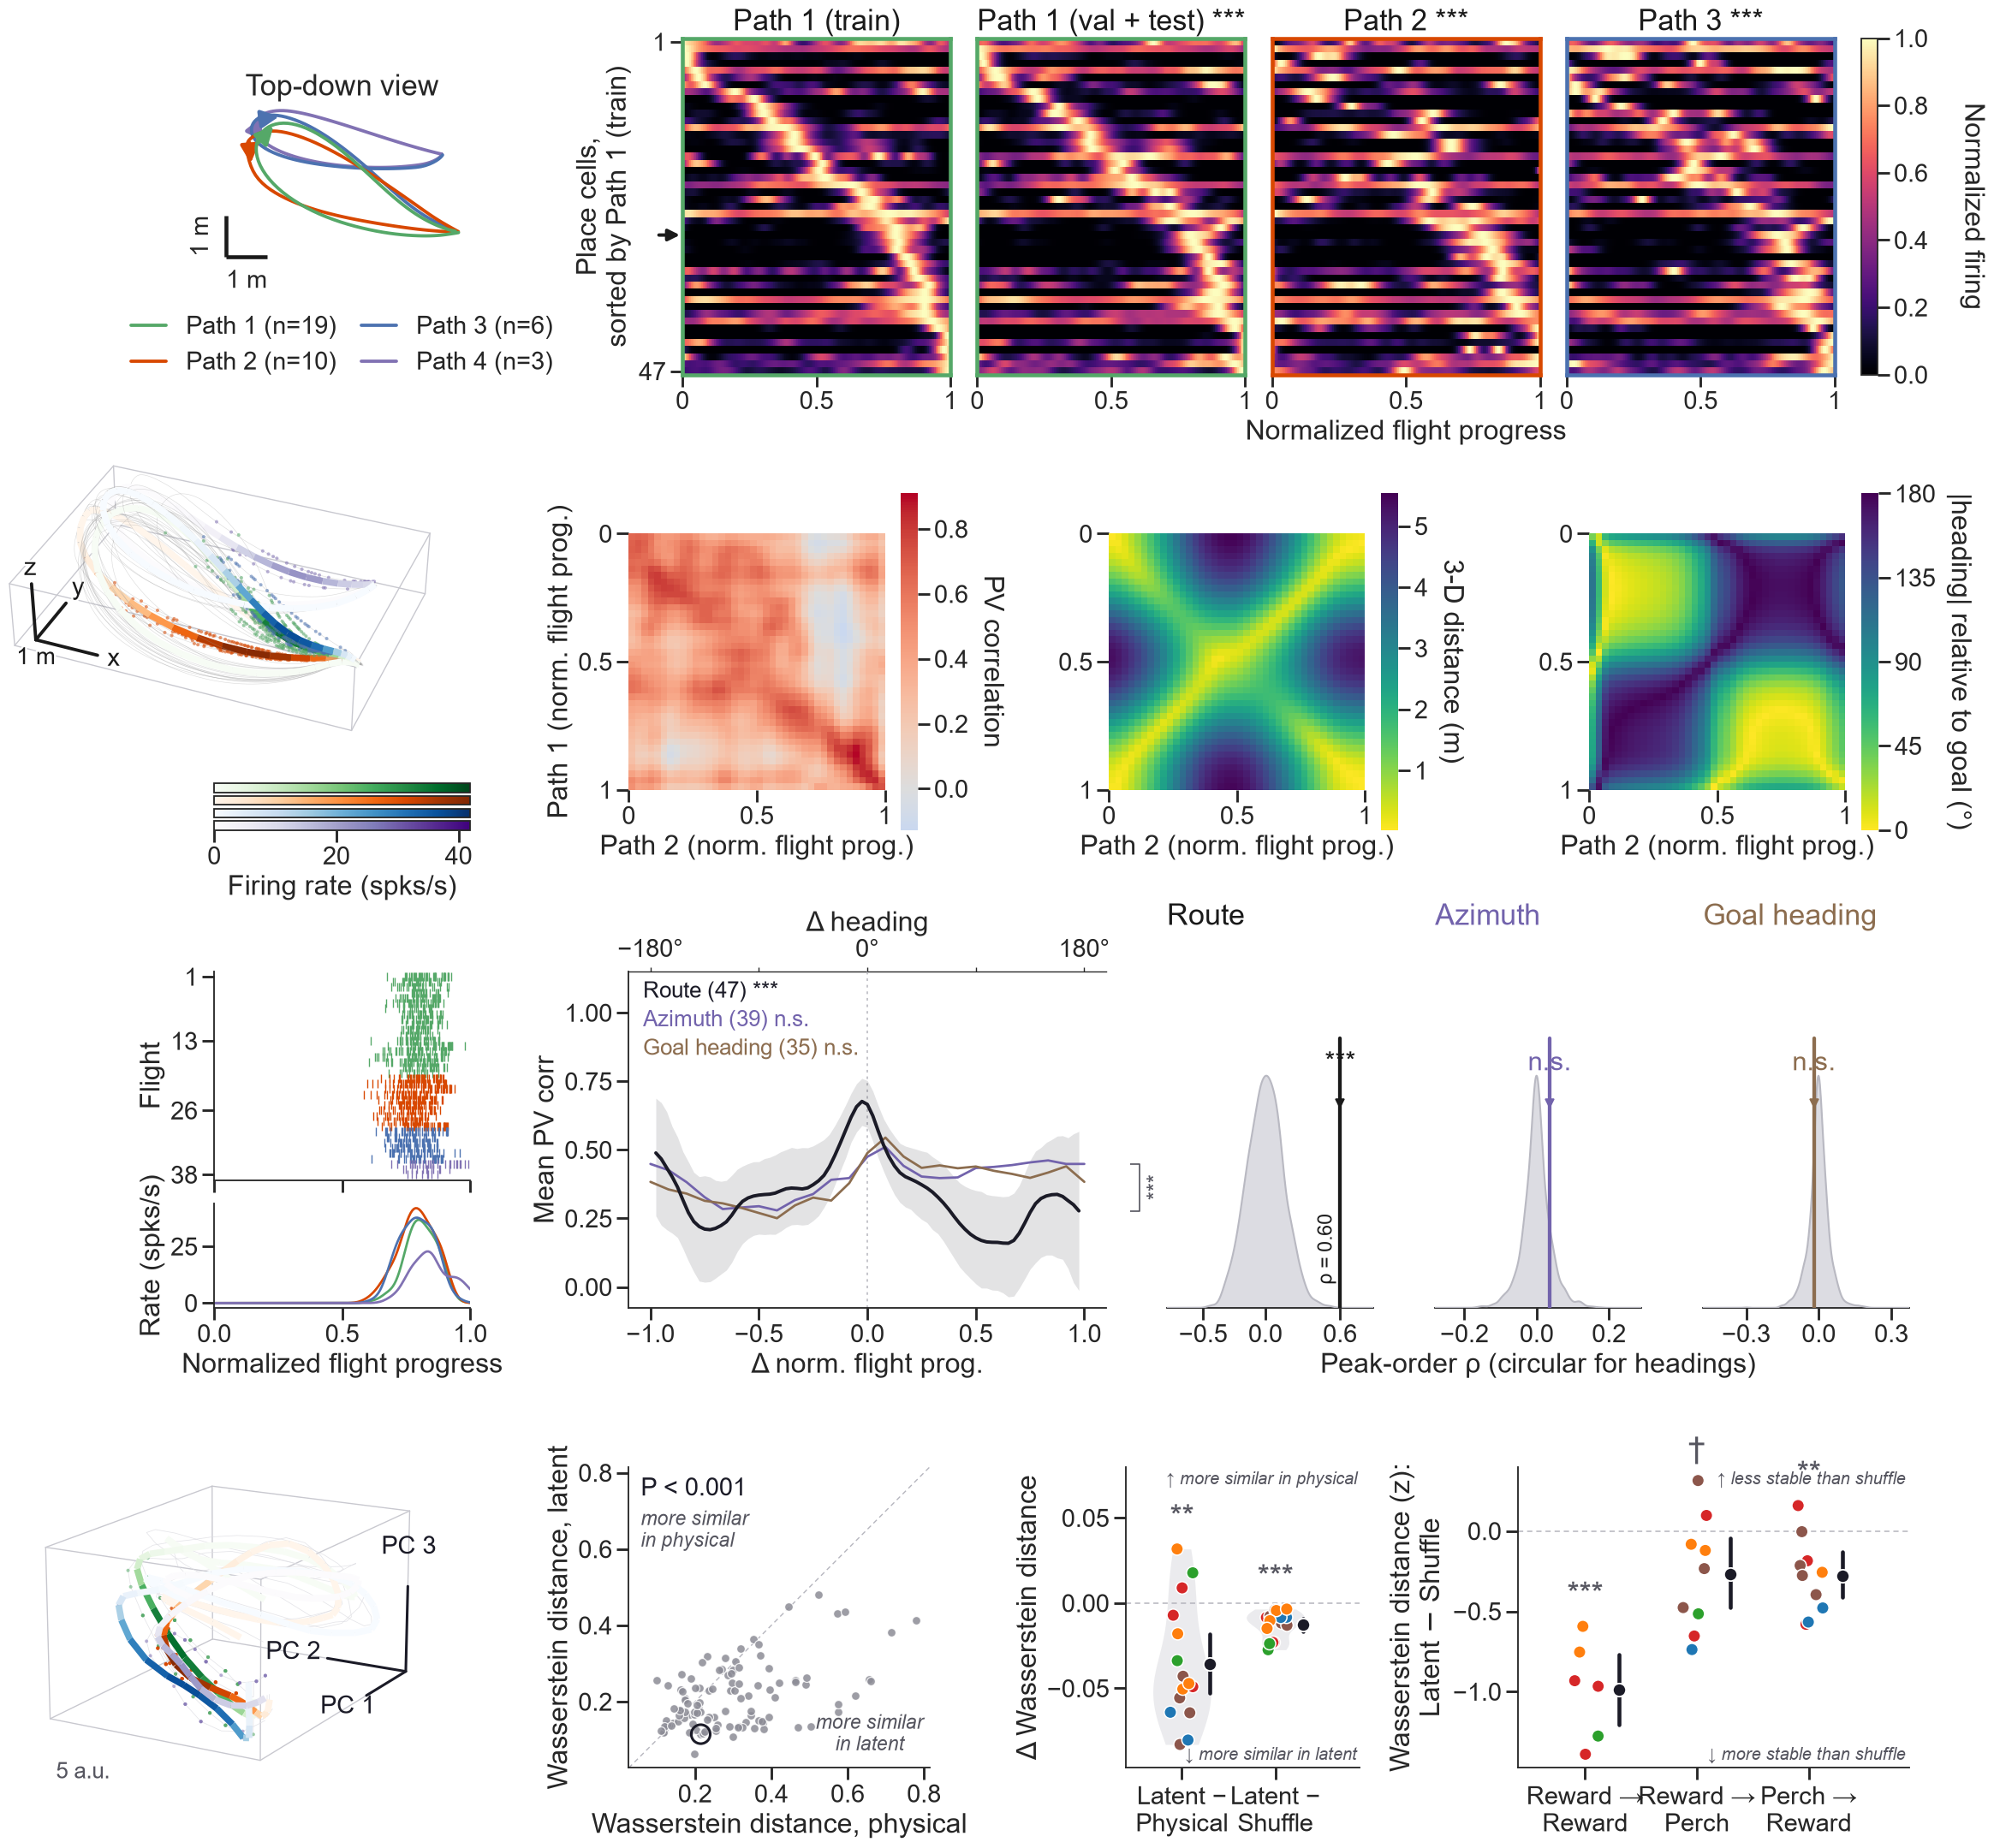


Figure 3 — rows 1-3, Path 1 vs Path 2 (one-sided permutation / shuffle / bootstrap p). The highlighted unit enters none of them:
                                                     test    obs         p  n_cells stars         P
      peak-order ρ, Path 1 (val + test) vs Path 1 (train)  0.909 0.0004998       47   *** P < 0.001
                   peak-order ρ, Path 2 vs Path 1 (train)  0.534 0.0004998       47   *** P < 0.001
                   peak-order ρ, Path 3 vs Path 1 (train)  0.543 0.0004998       47   *** P < 0.001
                   peak-order ρ, Path 4 vs Path 1 (train)  0.087    0.2734       47       P = 0.273
        Spearman ρ, peak time (Path 1 held out vs Path 2)  0.601 0.0004998       47   *** P < 0.001
     circular ρ, peak azimuth (Path 1 held out vs Path 2)  0.036    0.1384       39       P = 0.138
circular ρ, peak goal heading (Path 1 held out vs Path 2) -0.019    0.7456       35       P = 0.746
               PV near-vs-far, norm time (circular shift)  0.321 0.000

,metric,contrast,n_sess,p,route,n_neuron,sess_neg,med,t,shapiro,stars,P
0,Wasserstein,Latent − Physical,15,0.002625,NaN,NaN,NaN,NaN,NaN,NaN,**,P = 0.003
1,Wasserstein,Latent − Shuffle,15,0.000061,NaN,NaN,NaN,NaN,NaN,NaN,***,P < 0.001
2,Wasserstein distance,NaN,6,0.000502,rew→rew,565.0,6/6,-0.949,-7.97,0.778,***,P < 0.001
3,Wasserstein distance,NaN,9,0.053180,rew→perch,828.0,7/9,-0.234,-2.27,0.815,,P = 0.053
4,Wasserstein distance,NaN,10,0.004712,perch→rew,819.0,9/10,-0.267,-3.73,0.687,**,P = 0.005


In [24]:
# [figures.ipynb cell `fig3_multipath`]
# === Figure 3: one route, FOUR geometric paths, physical beside latent ===
# A 4 x 4 canvas over FOUR geometric paths of one route, on the session the rate-map example
# cell picks
# (`fig3_ratemap_motif_paths`: Dataset_1_32622_231009, reward->reward). Column 1 is the one
# highlighted unit in three renderings -- top-down behaviour, 3-D physical rate map, per-flight
# raster/PSTH -- with its latent twin directly beneath in row 4, so the physical and the latent
# rate map sit in the same column under one rate scale. Columns 2-4 carry the population
# read-outs. Panels are unlabelled and untitled: the caption names them.
#
#   row 1  A top-down, 4 paths      | D four sequence heatmaps (Paths 1-3, MP4_D_PATHS),
#                                     sorted on Path 1 (train), each carrying its
#                                     peak-order rho against that sort
#   row 2  B 3-D physical rate map  | E PV corr (Path 1 x Path 2) | F 3-D distance between the
#                                     same bin pairs | G |delta heading| relative to the goal
#   row 3  C raster + PSTH, 4 paths | H mean PV corr vs lag, 3 quantities | I the peak-order
#                                     shuffle test of each of those three (three sub-panels,
#                                     ONE letter)
#   row 4  J 3-D latent rate map    | K Wasserstein distance scatter, this session | L pooled
#                                     delta | M bin-free latent z by route
#
# Rows 2-3 read left to right as one argument: the PV correlation concentrates on the matched-
# time diagonal (E) even though the two paths are metres apart there (F) and their heading to
# the goal differs by up to 180 deg (G); H summarises all three as lag curves and I tests the
# peak ORDER on each of the three axes against a label permutation.
#
# WHAT IS COMPUTED WHERE. Everything in rows 2-3, columns 2-4 is the Path-1-vs-Path-2 analysis
# of `_route_example` verbatim -- place cells cross-validated on Path 1, the PV correlation
# matrix, its lag curves, the order tests and the two circular-shift near-vs-far tests -- so
# this figure introduces no second version of any published statistic. Paths 3 and 4 enter the
# DISPLAY panels only (A, B, C, D; E, F and G are Path 1 against Path 2 by construction): they
# are further geometric paths of the same route class, not further terms in a test. The one thing
# computed here is D's per-panel peak-order rho against the Path-1 TRAIN sort, which is the same
# Spearman + label-permutation test `_route_example` runs, applied to each drawn heatmap.
#
# ROW 4 CARRIES TWO DIFFERENT ESTIMATORS, not two views of one. K and L are the BINNED
# Wasserstein distance (`ratemap_sim` / `rm_diff`, physical 3-D vs the latent's 3-D PCA on a
# per-environment voxel grid), as a per-neuron scatter and as the pooled per-session
# difference. M is the BIN-FREE estimator (`_m4_binfree`, EMD over the actual sample points),
# which needs no grid and so can carry the FULL 15-D latent; there each value is a z against
# its OWN circular-shift null, so that panel shows the latent against chance rather than
# against physical, broken out by route.
#
# THE FOUR PATHS. Reward->reward is an endpoint CLASS, not a feeder pair: this room has two
# feeders, so the class holds paths between one pair of them (clusters 16 and 15, whose
# endpoints match to 0.03 / 0.04 m -- the only pair of this session `df_altpath` finds, Frechet
# 1.74 m) as well as paths that end at the OTHER feeder (9, 8). Paths 1-2 are therefore the
# endpoint-matched pair and every test in the figure runs on them; Paths 3-4 are the two
# remaining well-sampled paths of the class, and show how far the geometry moves inside one
# route label. `_m4_path_survey()` prints the whole table (flights, test flights, endpoint gaps,
# Frechet, spikes per highlighted unit) that the choice is made from.
#
# WHY NOT SIMPLY THE FOUR BEST-SAMPLED. Cluster 13 has 11 flights -- more than 9 or 8 -- but no
# flights in the test split, so it has no Twin latent and panel J would be blank for it. B and J
# have to show the same paths for the comparison between them to mean anything, so a path needs
# both >= MP4_MIN_FLIGHTS flights in the raw cache and >= MP4_MIN_TEST in the test split. The
# asymmetry that remains is unavoidable and is printed with the figure: A/B/C/D use every
# flight of each path (19/10/6/3 here), J only the flights that carry a latent (2/3/1/2).
MP4_SESSION = 'Dataset_1_32622_231009'
MP4_ROUTE = 'rew→rew'
# Path 1..4 as flight-cluster ids. Path 1 = REF and Path 2 = ALT of the pair handed to
# `_route_example`, which orders them by flight count, so MP4_PATHS[0] must be the
# better-sampled of the two (asserted below) and "Path 1 / Path 2" means the same thing in
# every panel. None = take the drawable clusters of MP4_ROUTE in flight-count order.
MP4_PATHS = [16, 15, 9, 8]
MP4_UNITS = [13]               # one figure per highlighted unit
MP4_CMAPS = ['Greens', 'Oranges', 'Blues', 'Purples']
MP4_COLORS = [sns.color_palette()[2], plt.cm.Oranges(0.75), sns.color_palette()[0],
              sns.color_palette()[4]]
# Draw order in panel B, front to back, as indices into MP4_PATHS. Path 3 (blue) is drawn
# FRONTMOST so its landing is not hidden by the other bands.
MP4_B_FRONT = [2, 0, 1, 3]
# How many paths get a sequence heatmap in D. The later paths still appear in A, B, C and J:
# with 3 flights and 44 spikes of this unit, Path 4's sequence panel is noise (its peak-order
# rho against the Path-1 train sort is 0.087, the only one of the four that is n.s.), so it is
# dropped from D while staying in the display panels. It is still scored in the printed table.
MP4_D_PATHS = 3
# The three quantities of H and of the I-K histograms, in order: (key, title, colour). 'motif'
# is normalized flight time -- the motif axis -- and is scored by a Spearman rho on peak time;
# the two heading axes are circular, so they are scored by the Fisher-Lee circular rank
# correlation `_route_example` returns in `head_order`.
MP4_QUANTITIES = [('motif', 'Route', 'k', 'Peak-order ρ'),
                  ('azimuth', 'Azimuth', AP_HEAD_STYLE['azimuth'][0], 'Peak-order circular ρ'),
                  ('rel', 'Goal heading', AP_HEAD_STYLE['rel'][0], 'Peak-order circular ρ')]
# Two lines each: three of these side by side do not fit on one line under a facet.
MP4_ROUTE_FULL = {'rew→rew': 'Reward →\nReward', 'rew→perch': 'Reward →\nPerch',
                  'perch→rew': 'Perch →\nReward'}
MP4_MIN_FLIGHTS = 3            # a path needs this many flights in the raw cache ...
MP4_MIN_TEST = 1               # ... and this many in the test split, or panel J is blank for it
# The BIN-FREE estimator behind M. Its ingredients (`RM_BF_ORDER` / `_rm_binfree_long`) live
# at the bottom of `fig3_ratemap_sim`, which computes and caches the table on panel M's first
# draw; this cell defers to them. The value below is a fallback only.
# The pair is physical 3-D against the 15-D latent (its first 15 principal components): the
# grid-free estimator exists so that more of the latent than a 3-D projection can be compared
# with physical 3-D, and the matched 3-D pair was the weaker of the two over sessions in the
# original analysis (pooled Wasserstein z, latent - physical: 15-D P = 2e-4 against 3-D
# P = 0.13), so this panel reports the 15-D analysis rather than a 3-D restatement of the
# binned panels beside it.
MP4_BF_ORDER = list(globals().get('RM_BF_ORDER', ['physical 3-D', 'latent 15-D']))
MP4_BF_SHORT = {'physical 3-D': 'Physical', 'latent 15-D': 'Latent', 'latent 3-D': 'Latent'}
# Fig 4's font sizes, on a canvas of the same size.
MP4_FS = dict(title=22, label=21, tick=19, star=24)
MP4_ROW1_DROP = 0.012          # figure fractions to drop row 1 by, closing the gap to row 2
# (J) is enlarged past its gridspec cell in the final pass: (left, right, vertical) growth in
# figure fractions. Overflowing left is deliberate -- there is nothing there but the margin, and
# the latent trajectories need the room; bbox_inches='tight' keeps whatever lands outside.
# Growth is LEFT-only: the right edge has to stay put, or the '5 a.u.' note that sits just
# outside it is pushed into the next panel's y label.
MP4_LATENT_GROW = (0.12, 0.0, 0.032)
# (B) gets the same left-spill treatment: (left, right, vertical) growth in figure
# fractions -- there is nothing in the left margin but whitespace ...
MP4_B_GROW = (0.050, 0.0, 0.018)
# ... plus a whole-panel (leftward, upward) translation: at its grown size the
# wireframe box grazed the panel to its right
MP4_B_SHIFT = (0.040, 0.024)
_m4_teh = np.linspace(0, 1, AP_N_TIME_HI + 1)
_m4_tch = (_m4_teh[:-1] + _m4_teh[1:]) / 2      # `_route_example`'s display grid
_m4_fs = MP4_FS


def _m4_binfree():
    """The bin-free table with its EMD z column, or None if it cannot be produced.

    Raw bin-free values are not comparable across spaces -- they carry each space's own units
    and grow with its dimension -- so each is expressed against ITS OWN circular-shift null:
    z = (observed - null)/sd for the EMD -- the literal Latent - Shuffle distance in units
    of the null's SD, so NEGATIVE = more stable than chance. No route or environment filter.
    The table is `_rm_binfree_long()` from `fig3_ratemap_sim` (computed once, then cached).
    """
    return _rm_binfree_long() if '_rm_binfree_long' in globals() else None


def _m4_test_flights(session):
    """{cluster: number of flights in the test split}, i.e. the flights that have a latent."""
    _m = emb['session'] == session
    return {int(_c): int(len(np.unique(emb['flight_id'][_m & (emb['cluster'] == _c)])))
            for _c in np.unique(emb['cluster'][_m])}


def _m4_route_of(session, cluster):
    """Endpoint-class label ('rew→rew', ...) of one flight cluster, in ph.ROUTE_LABELS form."""
    _t = session_data_cache[session]['cluster_info'][cluster]['mean_traj']
    _lb = {'reward': 'rew', 'perch': 'perch', 'other': 'other'}
    return _lb[_endpoint_label(session, _t[0])] + '→' + _lb[_endpoint_label(session, _t[-1])]


def _m4_path_survey(session=None, route=None, units=None):
    """Every flight cluster of one route: flights, test flights, endpoint gaps, spikes/unit.

    This is the table MP4_PATHS is chosen from. `n_test` counts the cluster's flights in `emb`
    (the test split, the only flights with a Twin latent), so a cluster with 0 there cannot
    appear in panel J. `gap_start` / `gap_end` are distances from Path 1's own endpoints, so a
    path reaching the other feeder of the same endpoint class shows up as a ~1.9 m gap.
    """
    session = MP4_SESSION if session is None else session
    route = MP4_ROUTE if route is None else route
    units = MP4_UNITS if units is None else units
    _ci = session_data_cache[session]['cluster_info']
    _d = session_data_cache[session]['data']
    _dff = session_data_cache[session]['df_flights']
    _ntest = _m4_test_flights(session)
    _cl = [_c for _c in sorted(_ci) if _m4_route_of(session, _c) == route]
    _ref = MP4_PATHS[0] if MP4_PATHS else max(_cl, key=lambda c: _ci[c]['n_flights'])
    _rows = []
    for _c in _cl:
        _t = _ci[_c]['mean_traj']
        _r = dict(cluster=_c, n_flights=_ci[_c]['n_flights'], n_test=_ntest.get(_c, 0),
                  path_len=round(float(np.sum(np.linalg.norm(np.diff(_t, axis=0), axis=1))), 2),
                  gap_start=round(float(np.linalg.norm(_t[0] - _ci[_ref]['mean_traj'][0])), 2),
                  gap_end=round(float(np.linalg.norm(_t[-1] - _ci[_ref]['mean_traj'][-1])), 2),
                  frechet=round(float(_frechet_d(_t, _ci[_ref]['mean_traj'])), 2))
        for _u in units:
            _r[f'spk_u{_u}'] = int(sum(
                ((_d['spike_times'][_u] >= _d['t'][int(_fr.f_start)])
                 & (_d['spike_times'][_u] <= _d['t'][int(_fr.f_stop)])).sum()
                for _, _fr in _dff[_dff.cluster_id == _c].iterrows()))
        _rows.append(_r)
    _t = pd.DataFrame(_rows).sort_values('n_flights', ascending=False)
    print(f'{session[8:]} — {route}: flight clusters (gaps / Frechet against cluster {_ref})')
    print(_t.to_string(index=False))
    _ok = list(_t[(_t['n_flights'] >= MP4_MIN_FLIGHTS)
                  & (_t['n_test'] >= MP4_MIN_TEST)]['cluster'])
    print(f'  drawable (>= {MP4_MIN_FLIGHTS} flights and >= {MP4_MIN_TEST} test flight): {_ok}'
          f'  ->  paths {MP4_PATHS if MP4_PATHS else _ok[:4]}')
    return _t, _ok


def _m4_rate(d, fldf, centers):
    """`_route_example`'s `_time_rate` outside its closure: the phase-tuning rate of every unit
    at `centers`, matching AP_PHASE ('time' = spike train * Gaussian with edge overflow,
    averaged over flights; 'space' = occupancy-normalized route-progress rate). Checked against
    the closure's own output for Path 1 by the assertion at the bottom of the cell."""
    nu = len(d['spike_times']); dt = 1.0 / d['Fs']
    gnorm = 1.0 / (AP_SMOOTH_SD * np.sqrt(2 * np.pi))
    rt = np.zeros((nu, len(centers))); den = np.zeros(len(centers)); nfl = 0
    for _, fr in fldf.iterrows():
        fs, fe = int(fr.f_start), int(fr.f_stop)
        ft = d['t'][fs:fe + 1]; dur = ft[-1] - ft[0]; nfl += 1
        prog = t_eval = None
        if AP_PHASE == 'space':
            prog = _prog(d['r'][fs:fe + 1])
            _zc = (centers[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
            den += np.exp(-0.5 * _zc * _zc).sum(1) * dt
        else:
            t_eval = ft[0] + centers * dur
        for u in range(nu):
            st = d['spike_times'][u]
            if AP_PHASE == 'time':
                stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD)
                         & (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                if len(stw):
                    z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                    rt[u] += gnorm * np.exp(-0.5 * z * z).sum(1)
            else:
                stf = st[(st >= ft[0]) & (st <= ft[-1])]
                if len(stf):
                    _zs = ((centers[:, None] - np.interp(stf, ft, prog)[None, :])
                           / AP_SMOOTH_SD_PROG)
                    rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
    return rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den, 1e-9)


def _m4_records(d, fldf, nrn):
    """`_route_example`'s `_neuron_records` outside its closure: per-flight 3-D paths, spike
    positions, and per-flight normalized spike phases for one unit."""
    paths, sp, raster = [], [], []
    for _, fr in fldf.iterrows():
        fs, fe = int(fr.f_start), int(fr.f_stop)
        ft = d['t'][fs:fe + 1]; xyz = d['r'][fs:fe + 1]; dur = ft[-1] - ft[0]
        paths.append(xyz)
        stu = d['spike_times'][nrn]; stu = stu[(stu >= ft[0]) & (stu <= ft[-1])]
        raster.append(np.empty(0) if not len(stu) else
                      ((stu - ft[0]) / dur if AP_PHASE == 'time'
                       else np.interp(stu, ft, _prog(xyz))))
        if len(stu):
            sp.append(np.column_stack([np.interp(stu, ft, xyz[:, k]) for k in range(3)]))
    return dict(paths=paths, spikes=np.vstack(sp) if sp else np.empty((0, 3)), raster=raster)


def _m4_resample(traj, n):
    """`_route_example`'s `_resample_traj`: by index (time) or arc length (space), per AP_PHASE."""
    src = _prog(traj) if AP_PHASE == 'space' else np.linspace(0.0, 1.0, len(traj))
    dst = np.linspace(0.0, 1.0, n)
    return np.column_stack([np.interp(dst, src, traj[:, k]) for k in range(traj.shape[1])])


def _m4_display(session, clusters, units):
    """Per-path display quantities: mean trajectory, the normalized-time rate of every unit on
    both the 40-bin analysis grid and the AP_N_TIME_HI display grid, and the per-flight records
    of each highlighted unit. Every flight of each path is used."""
    _d = session_data_cache[session]['data']
    _dff = session_data_cache[session]['df_flights']
    _ci = session_data_cache[session]['cluster_info']
    out = []
    for _i, _c in enumerate(clusters):
        _fl = _dff[_dff.cluster_id == _c]
        out.append(dict(cluster=int(_c), label=f'Path {_i + 1}', n=len(_fl), flights=_fl,
                        traj=_ci[_c]['mean_traj'], route=_m4_route_of(session, _c),
                        rate40=_m4_rate(_d, _fl, _tc), rate_hi=_m4_rate(_d, _fl, _m4_tch),
                        rec={_u: _m4_records(_d, _fl, _u) for _u in units}))
    return out


def _m4_order_tests(res, disp, seed_=1):
    """Peak-order Spearman rho of each drawn heatmap against the Path-1 TRAIN sort.

    The same statistic and label-permutation null as `_route_example`'s order test (which
    compares Path 1 held-out with Path 2); here every panel is scored against the map the sort
    itself comes from, `train_time`, so the stars in D read directly as "does this panel keep
    the sequence the rows were ordered by". Place cells only, peaks from the 40-bin analysis
    maps -- not the smoothed display maps that are drawn.
    """
    _pc = np.sort(np.asarray(res['order']))
    if not len(_pc):
        return []
    _mats = ([('Path 1 (train)', res['train_time']), ('Path 1 (val + test)', res['ref_time']),
              ('Path 2', res['alt_time'])]
             + [(_p['label'], _p['rate40']) for _p in disp[2:]])
    _rng = np.random.default_rng(seed_)
    _ref = res['train_time'][_pc].argmax(1)
    out = []
    for _i, (_lab, _M) in enumerate(_mats):
        _y = _M[_pc].argmax(1)
        if _i == 0:                       # the reference panel: rho = 1 by construction
            out.append(dict(panel=_lab, rho=1.0, p=None, n=len(_pc)))
            continue
        _r = float(_spearmanr(_ref, _y)[0])
        _nul = [float(_spearmanr(_ref, _rng.permutation(_y))[0]) for _ in range(AP_N_SHUF_SEQ)]
        out.append(dict(panel=_lab, rho=_r, n=len(_pc),
                        p=float((1 + np.sum(np.asarray(_nul) >= _r)) / (len(_nul) + 1))))
    return out


def _m4_sig(p, ns=True, dagger=True):
    """3-tier stars, or '†' for a marginal 0.05 <= P < 0.10, or 'n.s.' / ''.

    `ph._marker_for_p(p, dagger=True)` is the tier logic every bracket in the notebook already
    uses through `sig_bracket(dagger=True)`, so the thresholds live in one place.
    """
    if p is None or not np.isfinite(p):
        return ''
    return ph._marker_for_p(p, dagger=dagger) or ('n.s.' if ns else '')


def _m4_ttest(df, value_col, session_col='session', agg='median'):
    """One-sample t-test on per-session aggregates: the parametric counterpart of
    `ph.onesample_session_test`, used ONLY by the two per-route panels.

    Why parametric only there. Those panels test n = 6-10 sessions, and at those sizes the
    signed-rank is floor-limited: its smallest achievable two-sided P is 2/2**n, i.e. 0.031 at
    n = 6 and 0.0039 at n = 9, however large the effect -- two cells were pinned at exactly
    that floor. The pooled panels have n = 15, where the floor is 6e-5 and irrelevant, so they
    keep the nonparametric convention. The t-test spends that granularity for an assumption
    of approximate normality, so `shapiro` is returned with every P -- where it is below the
    0.05 mark the t-test is the WEAKER of the two, and the signed-rank is preferred there.
    Same keys as ph.onesample_session_test (n, p, med) plus `t`, `mean` and `shapiro`.
    """
    _v = df.groupby(session_col)[value_col].agg(agg).to_numpy(dtype=float)
    _v = _v[np.isfinite(_v)]
    _base = dict(n=len(_v), med=float(np.median(_v)) if len(_v) else np.nan,
                 mean=float(_v.mean()) if len(_v) else np.nan)
    if len(_v) < 2:
        return dict(_base, p=np.nan, t=np.nan, shapiro=np.nan)
    _t = stats.ttest_1samp(_v, 0.0)
    return dict(_base, p=float(_t.pvalue), t=float(_t.statistic),
                shapiro=float(stats.shapiro(_v).pvalue) if len(_v) >= 3 else np.nan)


def _m4_axl(short=False):
    if AP_PHASE == 'space':
        return 'norm. pos' if short else 'Normalized position'
    return 'norm. flight prog.' if short else 'Normalized flight progress'


def _m4_nice(x):
    """A round number (1, 2 or 5 x 10^k) at or just below `x`, for a scale bar's length."""
    _e = 10.0 ** np.floor(np.log10(max(x, 1e-9)))
    return float(next(_m * _e for _m in (5, 2, 1) if _m * _e <= x) if x >= _e else _e)


# ----------------------------------------------------------------- panels ----------------
def _m4_panel_A(ax, disp):
    """(A) Top-down (x-y) view of the four mean paths, with a 1-m scale-bar pair."""
    for _i, _p in enumerate(disp):
        _t = _p['traj']; _z = 6 - _i          # Path 1 drawn over the rest
        ax.plot(_t[:, 0], _t[:, 1], '-', color=MP4_COLORS[_i], lw=2.5, zorder=_z,
                label=f"{_p['label']} (n={_p['n']})")
        _m = len(_t) // 2
        ax.annotate('', xy=_t[_m + 4, :2], xytext=_t[_m - 4, :2], zorder=_z + 0.5,
                    arrowprops=dict(arrowstyle='-|>', color=MP4_COLORS[_i], lw=3,
                                    mutation_scale=28))
    ax.set_aspect('equal'); ax.axis('off')
    _ap = np.vstack([_p['traj'][:, :2] for _p in disp])
    _ex = max(np.ptp(_ap[:, 0]), np.ptp(_ap[:, 1]))
    _cx, _cy = _ap[:, 0].min() - 0.10 * _ex, _ap[:, 1].min() - 0.10 * _ex
    ax.plot([_cx, _cx + 1.0], [_cy, _cy], color='k', lw=3, solid_capstyle='butt', clip_on=False)
    ax.plot([_cx, _cx], [_cy, _cy + 1.0], color='k', lw=3, solid_capstyle='butt', clip_on=False)
    ax.text(_cx + 0.5, _cy - 0.06 * _ex, '1 m', ha='center', va='top', fontsize=_m4_fs['tick'])
    ax.text(_cx - 0.06 * _ex, _cy + 0.5, '1 m', ha='right', va='center', rotation=90,
            fontsize=_m4_fs['tick'])
    ax.set_title('Top-down view', fontsize=_m4_fs['title'])
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2,
              fontsize=_m4_fs['tick'], frameon=False, handlelength=1.4, columnspacing=1.0)


def _m4_panel_3d(ax, disp, neuron, rnorm):
    """(B) 3-D physical rate map: per path the resampled MEAN flight coloured by this unit's
    normalized-time rate, every individual flight faint underneath, spikes as dots. One
    colormap per path and ONE rate scale shared with the latent panel (L), so between the two
    only the coordinate system changes (Fig 3's panel-B grammar, four paths deep). Depth order
    is MP4_B_FRONT, not path order."""
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    _pts = []
    for _p in disp:
        _pts.append(_m4_resample(_p['traj'], _p['rate40'].shape[1]))
        _pts.extend(_p['rec'][neuron]['paths'])
        if len(_p['rec'][neuron]['spikes']):
            _pts.append(_p['rec'][neuron]['spikes'])
    _all = np.vstack(_pts)
    _lims = [(_all[:, _k].min(), _all[:, _k].max()) for _k in range(3)]
    _rank = {_p: _r for _r, _p in enumerate(MP4_B_FRONT)}
    for _i, _p in enumerate(disp):
        _rate = _p['rate40'][neuron]; _rec = _p['rec'][neuron]
        _z = 4 * (len(disp) - _rank.get(_i, _i))   # x4: leaves room for +1/+2 within a path,
        #                                            so no artist of one path ties with another
        for _xyz in _rec['paths']:
            ax.plot(_xyz[:, 0], _xyz[:, 1], _xyz[:, 2], color='0.6', lw=0.4, alpha=0.35,
                    zorder=_z)
        _rs = _m4_resample(_p['traj'], len(_rate)).reshape(-1, 1, 3)
        _lc = Line3DCollection(np.concatenate([_rs[:-1], _rs[1:]], axis=1),
                               cmap=MP4_CMAPS[_i], norm=rnorm)
        _lc.set_array(0.5 * (_rate[:-1] + _rate[1:])); _lc.set_linewidth(5.0)
        _lc.set_zorder(_z + 2)
        ax.add_collection(_lc)
        if len(_rec['spikes']):
            ax.scatter(_rec['spikes'][:, 0], _rec['spikes'][:, 1], _rec['spikes'][:, 2], s=7,
                       color=MP4_COLORS[_i], alpha=0.55, edgecolors='none', depthshade=False,
                       zorder=_z + 1)
    ax.set_xlim(_lims[0]); ax.set_ylim(_lims[1]); ax.set_zlim(_lims[2])
    # zoom > 1: this room is 5.4 x 4.3 x 1.4 m, so a data-proportional box is very flat and
    # mplot3d leaves most of the axes empty around it. zoom scales the drawing inside the axes
    # without touching the aspect, so 1 m stays 1 m on every axis. The zoom is ROOM-AWARE:
    # mplot3d normalises the box by its diagonal, so a very long room (the 9 m outdoor
    # arena) projects its long axis ~max(span)/|spans| wide, and at a fixed 1.35 the paths
    # ran off the CANVAS entirely -- which no clip_on setting can recover. Scale the zoom
    # so the long axis keeps the default-cube footprint (x1.25 licensed overshoot, since
    # everything here draws unclipped), capped at the 1.35 the indoor rooms were tuned to
    # (indoor evaluates above the cap, so those panels are unchanged).
    _spans3 = np.array([max(_l[1] - _l[0], 1e-3) for _l in _lims], float)
    _zoom3 = min(1.35, 1.35 * 1.25 * 1.143 * float(np.linalg.norm(_spans3))
                 / (1.8294 * float(_spans3.max())))
    ax.set_box_aspect(list(_spans3), zoom=_zoom3)
    ax.view_init(elev=35, azim=-68)
    # kit voice, matching panel J: panes/gridlines dropped, a thin light wireframe box
    # around the data instead; the metre scale triad stays
    ax.set_axis_off()
    for _s3, _e3 in [((0, 0, 0), (1, 0, 0)), ((0, 0, 0), (0, 1, 0)), ((0, 0, 0), (0, 0, 1)),
                     ((1, 0, 0), (1, 1, 0)), ((1, 0, 0), (1, 0, 1)), ((0, 1, 0), (1, 1, 0)),
                     ((0, 1, 0), (0, 1, 1)), ((0, 0, 1), (1, 0, 1)), ((0, 0, 1), (0, 1, 1)),
                     ((1, 1, 0), (1, 1, 1)), ((1, 0, 1), (1, 1, 1)), ((0, 1, 1), (1, 1, 1))]:
        # clip_on=False: 3-D lines clip at the AXES rectangle by default, and with
        # zoom > 1 the oblong room's projected corners extend past it (the mystery
        # crop that followed this panel around)
        ax.plot(*[[_lims[_d][0] + (_lims[_d][1] - _lims[_d][0]) * _s3[_d],
                   _lims[_d][0] + (_lims[_d][1] - _lims[_d][0]) * _e3[_d]]
                  for _d in range(3)], lw=0.9, color='#C8C8CF', zorder=0,
                clip_on=False)
    nh.add_3d_scalebar(ax, corner=(0, 0, 0), fontsize=_m4_fs['tick'], hide_frame=False,
                       z_nudge=(0.0, 0.0, 0.12), x_nudge=(-0.07, 0.0, 0.0))
    # the DATA artists (paths, rate tube, spikes) clip at the axes rectangle just like
    # the wireframe did: with zoom > 1 an elongated room's projection spills past the
    # rect, cropping the paths where the (already unclipped) box was not. Unclip every
    # artist -- this panel has only whitespace gutters around it.
    for _art3 in list(ax.lines) + list(ax.collections):
        _art3.set_clip_on(False)


def _m4_panel_latent(ax, session, disp, neuron, rnorm, length=None):
    """(J) The same unit in the Twin latent's PC 1-3 -- panel B's grammar, drawn in the
    wireframe style: no grey panes, gridlines or boxed axes, only a thin wireframe box around the data, with an ink PC-1/2/3 triad and an 'a.u.' scale
    note at its corner (PC units are arbitrary, so the length is a round number of latent
    units rather than metres).

    `length` overrides that round number with an explicit bar length in latent units, for a
    caller whose panel is a different size (ED Fig 9 asks for a shorter bar). None = as before."""
    rm_latent_unit_panel(ax, session, [_p['cluster'] for _p in disp], neuron,
                         [_p['rate40'][neuron] for _p in disp], MP4_CMAPS, MP4_COLORS, rnorm)
    # mplot3d's default view (30, -60), then -90 deg about PC 3, the vertical axis
    ax.view_init(elev=16, azim=-150)
    # as in panel B, but gentler: the latent box is nearly isotropic, so it already fills the
    # axes, and a larger zoom pushes the triad off the left edge of the figure
    ax.set_box_aspect(ax.get_box_aspect(), zoom=1.10)
    _len = float(length) if length else _m4_nice(
        max(np.ptp(ax.get_xlim()), np.ptp(ax.get_ylim()), np.ptp(ax.get_zlim())) / 3.0)
    _lo3 = np.array([ax.get_xlim()[0], ax.get_ylim()[0], ax.get_zlim()[0]])
    _hi3 = np.array([ax.get_xlim()[1], ax.get_ylim()[1], ax.get_zlim()[1]])
    ax.set_axis_off()                     # no panes / gridlines / boxed axes ...
    for _s3, _e3 in [((0, 0, 0), (1, 0, 0)), ((0, 0, 0), (0, 1, 0)), ((0, 0, 0), (0, 0, 1)),
                     ((1, 0, 0), (1, 1, 0)), ((1, 0, 0), (1, 0, 1)), ((0, 1, 0), (1, 1, 0)),
                     ((0, 1, 0), (0, 1, 1)), ((0, 0, 1), (1, 0, 1)), ((0, 0, 1), (0, 1, 1)),
                     ((1, 1, 0), (1, 1, 1)), ((1, 0, 1), (1, 1, 1)), ((0, 1, 1), (1, 1, 1))]:
        ax.plot(*[[_lo3[_d] + (_hi3[_d] - _lo3[_d]) * _s3[_d],
                   _lo3[_d] + (_hi3[_d] - _lo3[_d]) * _e3[_d]] for _d in range(3)],
                lw=0.9, color='#C8C8CF', zorder=0,   # ... but a thin wireframe box
                clip_on=False)                       # (unclipped, as in B)
    # ink PC triad at the near-bottom corner for this view -- (xmax, ymin, zmin) at
    # azim=-150 -- with the scale note beside it
    _o3 = np.array([_hi3[0], _lo3[1], _lo3[2]])
    for _v3, _lab3 in [((-_len, 0, 0), 'PC 1'), ((0, _len, 0), 'PC 2'), ((0, 0, _len), 'PC 3')]:
        _v3 = np.asarray(_v3, float)
        ax.plot(*np.c_[_o3, _o3 + _v3], lw=2.0, color=ph.INK, solid_capstyle='round',
                zorder=6)
        ax.text(*(_o3 + _v3 * 1.45), _lab3, fontsize=_m4_fs['tick'], color=ph.INK,
                ha='center', va='center', zorder=7)
    # scale note kept off the triad (clear of the PC-1 bar region): quiet text
    # in the panel's lower-left corner
    ax.text2D(0.04, 0.06, f'{_len:g} a.u.', transform=ax.transAxes,
              fontsize=_m4_fs['tick'] - 2, color=ph.INK_SOFT, ha='left', va='bottom')


def _m4_panel_raster(fig, cell, disp, neuron):
    """(C) Per-flight raster over the per-path PSTH, all four paths, normalized time. The PSTH
    is exactly the rate the two 3-D panels colour by, so they cannot disagree."""
    _rg = cell.subgridspec(2, 1, height_ratios=[2, 1], hspace=0.15)
    _ax_r = fig.add_subplot(_rg[0]); _ax_p = fig.add_subplot(_rg[1], sharex=_ax_r)
    _yb = 1
    for _i, _p in enumerate(disp):
        for _r in _p['rec'][neuron]['raster']:
            if len(_r):
                _ax_r.plot(_r, np.full(len(_r), _yb), '|', color=MP4_COLORS[_i],
                           markersize=6, mew=0.9)
            _yb += 1
    _nfl = _yb - 1
    _tk = np.unique(np.linspace(1, _nfl, 4 if _nfl >= 13 else 3).round().astype(int))
    _ax_r.set_xlim(0, 1); _ax_r.set_ylim(_nfl + 1, 0)     # flight 1 at the top, last not clipped
    _ax_r.set_yticks(_tk[(_tk >= 1) & (_tk <= _nfl)])
    _ax_r.set_ylabel('Flight', fontsize=_m4_fs['label'])
    _ax_r.tick_params(labelbottom=False, labelsize=_m4_fs['tick'])
    _xt = np.linspace(0, 1, disp[0]['rate_hi'].shape[1])
    for _i, _p in enumerate(disp):
        _ax_p.plot(_xt, _p['rate_hi'][neuron], color=MP4_COLORS[_i], lw=1.8)
    _ax_p.set_xlim(0, 1)
    _ax_p.set_xlabel(_m4_axl(), fontsize=_m4_fs['label'])
    _ax_p.set_ylabel('Rate (spks/s)', fontsize=_m4_fs['label'])
    _ax_p.tick_params(labelsize=_m4_fs['tick'])
    sns.despine(ax=_ax_r); sns.despine(ax=_ax_p)


def _m4_panel_heatmaps(fig, cell, res, disp, neuron, order_tests):
    """(D) Sequence heatmaps -- Path 1 train, Path 1 held out, then Paths 2..MP4_D_PATHS -- each
    one sorted by the Path-1 TRAIN peak time and sharing one colour scale. Each panel is framed
    in its path's colour (panel A's legend) and its title carries the peak-order rho against
    that sort, with stars from the label-permutation null. The first three matrices come straight
    from `_route_example`, so the train / held-out split is the one the place cells and the PV
    analysis used; the rest are the same display rate over all of that path's flights."""
    _order = res['order']
    _panels = ([(res['train_time_hi'], 'Path 1 (train)', MP4_COLORS[0]),
                (res['ref_time_hi'], 'Path 1 (val + test)', MP4_COLORS[0]),
                (res['alt_time_hi'], 'Path 2', MP4_COLORS[1])]
               + [(_p['rate_hi'], _p['label'], MP4_COLORS[_i + 2])
                  for _i, _p in enumerate(disp[2:MP4_D_PATHS])])
    _n = len(_panels)
    _st = {_t['panel']: _t for _t in order_tests}
    _hg = cell.subgridspec(1, _n + 2, width_ratios=[1] * _n + [0.06, 0.22], wspace=0.14)
    _axes = [fig.add_subplot(_hg[0, _i]) for _i in range(_n)]
    _cax = fig.add_subplot(_hg[0, _n])
    for _k, (_M, _name, _col) in enumerate(_panels):
        _ax = _axes[_k]
        _H = (_M[_order] / np.maximum(_M[_order].max(1, keepdims=True), 1e-9)
              if len(_order) else _M[:0])
        sns.heatmap(_H, ax=_ax, cmap='magma', vmin=0, vmax=1, cbar=False,
                    xticklabels=False, yticklabels=False)
        _t = _st.get(_name)
        _ax.set_title(_name if _t is None or _t['p'] is None
                      else f"{_name} {_m4_sig(_t['p'])}",
                      fontsize=_m4_fs['title'], color='k')
        for _sp in _ax.spines.values():         # frame each panel in its path colour
            _sp.set_visible(True); _sp.set_color(_col); _sp.set_linewidth(3.0)
        _nt = _H.shape[1]
        _ax.set_xticks([0, _nt / 2, _nt]); _ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
        _ax.tick_params(labelsize=_m4_fs['tick'])
        # one x label for the row, under the middle panel
        _ax.set_xlabel(_m4_axl() if _k == _n // 2 else '', fontsize=_m4_fs['label'])
        if _k == 0 and len(_order):
            _ax.set_ylabel('Place cells,\nsorted by Path 1 (train)', fontsize=_m4_fs['label'])
            _ax.set_yticks([0.5, len(_order) - 0.5])
            _ax.set_yticklabels(['1', str(len(_order))], rotation=0)
        else:
            _ax.set_ylabel('')
    _row = np.where(np.asarray(_order) == neuron)[0]
    if len(_row):                              # arrowhead on the highlighted unit's row
        _axes[0].annotate('', xy=(0, _row[0] + 0.5), xytext=(-20, 0),
                          textcoords='offset points', xycoords='data', va='center',
                          annotation_clip=False, zorder=6,
                          arrowprops=dict(arrowstyle='-|>', color='k', lw=2.6))
    if len(_order):
        _cb = fig.colorbar(_axes[-1].collections[0], cax=_cax)
        _cb.set_label('Normalized firing', rotation=270, labelpad=24, va='bottom',
                      fontsize=_m4_fs['label'])
        _cb.ax.tick_params(labelsize=_m4_fs['tick'])
    else:
        _cax.axis('off')
    return _cax, _axes


def _m4_matrix(ax, M, cmap, cbar_label, center=None, vmin=None, vmax=None, cbar_ticks=None,
               cbar_ticklabels=None, ylabel=True):
    """A (Path-1 bin x Path-2 bin) heatmap with the shared axis labelling of E, F and G.

    `cbar_ticklabels` is the escape hatch for the right-hand matrix: only ~0.7 in separates its
    colourbar from the next column's y label, which is not enough for a rotated colourbar label
    as well, so that panel carries its unit in the tick labels instead.
    """
    _n = M.shape[0]
    sns.heatmap(M, ax=ax, cmap=cmap, center=center, vmin=vmin, vmax=vmax,
                xticklabels=False, yticklabels=False)
    _cb = ax.collections[0].colorbar
    _cb.ax.tick_params(labelsize=_m4_fs['tick'])
    if cbar_ticks is not None:
        _cb.set_ticks(cbar_ticks)
        _cb.set_ticklabels(cbar_ticks if cbar_ticklabels is None else cbar_ticklabels)
    if cbar_label:
        # labelpad stays small: this label sits between two columns, and at Fig-4 font sizes a
        # generous pad puts it on top of the next panel's y label
        _cb.set_label(cbar_label, rotation=270, labelpad=8, va='bottom',
                      fontsize=_m4_fs['label'])
    ax.set_xlabel(f'Path 2 ({_m4_axl(True)})', fontsize=_m4_fs['label'])
    # one y label for the row: all three matrices carry the same Path-1 axis
    ax.set_ylabel(f'Path 1 ({_m4_axl(True)})' if ylabel else '', fontsize=_m4_fs['label'])
    ax.set_xticks([0, _n / 2, _n]); ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
    ax.set_yticks([0, _n / 2, _n]); ax.set_yticklabels(['0', '0.5', '1'], rotation=0)
    ax.tick_params(labelsize=_m4_fs['tick'])
    ax.set_box_aspect(1)
    return _cb.ax


def _m4_goal_heading_mat(res, session):
    """(G) |delta heading| relative to the goal between the two mean paths at every (Path-1 bin, Path-2 bin)
    pair, in degrees. The behavioural counterpart of panel F: F carries the 3-D
    Euclidean distance between the same bin pairs, this one the circular difference in heading
    relative to the reward each path ends on ('goal' = the feeder that flight lands at). Its
    diagonal is what the matched-time PV correlation is being compared against -- if the
    sequence rode on goal heading rather than on time, the PV structure in E would follow the
    dark band here instead of the diagonal."""
    _p1, _p2 = res['traj_ref_rs'], res['traj_alt_rs']
    _h1 = _rel_heading(_p1, _future_reward(session, _p1))
    _h2 = _rel_heading(_p2, _future_reward(session, _p2))
    return np.degrees(np.abs((_h1[:, None] - _h2[None, :] + np.pi) % (2 * np.pi) - np.pi))


def _m4_panel_lag(fig, ax, res):
    """(H) Mean PV corr vs lag for the three quantities the matrix can be indexed on:
    normalized time (place cells), allocentric azimuth and goal heading (each on its OWN
    ring-tuned cells). +-180 deg of heading lag is mapped onto the +-1 of time lag so one x axis
    carries all three, and the top axis reads the degrees off. Restyle-kit voice: a bold ink
    route curve over a soft CI band, the heading curves in their own hues, a frameless
    coloured-text key (each row carrying that curve's near-vs-far result), and the paired
    place-vs-heading comparisons as hairline brackets in the right margin spanning the two
    curves' ends. Same curves, same statistics as before."""
    # the per-curve near-vs-far results drop the dagger tier: a trend on one of the heading
    # curves reads as a positive finding in a key row, where there is no bracket to scope it
    _sig_curve = lambda p: _m4_sig(p, dagger=False)
    _hlag = res.get('head_lag') or {}
    ax.axvline(0, ls=(0, (2, 3)), lw=1.0, color=ph.GRID_GREY, zorder=1)
    if res.get('pv_lag_lo') is not None:
        ax.fill_between(res['lags'], res['pv_lag_lo'], res['pv_lag_hi'], color=ph.INK,
                        alpha=0.12, lw=0, zorder=2)
    ax.plot(res['lags'], res['pv_lag'], color=ph.INK, lw=2.6, zorder=4,
            solid_capstyle='round')
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        ax.plot(np.append(res['head_lags_deg'], 180.0) / 180.0,
                np.append(_hlag[_hk], _hlag[_hk][0]), color=_hcol, lw=1.8, zorder=3)
    ax.set_xlabel('Δ norm. flight prog.', fontsize=_m4_fs['label'])
    ax.set_ylabel('Mean PV corr', fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'])
    if _hlag:
        _sec = ax.secondary_xaxis('top', functions=(lambda v: v * 180.0, lambda d: d / 180.0))
        _sec.set_xticks([-180, -90, 0, 90, 180])
        _sec.set_xticklabels(['−180°', '', '0°', '', '180°'], fontsize=_m4_fs['tick'])
        _sec.spines['top'].set_linewidth(0.9)          # quiet hairline top axis
        _sec.tick_params(width=0.9, length=3.5)
        _sec.set_xlabel('Δ heading', fontsize=_m4_fs['label'], labelpad=6)
        _lo, _hi = ax.get_ylim(); ax.set_ylim(_lo, _hi + 0.40 * (_hi - _lo))
    # frameless coloured-text key; one row per curve, its own
    # near-vs-far result appended -- the same numbers as the printed tests
    _rows = [(ph.INK, f"Route ({res['n_place']})"
              + (f" {_sig_curve(res['p_peak'])}" if res.get('p_peak') is not None else ''))]
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        _hp = (res.get('p_head') or {}).get(_hk)
        _rows.append((_hcol, f"{_hlab[:1].upper()}{_hlab[1:]} "
                      f"({len((res.get('pc_head') or {}).get(_hk, []))})"
                      + (f' {_sig_curve(_hp)}' if _hp is not None else '')))
    for _ri, (_col, _txt) in enumerate(_rows):
        ax.text(0.03, 0.97 - _ri * 0.085, _txt, transform=ax.transAxes,
                fontsize=_m4_fs['tick'] - 2, color=_col, ha='left', va='top')
    # paired place-vs-heading comparisons: hairline brackets in the RIGHT margin, each
    # spanning the route curve's end and that heading curve's end (stars keep the dagger)
    def _endv(_c):
        _c = np.asarray(_c, float)
        return float(_c[np.isfinite(_c)][-1])
    _cmps = [(_hk, (res.get('head_vs_place') or {}).get(_hk)) for _hk in AP_HEAD_STYLE
             if _hlag.get(_hk) is not None
             and (res.get('head_vs_place') or {}).get(_hk) is not None]
    _tr = ax.get_yaxis_transform()          # x axes-fraction, y data
    for _ci, (_hk, _cmp) in enumerate(_cmps):
        _x0 = 1.05 + _ci * 0.10
        _y0, _y1 = _endv(res['pv_lag']), _endv(_hlag[_hk])
        ax.plot([_x0, _x0 + 0.02, _x0 + 0.02, _x0], [_y0, _y0, _y1, _y1],
                transform=_tr, lw=1.1, color=ph.INK_SOFT, clip_on=False,
                solid_capstyle='butt', zorder=6)
        ax.text(_x0 + 0.035, (_y0 + _y1) / 2, _m4_sig(_cmp['p']), transform=_tr,
                fontsize=_m4_fs['star'] - 7, color=ph.INK_SOFT, rotation=90,
                ha='left', va='center', clip_on=False, zorder=6)
    sns.despine(ax=ax)


def _m4_panel_null(ax, obs, null, p, color, title, xlabel='', obs_label=False):
    """(I) One label-permutation shuffle null per quantity of panel H, as one RIDGE of a
    stacked column: a smooth grey kernel density (Scott's bandwidth; the same null draws),
    the observed statistic as a line in its panel-H colour with a locator triangle and the
    significance above it, and the test name as a coloured row label (no legend). Density
    y-ticks are dropped -- the shape carries the information -- and every ridge keeps its
    OWN x-axis, since the three statistics live on different scales. Motif (normalized
    time) is scored by Spearman rho, the two heading axes by the Fisher-Lee circular rank
    correlation; all three come from `_route_example`, which keeps its null draws, so
    these are the very draws behind the reported P. `obs_label=True` also prints the
    headline value on the line and adds it to the axis ticks."""
    ax.text(0.0, 1.12, title, transform=ax.transAxes, fontsize=_m4_fs['title'],
            color=color, ha='left', va='bottom')
    if null is None or obs is None:
        ax.axis('off'); return
    from scipy.stats import gaussian_kde as _gkde
    _n9 = np.asarray(null, float); _n9 = _n9[np.isfinite(_n9)]
    _k9 = _gkde(_n9)                                  # Scott's rule
    _pad9 = 0.35 * ((_n9.max() - _n9.min()) or 1.0)
    _x9 = np.linspace(_n9.min() - _pad9, _n9.max() + _pad9, 400)
    _y9 = _k9(_x9); _y9 = _y9 / _y9.max()
    ax.fill_between(_x9, 0, _y9, color=ph.KDE_FILL, lw=0, zorder=2)
    ax.plot(_x9, _y9, lw=1.4, color=ph.KDE_EDGE, zorder=3)
    ax.axvline(obs, ymax=0.80, lw=2.8, color=color, zorder=4, solid_capstyle='round')
    ax.plot(obs, 0.88, marker='v', ms=7, color=color, zorder=5)
    ax.text(obs, 1.00, _m4_sig(p), ha='center', va='bottom',
            fontsize=_m4_fs['star'] - 4, color=color)
    _lo9 = min(_x9.min(), obs - 0.06 * (_x9.max() - _x9.min()))
    _hi9 = max(_x9.max(), obs + 0.12 * (_x9.max() - _x9.min()))
    ax.set_xlim(_lo9, _hi9); ax.set_ylim(0, 1.45)
    _t9 = round(float(np.nanmax(np.abs(_n9))), 1) or 0.1
    _ticks9 = [-_t9, 0.0, _t9]
    if obs_label:                    # headline value on the line AND on the axis
        _or9 = round(float(obs), 1)
        # drop any tick the headline tick would collide with, then add it
        _ticks9 = sorted({_tk for _tk in _ticks9
                          if abs(_tk - _or9) > 0.30 * _t9} | {_or9})
        ax.text(obs - 0.02 * (_hi9 - _lo9), 0.10, f'ρ = {obs:.2f}', rotation=90,
                ha='right', va='bottom', fontsize=_m4_fs['tick'] - 4, color=color)
    ax.set_xticks(_ticks9)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.set_xlabel(xlabel, fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'] - 2)
    sns.despine(ax=ax, left=True)


def _m4_panel_scatter(ax, prefix, lab, session, neuron):
    """(K) Per-neuron physical vs latent BINNED Wasserstein distance for every route of this
    session (route is broken out in M instead), with the unit drawn in column 1 circled.
    Restyle-kit voice: quiet grey dots with a white rim, a grey dashed unity line, the P as
    plain text, and italic notes naming the two sides of unity (lower = more stable, so the
    points BELOW the line are the neurons whose latent map is the more similar one)."""
    _s = ratemap_sim[ratemap_sim['session'] == session].dropna(
        subset=[f'{prefix}_physical', f'{prefix}_latent'])
    ax.scatter(_s[f'{prefix}_physical'], _s[f'{prefix}_latent'], s=42, alpha=0.85,
               facecolor='#8C8C96', edgecolors='white', linewidths=0.8, zorder=3)
    # circle ONE point: this unit on the route the rest of the figure is about. It also
    # contributes a row to the other routes of this session, but circling those would read as
    # several example units.
    _u = _s[(_s['neuron'] == neuron) & (_s['route'] == MP4_ROUTE)]
    ax.scatter(_u[f'{prefix}_physical'], _u[f'{prefix}_latent'], s=210, facecolors='none',
               edgecolors=ph.INK, linewidths=2.0, zorder=5)
    if len(_s):
        _lo = float(min(_s[f'{prefix}_physical'].min(), _s[f'{prefix}_latent'].min()))
        _hi = float(max(_s[f'{prefix}_physical'].max(), _s[f'{prefix}_latent'].max()))
        _pad = 0.05 * (_hi - _lo)
        ax.plot([_lo - _pad, _hi + _pad], [_lo - _pad, _hi + _pad], ls=(0, (4, 3)),
                color=ph.GRID_GREY, lw=0.9, zorder=1)
        ax.set_xlim(_lo - _pad, _hi + _pad); ax.set_ylim(_lo - _pad, _hi + _pad)
        _w = stats.wilcoxon(_s[f'{prefix}_latent'], _s[f'{prefix}_physical'])
        ax.text(0.04, 0.965, ph.fmt_p(float(_w.pvalue)), transform=ax.transAxes, ha='left',
                va='top', fontsize=_m4_fs['tick'], color=ph.INK)
        # Wasserstein DISTANCE semantics: above unity = the latent map moved more
        ax.text(0.04, 0.86, 'more similar\nin physical', transform=ax.transAxes,
                fontsize=_m4_fs['tick'] - 4, color=ph.INK_SOFT, style='italic',
                ha='left', va='top')
        ax.text(0.80, 0.04, 'more similar\nin latent', transform=ax.transAxes,
                fontsize=_m4_fs['tick'] - 4, color=ph.INK_SOFT, style='italic',
                ha='center', va='bottom')
    ax.set_aspect('equal')
    ax.set_xlabel(f'{lab}, physical', fontsize=_m4_fs['label'])
    ax.set_ylabel(f'{lab}, latent', fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'])
    sns.despine(ax=ax)
    return len(_s), len(_u)


def _m4_mean_ci(ax, values, pos, color='k', mean_lw=2.6, ci=95, n_boot=2000, seed_=0):
    """The across-session mean +/- CI marker Figs 1 and 4 use: `sns.pointplot` with exactly the
    styling `ph.paired_lineplot` gives its black overlay, so every summary in the notebook reads
    the same. Drawn on a numeric x with `native_scale`, so it lands on the swarm it summarises."""
    _v = np.asarray(values, float); _v = _v[np.isfinite(_v)]
    if not len(_v):
        return
    sns.pointplot(data=pd.DataFrame({'_x': pos, 'value': _v}), x='_x', y='value',
                  native_scale=True, color=color, estimator='mean', errorbar=('ci', ci),
                  n_boot=n_boot, seed=seed_, linewidth=mean_lw, markersize=mean_lw * 2.4,
                  capsize=0.14, err_kws={'linewidth': mean_lw * 0.8}, zorder=10, ax=ax)


def _m4_swarm_ci(ax, df, pos, value='value', size=7.5):
    """Session medians as a bat-coloured swarm at `pos`, with `_m4_mean_ci` on top.

    `_rm_swarm_ci`'s swarm with Fig 1/4's summary marker instead of its own dash-and-bar, so the
    aggregate panels of row 4 match each other and the rest of the paper. Returns the
    per-session frame, which is what the tests then run on."""
    _med = (df.groupby(['session', 'bat'], observed=True)[value].median()
            .reset_index().dropna(subset=[value]))
    if not len(_med):
        return _med
    sns.swarmplot(data=_med.assign(_x=pos), x='_x', y=value, hue='bat', palette=BAT_PALETTE,
                  hue_order=[b for b in ph.bat_order() if b in set(_med['bat'])],
                  native_scale=True, warn_thresh=1.0, size=size, edgecolor='k', linewidth=0.4,
                  legend=False, zorder=3, ax=ax)
    _m4_mean_ci(ax, _med[value], pos)
    return _med


def _m4_yaxis_arrow(ax, top, bottom, x=-0.19, pad=52):
    """Fig 4's panel-E treatment: replace the y spine with a double-headed arrow whose ends are
    named, so the sign of the quantity is readable without doing arithmetic in one's head."""
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0, pad=pad)
    _tr = ax.get_yaxis_transform()                  # x in axes fraction, y in data
    _y0, _y1 = ax.get_ylim(); _r = _y1 - _y0
    _a0, _a1 = _y0 + 0.10 * _r, _y1 - 0.10 * _r
    ax.annotate('', xy=(x, _a1), xytext=(x, _a0), xycoords=_tr,
                arrowprops=dict(arrowstyle='<->', lw=1.8, color='k'), annotation_clip=False)
    for _yt in ax.get_yticks():                     # tick marks on the arrow, not the spine
        if _a0 < _yt < _a1:
            ax.plot([x, x - 0.035], [_yt, _yt], transform=_tr, color='k', lw=1.8, clip_on=False)
    ax.text(x, _a1 + 0.01 * _r, top, transform=_tr, ha='center', va='bottom',
            fontsize=_m4_fs['tick'])
    ax.text(x, _a0 - 0.01 * _r, bottom, transform=_tr, ha='center', va='top',
            fontsize=_m4_fs['tick'])
    ax.set_ylim(_y0, _y1)
    ax.yaxis.labelpad = 22


def _m4_panel_pooled(ax, metric, lab, bottom=True):
    """(L) The binned distance DIFFERENCE pooled over routes, one point per session, both
    contrasts side by side, in the kit's strip-panel voice: session dots (bat colours, white
    rim) over a soft grey violin, an ink mean +/- 95% CI beside each contrast, and compact
    italic corner notes in place of a y arrow. Contrasts keep the Latent − X
    order, so negative = the latent map moved less. Same session-level Wilcoxon stars.
    y is cropped to the session medians actually drawn -- these differences live in a few
    hundredths of a distance that runs 0-1, so the full range hides the effect."""
    _groups, _bats, _stars, _rows = [], [], [], []
    for _c in RM_CONTRASTS:
        _q = rm_diff[(rm_diff['metric'] == metric) & (rm_diff['contrast'] == _c)]
        _med = (_q.groupby(['session', 'bat'], observed=True)['value'].median()
                .reset_index().dropna(subset=['value']))
        _groups.append(np.asarray(_med['value'], float))
        _bats.append(list(_med['bat']))
        # pooled over routes -> n = 15 sessions, where the signed-rank floor (2/2**15 =
        # 6e-5) is nowhere near binding, so this panel keeps the nonparametric convention.
        # Only the per-route panel M, at n = 6-10, switches to a t-test.
        _pv = ph.onesample_session_test(_q, 'value')['p']
        _rows.append(dict(metric=metric, contrast=_c, n_sess=len(_med), p=_pv))
        _stars.append(_m4_sig(_pv, ns=False))
    _all = np.concatenate([_g for _g in _groups if len(_g)])
    _lo, _hi = float(np.nanmin(_all)), float(np.nanmax(_all)); _r = max(_hi - _lo, 1e-6)
    ax.set_ylim(_lo - 0.12 * _r, _hi + 0.42 * _r)     # head-room for stars + notes
    ph.strip_panel(ax, _groups,
                   [_c.replace(' − ', ' −\n') for _c in RM_CONTRASTS] if bottom
                   else ['', ''],
                   _bats, stars=_stars, violin=True,
                   updown=('↑ more similar in physical', '↓ more similar in latent'),
                   fs_tick=_m4_fs['tick'], fs_star=_m4_fs['star'],
                   fs_note=_m4_fs['tick'] - 6)
    ax.set_xlabel('')
    ax.set_ylabel(f'Δ {lab}', fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'])
    sns.despine(ax=ax)
    return _rows


def _m4_panel_binfree(fig, cell, col, lab, order, bottom=True):
    """(M) The BIN-FREE Wasserstein distance of the LATENT by route: one column per route, one
    point per session, tested against zero.

    z = (observed - shuffle null)/sd for the EMD -- the literal Latent - Shuffle DISTANCE in
    units of the null's SD, so NEGATIVE = more stable than chance and zero means "no better
    than chance". Raw bin-free values carry each space's own units and grow with
    its dimension, so this z is the only scale on which the full 15-D latent can be read at
    all; the physical comparison lives in K and L, which is why physical is not drawn here.
    Session medians, an ink mean +/- 95% CI beside each route (the kit's strip-panel voice,
    no violin), and a one-sample session-level t-test against 0 for the stars.
    """
    _b = _m4_binfree()
    _space = order[-1]                     # the latent; physical is not drawn in this panel
    _ax = fig.add_subplot(cell)
    if _b is None:
        _ax.axis('off')
        return [], [_ax]
    _groups, _bats, _stars, _rows = [], [], [], []
    for _rt in RM_LABELS:
        _q = (_b[(_b['route'] == _rt) & (_b['space'] == _space)][['session', 'bat', col]]
              .rename(columns={col: 'value'})
              .replace([np.inf, -np.inf], np.nan).dropna(subset=['value']))
        _med = (_q.groupby(['session', 'bat'], observed=True)['value'].median()
                .reset_index().dropna(subset=['value']))
        _groups.append(np.asarray(_med['value'], float))
        _bats.append(list(_med['bat']))
        if len(_q):
            _r = _m4_ttest(_q, 'value')
            _stars.append(_m4_sig(_r['p'], ns=False))
            _rows.append(dict(metric=lab, route=_rt, n_sess=_r['n'], n_neuron=len(_q),
                              sess_neg='%d/%d' % (int((_med['value'] < 0).sum()), len(_med)),
                              med=round(_r['med'], 3), t=round(_r['t'], 2), p=_r['p'],
                              shapiro=round(_r['shapiro'], 3)))
        else:
            _stars.append('')
    ph.strip_panel(_ax, _groups, [MP4_ROUTE_FULL.get(_rt, _rt) for _rt in RM_LABELS],
                   _bats, stars=_stars, violin=False,
                   updown=('↑ less stable than shuffle', '↓ more stable than shuffle'),
                   fs_tick=_m4_fs['tick'], fs_star=_m4_fs['star'],
                   fs_note=_m4_fs['tick'] - 6)
    _ax.set_ylabel(f'{lab} (z):\nLatent $-$ Shuffle', fontsize=_m4_fs['label'])
    _ax.tick_params(labelsize=_m4_fs['tick'])
    sns.despine(ax=_ax)
    return _rows, [_ax]


def plot_fig3_multipath(res, disp, neuron, save_name, order_tests, session=None):
    """The whole 4 x 4 canvas for one highlighted unit. Returns the row-4 statistics."""
    session = MP4_SESSION if session is None else session
    fig = plt.figure(figsize=(20, 20))
    # explicit top/bottom: the rcParams default (0.88 / 0.11) would leave a two-inch band of
    # nothing at the top that bbox_inches='tight' cannot always crop
    # col 0 is narrower than the rest and wspace a touch wider, which is what buys the
    # clearance to the right of B, C and J that their 3-D labels and the raster's y label need
    gs = fig.add_gridspec(4, 4, width_ratios=[0.85, 1.0, 0.90, 1.30], hspace=0.42, wspace=0.52,
                          left=0.06, right=0.96, top=0.97, bottom=0.03)
    # --- column 1: the highlighted unit, physical (rows 1-3) then latent (row 4) ---
    _m4_panel_A(fig.add_subplot(gs[0, 0]), disp)
    # ONE rate scale for both 3-D panels: between them only the coordinate system may change
    _rnorm = plt.Normalize(0.0, max([float(_p['rate40'][neuron].max()) for _p in disp] + [1e-6]))
    _bg = gs[1, 0].subgridspec(2, 1, height_ratios=[1, 0.16], hspace=0.0)
    _ax_b = fig.add_subplot(_bg[0], projection='3d'); _ax_b.computed_zorder = False
    _m4_panel_3d(_ax_b, disp, neuron, _rnorm)
    # one colourbar per path colormap, ticks on the bottom bar only: they all share `_rnorm`,
    # and so does the latent panel below, so this strip is the rate key for both 3-D panels
    _cbg = _bg[1].subgridspec(len(disp), 1, hspace=0.4)
    for _i, _p in enumerate(disp):
        _sm = plt.cm.ScalarMappable(cmap=MP4_CMAPS[_i], norm=_rnorm); _sm.set_array([])
        _cb = fig.colorbar(_sm, cax=fig.add_subplot(_cbg[_i]), orientation='horizontal')
        _cb.ax.xaxis.set_ticks_position('bottom')
        _cb.ax.tick_params(labelsize=_m4_fs['tick'] - 3)
        if _i == len(disp) - 1:
            _cb.set_label('Firing rate (spks/s)', fontsize=_m4_fs['label'])
        else:
            _cb.set_ticks([])
    _m4_panel_raster(fig, gs[2, 0], disp, neuron)
    _ax_l = fig.add_subplot(gs[3, 0], projection='3d'); _ax_l.computed_zorder = False
    _m4_panel_latent(_ax_l, session, disp, neuron, _rnorm)
    # --- row 1: the sequence heatmaps span the three right-hand columns ---
    _cax_d, _axes_d = _m4_panel_heatmaps(fig, gs[0, 1:], res, disp, neuron, order_tests)
    # --- row 2: the three (Path-1 bin x Path-2 bin) matrices. One subgridspec across the three
    # columns, not one matrix per column: the parent columns have different widths (the
    # histograms and the by-route facets need theirs) and a square heatmap in a wider cell comes
    # out a bigger square, so E, F and G would not match.
    _msub = gs[1, 1:4].subgridspec(1, 3, wspace=0.50)
    _m4_matrix(fig.add_subplot(_msub[0, 0]), res['PV'], 'coolwarm', 'PV correlation', center=0)
    _m4_matrix(fig.add_subplot(_msub[0, 1]), res['pv_dist'], 'viridis_r', '3-D distance (m)',
               ylabel=False)
    _cax_g = _m4_matrix(fig.add_subplot(_msub[0, 2]), _m4_goal_heading_mat(res, session),
                        'viridis_r', '|heading| relative to goal (°)', vmin=0, vmax=180,
                        cbar_ticks=[0, 45, 90, 135, 180], ylabel=False)
    # --- row 3: the lag curves take ~1.5 columns; the three ridge nulls sit HORIZONTALLY
    # in the remaining width (each keeps its own x-axis; the shared xlabel goes under the
    # middle one; the stars/n.s. live INSIDE each panel, clear of the titles).
    _r3 = gs[2, 1:4].subgridspec(1, 2, width_ratios=[1.35, 2.1], wspace=0.10)
    _ax_h3 = fig.add_subplot(_r3[0, 0])
    _m4_panel_lag(fig, _ax_h3, res)
    _hsub = _r3[0, 1].subgridspec(1, len(MP4_QUANTITIES), wspace=0.30)
    _axes_i3 = []
    _t = res.get('tests') or {}
    for _qi, (_qk, _qlab, _qcol, _qxl) in enumerate(MP4_QUANTITIES):
        _o = (dict(rho=_t.get('rho'), null=_t.get('null1'), p=_t.get('p_order')) if _qk == 'motif'
              else (res.get('head_order') or {}).get(_qk) or {})
        _ax_i3 = fig.add_subplot(_hsub[0, _qi])
        _axes_i3.append(_ax_i3)
        _m4_panel_null(_ax_i3, _o.get('rho'), _o.get('null'),
                       _o.get('p'), _qcol, _qlab,
                       xlabel=('Peak-order ρ (circular for headings)' if _qi == 1 else ''),
                       obs_label=(_qk == 'motif'))
    # --- row 4: rate-map stability (Wasserstein distance; RM_METRICS has one entry) ---
    _stats, _align = [], []
    for _mi, (_metric, _prefix) in enumerate(RM_METRICS):
        _lab = f'{_metric} distance'
        _bottom = _mi == len(RM_METRICS) - 1        # x tick labels on the bottom row only
        _ax_s = fig.add_subplot(gs[3 + _mi, 1])
        _n_all, _n_u = _m4_panel_scatter(_ax_s, _prefix, _lab, session, neuron)
        # the pooled column is deliberately narrow (two x positions do not need a whole column)
        # and sits at its RIGHT edge, next to the by-route panel it summarises
        _ax_p = fig.add_subplot(gs[3 + _mi, 2].subgridspec(1, 2, width_ratios=[0.16, 1],
                                                           wspace=0.0)[0, 1])
        _stats += _m4_panel_pooled(_ax_p, _metric, _lab, bottom=_bottom)
        _rows_bf, _axes_bf = _m4_panel_binfree(fig, gs[3 + _mi, 3], 'z_emd', _lab,
                                               MP4_BF_ORDER)
        _stats += _rows_bf
        _align.append((_ax_s, [_ax_p] + _axes_bf))
        print('  %s scatter: %d (neuron, route) points, %d circled for unit %d'
              % (_metric, _n_all, _n_u, neuron))
    for _ax in fig.axes:            # one tick size for every panel, colourbars included
        _ax.tick_params(labelsize=_m4_fs['tick'])
    # --- final alignment pass. Both fixes need the laid-out positions, so they run after a
    # draw: an equal-aspect axes only takes its final (square) shape then.
    fig.canvas.draw()
    # slide the WHOLE heatmap block right until its colourbar sits over G's, and drop row 1 by
    # MP4_ROW1_DROP to close the gap to row 2 (hspace is one number for the whole grid)
    _dx = _cax_g.get_position().x0 - _cax_d.get_position().x0
    for _ax_r1 in [_cax_d] + list(_axes_d):
        _p = _ax_r1.get_position()
        _ax_r1.set_position([_p.x0 + _dx, _p.y0 - MP4_ROW1_DROP, _p.width, _p.height])
    # optional vertical shrink of H + the ridge nulls (anchored at their tops), the
    # bottom row lifting into the freed gap; 0.0 = full row height, as tall as the
    # raster (C) beside them
    _R3_SHRINK, _R4_LIFT = 0.0, 0.6
    _h3_before = _ax_h3.get_position().height
    for _ax3 in [_ax_h3] + _axes_i3:
        _p3 = _ax3.get_position()
        _ax3.set_position([_p3.x0, _p3.y1 - _p3.height * (1 - _R3_SHRINK),
                           _p3.width, _p3.height * (1 - _R3_SHRINK)])
    _dy4 = _h3_before * _R3_SHRINK * _R4_LIFT
    for _ax4 in [_ax_l] + [_a4 for _s4, _o4 in _align for _a4 in [_s4] + _o4]:
        _p4 = _ax4.get_position()
        _ax4.set_position([_p4.x0, _p4.y0 + _dy4, _p4.width, _p4.height])
    _p = _ax_l.get_position()            # (J) bigger than its cell, overflowing to the left
    _ax_l.set_position([_p.x0 - MP4_LATENT_GROW[0], _p.y0 - MP4_LATENT_GROW[2],
                        _p.width + MP4_LATENT_GROW[0] + MP4_LATENT_GROW[1],
                        _p.height + 2 * MP4_LATENT_GROW[2]])
    _pb = _ax_b.get_position()           # (B) likewise larger, spilling left, and
    _ax_b.set_position([_pb.x0 - MP4_B_GROW[0] - MP4_B_SHIFT[0],   # nudged left + up
                        _pb.y0 - MP4_B_GROW[2] + MP4_B_SHIFT[1],   # to clear its
                        _pb.width + MP4_B_GROW[0] + MP4_B_GROW[1],  # neighbour
                        _pb.height + 2 * MP4_B_GROW[2]])
    for _ax_s, _others in _align:        # the square scatter sets the height of its whole row
        _ps = _ax_s.get_position()
        for _ax_o in _others:
            _po = _ax_o.get_position()
            _ax_o.set_position([_po.x0, _ps.y0, _po.width, _ps.height])
    ph.save_fig(fig, save_name); plt.show()
    return _stats


def _m4_stat_table(res, order_tests):
    """The Path-1-vs-Path-2 statistics behind rows 1-3, as `ph.p_table` rows."""
    _out = [dict(test=f"peak-order ρ, {_t['panel']} vs Path 1 (train)", obs=round(_t['rho'], 3),
                 p=_t['p'], n_cells=_t['n']) for _t in order_tests if _t['p'] is not None]
    if res.get('tests'):
        _out.append(dict(test='Spearman ρ, peak time (Path 1 held out vs Path 2)',
                         obs=round(res['tests']['rho'], 3), p=res['tests']['p_order'],
                         n_cells=res['n_place']))
    for _hk, (_hc, _hlab) in AP_HEAD_STYLE.items():
        _ho = (res.get('head_order') or {}).get(_hk)
        if _ho is not None:
            _out.append(dict(test=f'circular ρ, peak {_hlab} (Path 1 held out vs Path 2)',
                             obs=round(_ho['rho'], 3), p=_ho['p'], n_cells=_ho['n']))
    if res.get('peak_stat') is not None:
        _out.append(dict(test='PV near-vs-far, norm time (circular shift)',
                         obs=round(float(res['peak_stat']), 3), p=res['p_peak'],
                         n_cells=res['n_place']))
    for _hk, (_hc, _hlab) in AP_HEAD_STYLE.items():
        if (res.get('head_stat') or {}).get(_hk) is None:
            continue
        _out.append(dict(test=f'PV near-vs-far, {_hlab} (circular shift)',
                         obs=round(float(res['head_stat'][_hk]), 3), p=res['p_head'][_hk],
                         n_cells=len(res['pc_head'][_hk])))
        _cmp = (res.get('head_vs_place') or {}).get(_hk)
        if _cmp is not None:
            _out.append(dict(test=f'place − {_hlab} (paired bootstrap)',
                             obs=round(_cmp['delta'], 3), p=_cmp['p'], n_cells=_cmp['n']))
    return _out


# --------------------------------------------------------------- run it ------------------
_m4_tab, _m4_ok = _m4_path_survey()
_m4_sel = list(MP4_PATHS) if MP4_PATHS else _m4_ok[:4]
# 'v2' = the res fields this cell needs (train_time, head_order); bump it whenever
# `_route_example`'s return changes, or a stale in-memory result is reused
_m4_key = ('v2', MP4_SESSION, tuple(_m4_sel), tuple(MP4_UNITS), AP_PHASE, int(seed))
if globals().get('_m4_cache_key') != _m4_key:
    # Path 1 vs Path 2 is exactly the Fig 3 / ED Fig 9 computation on this pair, so nothing
    # here re-derives a published number; Paths 3-4 only ever enter the display panels.
    res_mp4 = _route_example(0, merge_alt=None, pairs_df=pd.DataFrame(
        [_pair_row(MP4_SESSION, _m4_sel[1], _m4_sel[0])]))
    disp_mp4 = _m4_display(MP4_SESSION, _m4_sel, MP4_UNITS)
    ord_mp4 = _m4_order_tests(res_mp4, disp_mp4)
    _m4_cache_key = _m4_key
    assert (res_mp4['REF'], res_mp4['ALT']) == (_m4_sel[0], _m4_sel[1]), (
        f"Path 1/2 came out as {res_mp4['REF']}/{res_mp4['ALT']}, not {_m4_sel[:2]}: "
        '`_route_example` orders the pair by flight count, so the first entry of MP4_PATHS '
        'must be the better-sampled cluster')
    if res_mp4.get('ref_time_disp') is not None:   # `_m4_rate` re-implements a closure of
        _m4_err = float(np.abs(disp_mp4[0]['rate40']    # `_route_example`; check, do not trust
                               - res_mp4['ref_time_disp']).max())
        assert _m4_err < 1e-9, f'_m4_rate disagrees with _time_rate by {_m4_err:.2e}'
        print(f'  _m4_rate matches _route_example on Path 1 (max |Δ| = {_m4_err:.1e})')
else:
    print('  [in-memory cache hit] res_mp4 / disp_mp4 / ord_mp4')

_m4_nt = _m4_test_flights(MP4_SESSION)
print('\n%s — %s: Paths 1-%d = clusters %s, %s flights (%s of them in the test split, so %s '
      'in panel J)' % (MP4_SESSION[8:], MP4_ROUTE, len(_m4_sel), _m4_sel,
                       [_p['n'] for _p in disp_mp4], [_m4_nt.get(_c, 0) for _c in _m4_sel],
                       sum(_m4_nt.get(_c, 0) for _c in _m4_sel)))
print('  Path 1 vs Path 2: %d place cells, ring-tuned cells %s, Frechet %.2f m'
      % (res_mp4['n_place'], {k: len(v) for k, v in res_mp4['pc_head'].items()},
         res_mp4['frechet']))
for _u in MP4_UNITS:
    _rs = ratemap_sim[(ratemap_sim['session'] == MP4_SESSION)
                      & (ratemap_sim['route'] == MP4_ROUTE) & (ratemap_sim['neuron'] == _u)]
    print('\nunit %d: %s one of Path 1\'s place cells; spikes per path %s; binned distance '
          'physical→latent %s'
          % (_u, 'IS' if _u in list(res_mp4['order']) else 'is NOT',
             [int(sum(len(_r) for _r in _p['rec'][_u]['raster'])) for _p in disp_mp4],
             ', '.join('%s %.3f→%.3f' % (_m, float(_rs[f'{_p}_physical'].iloc[0]),
                                         float(_rs[f'{_p}_latent'].iloc[0]))
                       for _m, _p in RM_METRICS) if len(_rs) else '(no row)'))
    _m4_rows = plot_fig3_multipath(res_mp4, disp_mp4, _u, f'fig3_multipath_unit{_u}', ord_mp4)
print('\nFigure 3 — rows 1-3, Path 1 vs Path 2 (one-sided permutation / shuffle / '
      'bootstrap p). The highlighted unit enters none of them:')
ph.p_table(_m4_stat_table(res_mp4, ord_mp4))
print('\nFigure 3 — row 4. L: binned Wasserstein distance difference, session-level '
      'Wilcoxon (pooled over routes). M: bin-free z of %s against its own shuffle null, '
      'session medians vs 0:' % MP4_BF_ORDER[-1])
ph.p_table(_m4_rows)

*Paper legend.* Panels A–I and their statistics match the output above in every mode; J–L match it with `MODELS = 'paper'`.

**Fig. 3 | Latent representations expose spatial generalization at the single-neuron and population level.** (A) Top-down (x–y) view of the four example mean flight paths — Path 1 (green), Path 2 (orange), Path 3 (blue) and Path 4 (purple), all belonging to one reward $\to$ reward route of a single session — with arrows indicating travel direction. (B) Rate map of an example unit: its firing rate (color) drawn along the four mean flight paths in 3-D (Greens/Oranges/Blues/Purples), with the individual flights faint underneath and individual spikes as dots. The unit fires differently on the four paths as a function of spatial position. (C) Per-flight normalized-flight-progress spike raster (*top*) and mean firing-rate tuning curves (*bottom*) for the same unit on each path reveal that it fires at a similar normalized flight progress on all of them despite their spatial divergence. (D) Firing-rate sequences of all place cells ($n$ = 47 place cells) in normalized flight progress on the Path 1 training flights, the held-out Path 1 validation + test flights, all Path 2 flights and all Path 3 flights (*left* to *right*, all paths with $n \geq 5$ flights). Each cell's rate is normalized to its own peak and cells are sorted by their peak progress on the Path 1 training flights. Each panel is framed in its path's color. The peak-progress order is highly preserved between the Path 1 training and held-out flights (Spearman $\rho$ = 0.909, $P = 5.00 \times 10^{-4}$), and also between the Path 1 training flights and Path 2 ($\rho$ = 0.534, $P = 5.00 \times 10^{-4}$) and Path 3 ($\rho$ = 0.543, $P = 5.00 \times 10^{-4}$). The arrowhead marks the example unit in (B, C, J). (E) Population-vector (PV) correlation between Path 1 (rows) and Path 2 (columns) across normalized-flight-progress bins shows strong correlations along the main diagonal. (F) 3-D Euclidean distance between the Path 1 and Path 2 mean positions at each pair of normalized-flight-progress bins. Note the strong anti-diagonal band, which is not present in the PV correlation matrix, showing a dissociation between spatial position and population coding. (G) Absolute difference in goal heading — flight heading taken relative to the bearing to the reward feeder each flight lands on — between the Path 1 and Path 2 mean paths. Note the block diagonal structure which is similarly absent from (E). (H) Mean PV correlation along each diagonal versus lag (normalized flight progress, black, with 95% bands from bootstrapping over place cells), and the same curve after re-indexing the PV matrix on allocentric azimuth or on goal heading, each computed on its own cross-validated heading-tuned cells (39 azimuth-, 35 goal-heading-tuned; the top axis reads heading lag in degrees). Key entries carry each curve's near-versus-far test. Near = within $\pm$10% of that axis's range, far = $\geq$ 50% of it, against a circular-shift permutation null: normalized flight progress +0.321 ($P = 5.00 \times 10^{-4}$), azimuth +0.066 ($P$ = 0.39), goal heading +0.102 ($P$ = 0.090). Brackets are paired cell-bootstrap comparisons of the normalized-flight-progress curve against each heading curve (normalized flight progress $-$ azimuth $\Delta$ = +0.203, $P = 1.00 \times 10^{-3}$; $-$ goal heading $\Delta$ = +0.125, $P$ = 0.019). (I) Distribution of the peak-order correlation between the held-out Path 1 flights and Path 2 under a peak-order shuffle null (gray), with the observed value marked, for each of the three axes of (H): normalized flight progress (Spearman $\rho$ = 0.601, $P = 5.00 \times 10^{-4}$), azimuth ($\rho$ = 0.036, $P$ = 0.14) and goal heading ($\rho$ = $-0.019$, $P$ = 0.75). (J) The example unit's rate map in the Twin latent space, on the rate scale of (B). Only test-split flights carry a latent ($n$ = 2 / 3 / 1 / 2 flights for Paths 1–4). (K) Per-neuron Wasserstein distance between the rate maps of the different paths of a route (normalized to the longest transport the bin grid admits, so lower = more stable) in the latent versus the physical space, for every neuron and route of the example session ($n$ = 108 neuron–route pairs; Wilcoxon signed-rank $P = 4.4 \times 10^{-9}$). The dashed line is unity and the circled point is the unit of (B, C, J) on its reward $\to$ reward route. (L) Wasserstein distance differences pooled over routes, one point per session colored by bat, with mean $\pm$ 95% CI: latent $-$ physical (Wasserstein $P = 2.6 \times 10^{-3}$) and latent $-$ occupancy-preserving circular-shift shuffle (Wasserstein $P = 6.1 \times 10^{-5}$), session-level Wilcoxon over $n$ = 15 sessions; negative values mean the latent rate map is the more stable. (M) Bin-free Wasserstein distance of the 15-D latent, expressed as a $z$ score against its own circular-shift null (latent $-$ shuffle, in units of the null's SD; negative = more stable than shuffle), by route: reward $\to$ reward -0.99 ($n$ = 6 sessions, $P = 3.0 \times 10^{-4}$), reward $\to$ perch -0.19 ($n$ = 9, $P$ = 0.083), perch $\to$ reward -0.32 ($n$ = 10, $P = 8.1 \times 10^{-3}$); (M) uses one-sample $t$-tests on the session medians rather than the Wilcoxon signed-rank of (L), as too few sessions contribute to each route for the signed-rank to resolve these $P$ values. This estimator puts no grid on either space, which is what lets the full latent, rather than a 3-D projection of it, be compared against physical 3-D. Place cells are those with significant Pearson correlation between rate maps (per-cell one-sided $P < 0.025$ against 100 circular-shift shuffles of held-out flights, peak rate $\geq$ 1 Hz, and finite correlation); azimuth- and goal-heading-tuned cells use the identical criterion on the corresponding 24-bin heading ring. Permutation tests use 2,000 iterations; the PV-vs.-lag bands use 500 place-cell bootstraps. See also Extended Data Figs. 8–9 for additional analysis and examples.

---
## Extended Data Fig. 8 — Generalization of place-cell sequences is not inherited from flight heading

The Fig. 3D place-cell sequence redrawn on two heading axes, allocentric azimuth (**A**) and
goal heading (**B**), with Fisher–Lee circular rank correlations of peak order.

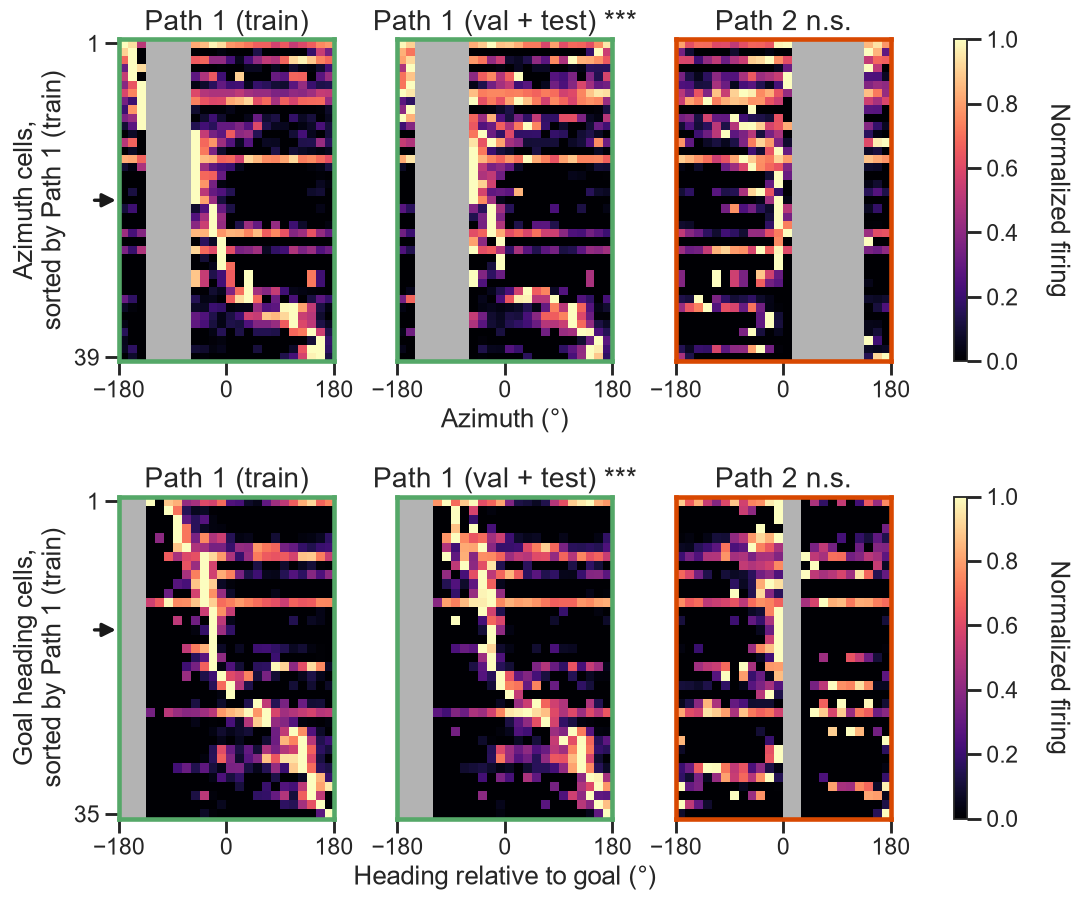

ED Fig 8 — 1_32622_231009 (rew→rew), the Figure 3D panels on two heading axes: Paths 1-2 = clusters [16, 15], Path 1 split 10 train / 9 held out, 24 ring bins over [-180, 180). Cells are per-axis (cross-validated circular tuning), not the 47 place cells of Fig 3D: 39 azimuth, 35 rel.
Peak-heading order vs the Path-1 (train) sort — Fisher-Lee circular rank correlation (one-sided label-permutation p, 2000 iterations):
   axis               panel  n     r stars         P
azimuth Path 1 (val + test) 39 0.399   *** P < 0.001
azimuth              Path 2 39 0.037  n.s. P = 0.144
    rel Path 1 (val + test) 35 0.696   *** P < 0.001
    rel              Path 2 35 0.049  n.s. P = 0.105


In [25]:
# [figures.ipynb cell `edfig8_azimuth`]
# === Extended Data Figure 8 — the Figure 3D sequence on the two HEADING axes ===
# Figure 3D draws the place-cell sequence of one route's paths on a normalized-TIME axis,
# sorted by the Path-1 TRAIN map. This figure asks whether that sequence is really just
# inherited from the bat's heading, a behavioural variable that also evolves along a flight.
# Two readings of heading, one row of the same four panels each, on the SAME session, the same
# paths and the same train / held-out split as Figure 3:
#   a  allocentric AZIMUTH -- atan2 of horizontal velocity; it says nothing about where the
#      flight is going, so two paths can differ in it simply by facing different walls
#   b  GOAL HEADING -- the same heading taken relative to the reward feeder the flight lands
#      on (0 deg = flying straight at it, +-180 deg = straight away, +ve = aimed to its left).
#      Both paths of a route end on the same feeder, so this axis is common to them.
# Each row is drawn on the cells whose tuning to THAT axis is cross-validated-significant
# (`_ring_cells` in the Fig 3 cell, i.e. res_mp4['pc_head']), NOT on the place cells: selecting
# cells on a route-progress map and then asking about heading would beg the question.
# Titles carry the Fisher-Lee (1982) CIRCULAR rank correlation of that panel's peak-heading
# order against the Path-1-train order the rows are sorted by, with stars from the same
# label-permutation null as the Spearman rho in Fig 3D. Heading is circular, so a linear rank
# correlation on peak-BIN INDEX would not be rotation invariant (a path straddling the +-180
# deg seam would be distorted); the pairwise-sine statistic below is rank-based AND invariant
# to rotation of either variable. Ring maps, cell sets and both heading definitions come from
# the Fig 3 cell -- nothing here re-derives a Fig 3 quantity.
from scipy.stats import rankdata as _rankdata_az

ED8_SESSION = MP4_SESSION
# Path 1 and Path 2 only: the endpoint-matched pair every Fig 3 test actually runs on. Fig 3D's
# further paths are dropped here -- 3 and 4 end at the OTHER feeder of the route class, so their
# goal heading is anchored to a different reward and they are not a like-for-like control on
# this axis. Raise to see them (`_m4_sel` order = MP4_PATHS).
ED8_N_PATHS = 2
ED8_PATHS = list(_m4_sel[:ED8_N_PATHS])
ED8_ROWS = [('azimuth', 'Azimuth cells,\nsorted by Path 1 (train)', 'Azimuth (°)'),
            ('rel', 'Goal heading cells,\nsorted by Path 1 (train)',
             'Heading relative to goal (°)')]

_ed8_d = session_data_cache[ED8_SESSION]['data']
_ed8_dff = session_data_cache[ED8_SESSION]['df_flights']
_ed8_nu = len(_ed8_d['spike_times']); _ed8_dt = 1.0 / _ed8_d['Fs']
_ed8_ctr = 0.5 * (AP_HEAD_EDGES[:-1] + AP_HEAD_EDGES[1:])   # ring bin centres (radians)


def _ed8_ring_map(fldf, kind):
    """`head_maps` of the Fig 3 cell, outside `_route_example`: per-neuron firing rate
    (spikes/s) over the AP_N_HEAD ring of `kind`, occupancy-normalized, for one set of
    flights. Spike headings are interpolated from the unwrapped per-sample trace and
    re-wrapped. Bins the bat never occupied on these flights come back NaN rather than 0, so
    they are excluded from row-normalization and peak selection and read grey in the heatmap
    (`head_maps` fills them with 0 instead, which only matters for the cell selection)."""
    occ = np.zeros(AP_N_HEAD); sp = np.zeros((_ed8_nu, AP_N_HEAD))
    for _, fr in fldf.iterrows():
        fs, fe = int(fr.f_start), int(fr.f_stop); ft = _ed8_d['t'][fs:fe + 1]
        xyz = _ed8_d['r'][fs:fe + 1]
        h = (_traj_azimuth(xyz) if kind == 'azimuth'
             else _rel_heading(xyz, _future_reward(ED8_SESSION, xyz)))
        ok = np.isfinite(h)
        if ok.sum() < 2:
            continue
        occ += np.histogram(h[ok], bins=AP_HEAD_EDGES)[0] * _ed8_dt
        tk, hk = ft[ok], np.unwrap(h[ok])
        for u in range(_ed8_nu):
            st = _ed8_d['spike_times'][u]; stf = st[(st >= tk[0]) & (st <= tk[-1])]
            if len(stf):
                hs = (np.interp(stf, tk, hk) + np.pi) % (2 * np.pi) - np.pi
                sp[u] += np.histogram(hs, bins=AP_HEAD_EDGES)[0]
    rate = np.full((_ed8_nu, AP_N_HEAD), np.nan)
    _occd = occ > 0
    rate[:, _occd] = sp[:, _occd] / occ[_occd]
    return rate


def _circ_rank_corr(a, b):
    """Fisher-Lee circular rank correlation between two sets of angles (radians): replace each
    cell's peak heading by its circular rank (uniform score C_i = 2*pi*rank_i/n) and correlate
    the two paths through r = sum_ij sin(C_i-C_j) sin(D_i-D_j) / sqrt(sum sin^2 . sum sin^2)."""
    n = len(a)
    Ca = 2 * np.pi * _rankdata_az(a, method='average') / n
    Cb = 2 * np.pi * _rankdata_az(b, method='average') / n
    sA = np.sin(Ca[:, None] - Ca[None, :]); sB = np.sin(Cb[:, None] - Cb[None, :])
    den = np.sqrt((sA ** 2).sum() * (sB ** 2).sum())
    return float((sA * sB).sum() / den) if den > 0 else np.nan


# --- the four flight sets, i.e. Figure 3D's four panels ------------------------------------
# `_route_example` shuffles Path 1's flights with random_state=seed_ and splits 50 / 25 / 25
# into train / valid / test, then sorts on train and holds out valid+test. That split is
# reconstructed here rather than assumed: the assert rebuilds the held-out normalized-time map
# and requires it to match the one `res_mp4` actually used.
_ed8_ref_all = (_ed8_dff[_ed8_dff.cluster_id == res_mp4['REF']]
               .sample(frac=1.0, random_state=1).reset_index(drop=True))
_ed8_tr = _ed8_ref_all.iloc[:int(round(0.5 * len(_ed8_ref_all)))]
_ed8_held = _ed8_ref_all.iloc[int(round(0.5 * len(_ed8_ref_all))):]
_ed8_split_err = float(np.abs(_m4_rate(_ed8_d, _ed8_held, _tc) - res_mp4['ref_time']).max())
assert _ed8_split_err < 1e-9, (
    f'the reconstructed Path-1 train/held-out split disagrees with res_mp4 by '
    f'{_ed8_split_err:.2e} — `_route_example` must have been called with seed_ != 1')

_ed8_sets = ([('Path 1 (train)', _ed8_tr, MP4_COLORS[0]),
             ('Path 1 (val + test)', _ed8_held, MP4_COLORS[0]),
             ('Path 2', _ed8_dff[_ed8_dff.cluster_id == res_mp4['ALT']], MP4_COLORS[1])]
            + [(f'Path {_i + 3}', _ed8_dff[_ed8_dff.cluster_id == _c], MP4_COLORS[_i + 2])
               for _i, _c in enumerate(ED8_PATHS[2:])])

# --- ring maps, sort order and the per-panel circular rank correlation ---------------------
_ed8_maps, _ed8_order, _ed8_cells, _ed8_tests = {}, {}, {}, []
for _ri, (_kind, _ylab, _xlab) in enumerate(ED8_ROWS):
    _cells = np.asarray(res_mp4['pc_head'][_kind], dtype=int)
    _ed8_cells[_kind] = _cells
    _ed8_maps[_kind] = [_ed8_ring_map(_fl, _kind) for _, _fl, _ in _ed8_sets]
    _ed8_order[_kind] = _cells
    if not len(_cells):
        continue
    # sorted by the Path-1 TRAIN peak (nanargmax over occupied bins only), exactly as Fig 3D
    # sorts its rows by the Path-1 train peak TIME
    _ed8_order[_kind] = _cells[np.argsort(np.nanargmax(_ed8_maps[_kind][0][_cells], axis=1))]
    _ref_pk = _ed8_ctr[np.nanargmax(_ed8_maps[_kind][0][_cells], axis=1)]
    for _pi, ((_name, _, _), _M) in enumerate(zip(_ed8_sets, _ed8_maps[_kind])):
        if _pi == 0:                    # the panel the sort comes from: r = 1 by construction
            _ed8_tests.append(dict(axis=_kind, panel=_name, n=len(_cells), r=1.0, p=None))
            continue
        _y = _ed8_ctr[np.nanargmax(_M[_cells], axis=1)]
        _r = _circ_rank_corr(_ref_pk, _y)
        # one generator per (axis, panel), so a panel's P does not depend on how many panels
        # precede it: adding or dropping a path leaves every other test's null untouched
        _rng_p = np.random.default_rng([1, _ri, _pi])
        _nul = [_circ_rank_corr(_ref_pk, _rng_p.permutation(_y)) for _ in range(AP_N_SHUF_SEQ)]
        _ed8_tests.append(dict(axis=_kind, panel=_name, n=len(_cells), r=round(_r, 3),
                              p=float((1 + np.sum(np.asarray(_nul) >= _r)) / (len(_nul) + 1))))

# --- canvas: one row per heading axis, Figure 3D's four panels across ----------------------
_ed8_cmap = plt.get_cmap('magma').copy(); _ed8_cmap.set_bad('0.7')  # unoccupied ring bins -> grey
_ed8_np = len(_ed8_sets)
_ed8_star = {(t['axis'], t['panel']): t for t in _ed8_tests}
fig_ed8 = plt.figure(figsize=(3.35 * _ed8_np + 1.2, 4.6 * len(ED8_ROWS)))
_gs8 = fig_ed8.add_gridspec(len(ED8_ROWS), 1, hspace=0.42)

for _ri, (_kind, _ylab, _xlab) in enumerate(ED8_ROWS):
    _order = _ed8_order[_kind]
    # wspace 0.45, far above Fig 3D's 0.14: the +-180 edge labels are much wider than its
    # 0 / 0.5 / 1, and wspace is a fraction of the AVERAGE column width, which the two thin
    # colourbar columns drag well below a panel's own width
    _hg = _gs8[_ri].subgridspec(1, _ed8_np + 2, width_ratios=[1] * _ed8_np + [0.06, 0.22],
                                wspace=0.45)
    _axes = [fig_ed8.add_subplot(_hg[0, _i]) for _i in range(_ed8_np)]
    _cax = fig_ed8.add_subplot(_hg[0, _ed8_np])
    for _k, ((_name, _fl, _col), _M) in enumerate(zip(_ed8_sets, _ed8_maps[_kind])):
        _ax = _axes[_k]
        _ax.set_facecolor('0.7')   # backstop so masked NaN cells read grey, not white
        _H = (_M[_order] / np.maximum(np.nanmax(_M[_order], axis=1, keepdims=True), 1e-9)
              if len(_order) else _M[:0])
        sns.heatmap(_H, ax=_ax, cmap=_ed8_cmap, vmin=0, vmax=1, cbar=False,
                    xticklabels=False, yticklabels=False)
        _t = _ed8_star.get((_kind, _name))
        _ax.set_title(_name if _t is None or _t['p'] is None
                      else f"{_name} {ph.stars_for_p(_t['p']) or 'n.s.'}")
        for _sp in _ax.spines.values():        # frame each panel in its path colour, as Fig 3D
            _sp.set_visible(True); _sp.set_color(_col); _sp.set_linewidth(3.0)
        _ax.set_xticks([0, AP_N_HEAD / 2, AP_N_HEAD])
        _ax.set_xticklabels(['−180', '0', '180'], rotation=0)
        _ax.set_xlabel(_xlab if _k == _ed8_np // 2 else '')  # one x label per row, in the middle
        if _k == 0 and len(_order):
            _ax.set_ylabel(_ylab)
            _ax.set_yticks([0.5, len(_order) - 0.5])
            _ax.set_yticklabels(['1', str(len(_order))], rotation=0)
        else:
            _ax.set_ylabel('')
    _row = np.where(np.asarray(_order) == MP4_UNITS[0])[0]
    if len(_row):                              # arrowhead on Fig 3's highlighted unit
        _axes[0].annotate('', xy=(0, _row[0] + 0.5), xytext=(-18, 0), textcoords='offset points',
                          xycoords='data', va='center', annotation_clip=False, zorder=6,
                          arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2))
    if len(_order):
        _cb = fig_ed8.colorbar(_axes[-1].collections[0], cax=_cax)
        _cb.set_label('Normalized firing', rotation=270, labelpad=18, va='bottom')
    else:
        _cax.axis('off')

ph.save_fig(fig_ed8, 'edfig8_azimuth'); plt.show()

print(f'ED Fig 8 — {ED8_SESSION[8:]} ({MP4_ROUTE}), the Figure 3D panels on two heading axes: '
      f'Paths 1-{len(ED8_PATHS)} = clusters {ED8_PATHS}, Path 1 split {len(_ed8_tr)} train / '
      f'{len(_ed8_held)} held out, {AP_N_HEAD} ring bins over [-180, 180). Cells are per-axis '
      f'(cross-validated circular tuning), not the {res_mp4["n_place"]} place cells of Fig 3D: '
      + ', '.join(f'{len(v)} {k}' for k, v in _ed8_cells.items()) + '.')
print('Peak-heading order vs the Path-1 (train) sort — Fisher-Lee circular rank correlation '
      f'(one-sided label-permutation p, {AP_N_SHUF_SEQ} iterations):')
print(pd.DataFrame([t for t in _ed8_tests if t['p'] is not None])
      .assign(stars=lambda d: d['p'].map(lambda p: ph.stars_for_p(p) or 'n.s.'),
              P=lambda d: d['p'].map(ph.fmt_p))[['axis', 'panel', 'n', 'r', 'stars', 'P']]
      .to_string(index=False))

*Paper legend; this panel depends on recorded data only and matches the paper.*

**Extended Data Fig. 8 | Generalization of place-cell sequences is not inherited from flight heading.** (A) Firing-rate sequences on an azimuth axis (horizontal flight heading, 24 bins spanning $-180$ to $180^\circ$) rather than normalized flight progress, on the Path 1 training flights (*left*), the held-out Path 1 validation + test flights (*middle*) and all Path 2 flights (*right*) of Fig. 3. Rows are the $n$ = 39 azimuth-tuned cells. Grey bins were never occupied on those flights and are excluded from normalization and peak selection. The arrowhead marks the example unit of Fig. 3B,C. Panel titles carry the Fisher–Lee circular rank correlation between that panel's azimuth-peak order and the Path-1-training order the rows are sorted by, against a label-permutation null. Azimuth-peak order is preserved within Path 1 (train vs. held-out $r$ = 0.399, $P = 5.00 \times 10^{-4}$) but not between Path 1 and Path 2 ($r$ = 0.037, $P$ = 0.14) — the opposite of the normalized-flight-progress result in Fig. 3D, I. (B) As (A), for goal heading on $n$ = 35 goal-heading-tuned cells. Both paths land on the same feeder, so this axis is common to them; nevertheless goal-heading-peak order is again preserved within Path 1 ($r$ = 0.696, $P = 5.00 \times 10^{-4}$) and not between Path 1 and Path 2 ($r$ = 0.049, $P$ = 0.10). Permutation tests use 2,000 iterations. See also Fig. 3.

---
## What cannot be reproduced from this repository and the demo session

Every figure not listed below aggregates over sessions that are not public. The data are available
from the corresponding author on reasonable request. The models and results behind those figures
are committed under `notebooks/out/`, and [`figures.ipynb`](figures.ipynb) redraws them once all 17
sessions are available.

| Figure | Reproducible here? |
|---|---|
| Fig. 1 | **Partly.** B–F above give this session's values: from the paper's models with `'paper'`, otherwise from single-session models. The paper pools 17 sessions, and its B and D examples come from other sessions. H (transfer to held-out sessions) needs all 17 sessions. |
| Fig. 2 | **No.** Latent geometry, RSA and DMD pooled over 17 sessions. |
| Fig. 3 | **A–I exactly in every mode; J–L exactly with `'paper'`** (L–M then add the other sessions from the paper's committed results). With single-session models, J–M are this session's version. |
| Fig. 4 | **No.** Readout weights pooled over 17 sessions. F and H also need sleep recordings matched with UnitMatch. |
| Extended Data Fig. 1 | **No.** Encoder and decoder ladders (14 encoders, 12 decoders) pooled over 17 sessions. |
| Extended Data Fig. 2 | **No.** Surrogate-trained controls pooled over 17 sessions. |
| Extended Data Fig. 3 | **No.** Context-window and data-scaling sweeps retrain the Twin on 17 sessions (`training/`). |
| Extended Data Figs. 4–7 | **No.** Flight-axis fit, latent geometry, RSA and DMD pooled over sessions. |
| Extended Data Fig. 8 | **Yes, exactly** (above). |
| Extended Data Fig. 9 | **No.** Its examples are from sessions 231010 and 14445_231209. |
| Extended Data Fig. 10 | **No.** Pooled readout clusters. |
| Table S1 | **No.** Masking-scheme sweep over 17 sessions. |